# Stars, words and friends: forecasting Yelp ratings with text and social networks

**Analysis of Complex Data, final project.** Data: Yelp Open Dataset, subset `state == "CA"`, which in practice is the **Santa Barbara metropolitan area**.

**Main question.** *Can the ratings of a business be forecast, and does the social network of its reviewers add anything beyond the rating history and the text of the reviews?*

| Assessment criterion | Where |
|---|---|
| (i) Data processing and analysis | Sections 1-2 |
| (ii) Recommender system, with evaluation | Section 6 |
| (iii) Text processing techniques | Section 3 |
| (iv) Advanced sentiment analysis | Section 4 (aspect-based sentiment, model benchmark, sentiment-star gap) |
| (v) Social network and extracted knowledge | Section 5 |
| (vi) Time series, with evaluation | Section 7 |
| (vii) Integration of network and time series | Sections 8-9 |
| (viii) Creativity and complexity | Influence tests, event study, yearly networks, change points, self-excitation, COVID (Sections 5, 8, 9) |

**Rules used throughout**

* **No look-ahead.** Everything is split by time. A feature for a forecast only uses reviews written before the forecast date.
* **A review's own sentiment is never an input for its own stars**, because the text nearly reveals the rating. Sentiment enters forecasts only through *earlier* reviews.
* **A baseline comes first.** A model counts only if it beats a simple baseline on data it has not seen.
* **Association is not causation.** Friends may rate alike because of influence, because of similar tastes, or because they visit together. Each test states which explanations it can and cannot exclude.

**Running the notebook.** Slow steps save their results in `acd_cache/`, so a second run takes minutes. Add a step's name to `RECOMPUTE` to run it again. A first run takes about 2-3 hours on a 12-thread CPU without a GPU.

## 0. Setup

In [1]:
import gc
import itertools
import os
import re
import time
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.sparse as sp
from scipy import stats
from joblib import Parallel, delayed

try:
    from IPython.display import display
except ImportError:
    display = print
if "get_ipython" not in globals():                       # plain script: show whole tables
    pd.set_option("display.width", 220, "display.max_columns", 40, "display.max_rows", 80)

warnings.filterwarnings("ignore")
os.environ.setdefault("TOKENIZERS_PARALLELISM", "false")
sns.set_theme(style="whitegrid")
plt.rcParams.update({"figure.dpi": 110, "axes.titlesize": 11, "axes.titleweight": "bold", "font.size": 9})

SEED = 42
N_JOBS = 4                                               # parallel processes for the text steps (raise it with plenty of RAM)
CACHE = Path("acd_cache"); CACHE.mkdir(exist_ok=True)
FIG = Path("figures_acd"); FIG.mkdir(exist_ok=True)
RECOMPUTE = set()                                        # names of cached steps to run again, e.g. {"lr_sentiment"}
RESULTS = {}                                             # result tables, exported at the end

# time cuts
TEXT_TRAIN_END = pd.Timestamp("2017-01-01")              # sentiment models learn only from earlier reviews
REC_TRAIN_END = pd.Timestamp("2018-01-01")               # recommender: train before, test in 2018-2019
REC_TEST_END = pd.Timestamp("2020-01-01")
COVID_START = pd.Timestamp("2020-03-01")
LAST_FULL_MONTH = pd.Timestamp("2021-12-31")             # January 2022 is incomplete

ASPECTS = ["food", "service", "price", "ambience", "wait", "clean"]
ASP_COLS = [f"asp_{a}" for a in ASPECTS]


def cached(name, fn):
    """Load table `name` from the cache, or compute it with fn() and store it."""
    path = CACHE / f"{name}.parquet"
    if path.exists() and name not in RECOMPUTE:
        return pd.read_parquet(path)
    t0 = time.time()
    df = fn()
    df.to_parquet(path)
    print(f"[{name}] computed in {time.time() - t0:.0f} s")
    return df


def savefig(name):
    plt.tight_layout()
    plt.savefig(FIG / f"{name}.png", dpi=140, bbox_inches="tight")
    plt.show()
    plt.close()


def ols_cluster(y, X, groups):
    """OLS with standard errors clustered on `groups`; X is a DataFrame."""
    import statsmodels.api as sm
    return sm.OLS(np.asarray(y, float), sm.add_constant(X, has_constant="add")).fit(
        cov_type="cluster", cov_kwds={"groups": pd.factorize(groups)[0]})


def within(df, cols, by):
    """Subtract group means (fixed effects). `by` is a list of grouping columns, removed one after the other."""
    out = df[cols].astype(float).copy()
    for _ in range(3 if len(by) > 1 else 1):             # alternating projections for several fixed effects
        for g in by:
            out = out - out.groupby(df[g].values).transform("mean")
    return out

## 1. Data

**Subset.** Reviews of businesses with `state == "CA"` and the users who wrote them. The three parquet files are recreated from the Yelp JSON files if they are missing.

**Cleaning.** City names are unified, businesses outside the area are removed (cities with fewer than 20 businesses, such as Reno or Truckee), negative vote counts are set to 0, and each business gets one macro category. Two details of this dataset matter:

* The Elite list writes the year 2020 as `20,20`. This is repaired, so that Elite status can be checked **at the time of each review**.
* Only *network* structure is taken from the user file. Its counters (`review_count`, `fans`, `average_stars`) describe the user at the end of the data, so they would leak the future into forecasts and are not used as forecast inputs. Names are not loaded.

In [2]:
def build_ca_subset():
    """Filter the Yelp JSON files to California (only runs if the parquet files are missing)."""
    biz = pd.read_json("yelp_academic_dataset_business.json", lines=True)
    biz = biz[biz["state"] == "CA"]
    keep = set(biz["business_id"])
    rev = pd.concat(c[c["business_id"].isin(keep)]
                    for c in pd.read_json("yelp_academic_dataset_review.json", lines=True, chunksize=100_000))
    uids = set(rev["user_id"])
    usr = pd.concat(c[c["user_id"].isin(uids)]
                    for c in pd.read_json("yelp_academic_dataset_user.json", lines=True, chunksize=100_000))
    biz.to_parquet("yelp_ca_business.parquet", index=False)
    rev.to_parquet("yelp_ca_review.parquet", index=False)
    usr.to_parquet("yelp_ca_user.parquet", index=False)


if not Path("yelp_ca_review.parquet").exists():
    build_ca_subset()

MACRO = [("Restaurants", "Restaurants"), ("Nightlife & Bars", "Nightlife|Bars"), ("Food (other)", "Food"),
         ("Beauty & Spas", "Beauty"), ("Health & Medical", "Health|Medical"), ("Hotels & Travel", "Hotels|Travel"),
         ("Arts & Entertainment", "Arts|Entertainment"), ("Active Life", "Active Life"), ("Automotive", "Automotive"),
         ("Shopping", "Shopping"), ("Home & Local Services", "Home Services|Local Services|Professional")]


def macro_category(cat):
    if not isinstance(cat, str):
        return "Other"
    for name, pat in MACRO:
        if re.search(pat, cat):
            return name
    return "Other"


biz = pd.read_parquet("yelp_ca_business.parquet",
                      columns=["business_id", "name", "city", "latitude", "longitude", "categories", "is_open"])
biz["city"] = biz["city"].str.strip().str.replace(r"\s+", " ", regex=True).str.title().replace({"Santa Barbra": "Santa Barbara"})
biz = biz[biz["city"].map(biz["city"].value_counts()) >= 20].reset_index(drop=True)
biz["macro_cat"] = biz["categories"].map(macro_category)
biz["b"] = np.arange(len(biz))

rev = pd.read_parquet("yelp_ca_review.parquet")
n_raw = len(rev)
rev = rev.drop_duplicates("review_id")
rev = rev[rev["business_id"].isin(biz["business_id"])].sort_values("date").reset_index(drop=True)
rev[["useful", "funny", "cool"]] = rev[["useful", "funny", "cool"]].clip(lower=0)
rev["b"] = rev["business_id"].map(biz.set_index("business_id")["b"]).astype(np.int32)
uid = pd.Series(np.arange(rev["user_id"].nunique()), index=rev["user_id"].drop_duplicates().values)
rev["u"] = rev["user_id"].map(uid).astype(np.int32)
n_users = len(uid)

TEXT_PATH = CACHE / "review_text.parquet"
if not TEXT_PATH.exists():
    rev[["text"]].to_parquet(TEXT_PATH)
R = rev.drop(columns=["text", "review_id", "business_id", "user_id", "cool", "funny"]).copy()
R["text_len"] = rev["text"].str.split().str.len().astype(np.int32)
del rev; gc.collect()

R["year"] = R["date"].dt.year.astype(np.int16)
R["month"] = R["date"].dt.to_period("M").dt.to_timestamp()
R["q"] = R["date"].dt.to_period("Q")
R["day"] = ((R["date"].dt.normalize() - pd.Timestamp("2000-01-01")).dt.days).astype(np.int32)
R["macro_cat"] = R["b"].map(biz["macro_cat"]).astype("category")
R["city"] = R["b"].map(biz["city"]).astype("category")
print(f"Reviews {n_raw:,} -> {len(R):,} | businesses {len(biz):,} | users {n_users:,} | "
      f"{R['date'].min():%Y-%m} to {R['date'].max():%Y-%m}")

Reviews 348,856 -> 348,014 | businesses 5,164 | users 155,252 | 2005-03 to 2022-01


In [3]:
def load_users():
    """Users (ids mapped to 0..n-1), Elite years and the friendship edges among subset users."""
    import pyarrow.parquet as pq
    cols = ["user_id", "friends", "yelping_since", "elite"]
    rows, edges, elite_rows = [], [], []
    for batch in pq.ParquetFile("yelp_ca_user.parquet").iter_batches(batch_size=20_000, columns=cols):
        d = batch.to_pandas()
        d["u"] = d["user_id"].map(uid)
        d = d.dropna(subset=["u"])
        d["u"] = d["u"].astype(np.int64)
        rows.append(d[["u", "yelping_since"]])
        el = d[d["elite"].fillna("").str.len() > 0]
        for u, s in zip(el["u"].values, el["elite"].values):
            for y in re.findall(r"\d{4}", s.replace("20,20", "2020")):
                elite_rows.append((u, int(y)))
        fr = d[~d["friends"].isin(["None", ""])]
        ex = fr.assign(f=fr["friends"].str.split(r",\s*")).explode("f")
        v = ex["f"].map(uid)
        ok = v.notna()
        edges.append(np.column_stack([ex["u"].values[ok], v[ok].astype(np.int64).values]))
    U = pd.concat(rows, ignore_index=True).sort_values("u").reset_index(drop=True)
    E = np.vstack(edges)
    E = E[E[:, 0] != E[:, 1]]
    E = np.unique(np.sort(E, axis=1), axis=0)            # undirected, each edge once
    return U, pd.DataFrame(elite_rows, columns=["u", "year"]).drop_duplicates(), pd.DataFrame(E, columns=["a", "b"])


if all((CACHE / f"{n}.parquet").exists() for n in ("users", "elite", "edges")) and "users" not in RECOMPUTE:
    USERS, ELITE, EDGES = [pd.read_parquet(CACHE / f"{n}.parquet") for n in ("users", "elite", "edges")]
else:
    USERS, ELITE, EDGES = load_users()
    USERS.to_parquet(CACHE / "users.parquet"); ELITE.to_parquet(CACHE / "elite.parquet"); EDGES.to_parquet(CACHE / "edges.parquet")

USERS["join_year"] = pd.to_datetime(USERS["yelping_since"]).dt.year
R["elite_now"] = pd.MultiIndex.from_arrays([R["u"], R["year"]]).isin(pd.MultiIndex.from_frame(ELITE[["u", "year"]]))
A = sp.csr_matrix((np.ones(len(EDGES) * 2, dtype=np.float32),
                   (np.r_[EDGES["a"], EDGES["b"]], np.r_[EDGES["b"], EDGES["a"]])), shape=(n_users, n_users))
deg = np.asarray(A.sum(1)).ravel().astype(np.int32)
R["deg"] = deg[R["u"].values]
print(f"Friendship edges inside the subset: {len(EDGES):,} | users with a friend: {(deg > 0).mean():.1%} | "
      f"reviews by users with a friend: {(R['deg'] > 0).mean():.1%} | reviews written as Elite: {R['elite_now'].mean():.1%}")

Friendship edges inside the subset: 471,089 | users with a friend: 41.3% | reviews by users with a friend: 55.4% | reviews written as Elite: 12.5%


## 2. Exploratory analysis

The EDA concentrates on what shapes the modelling choices: how much data each business has, how the ratings behave over time, and how long the reviews are. Stars are J-shaped, with far more 5-star than middling reviews, which is typical of voluntary reviews. A very long tail means that most users and businesses have little data, which matters for both the recommender and the forecast.

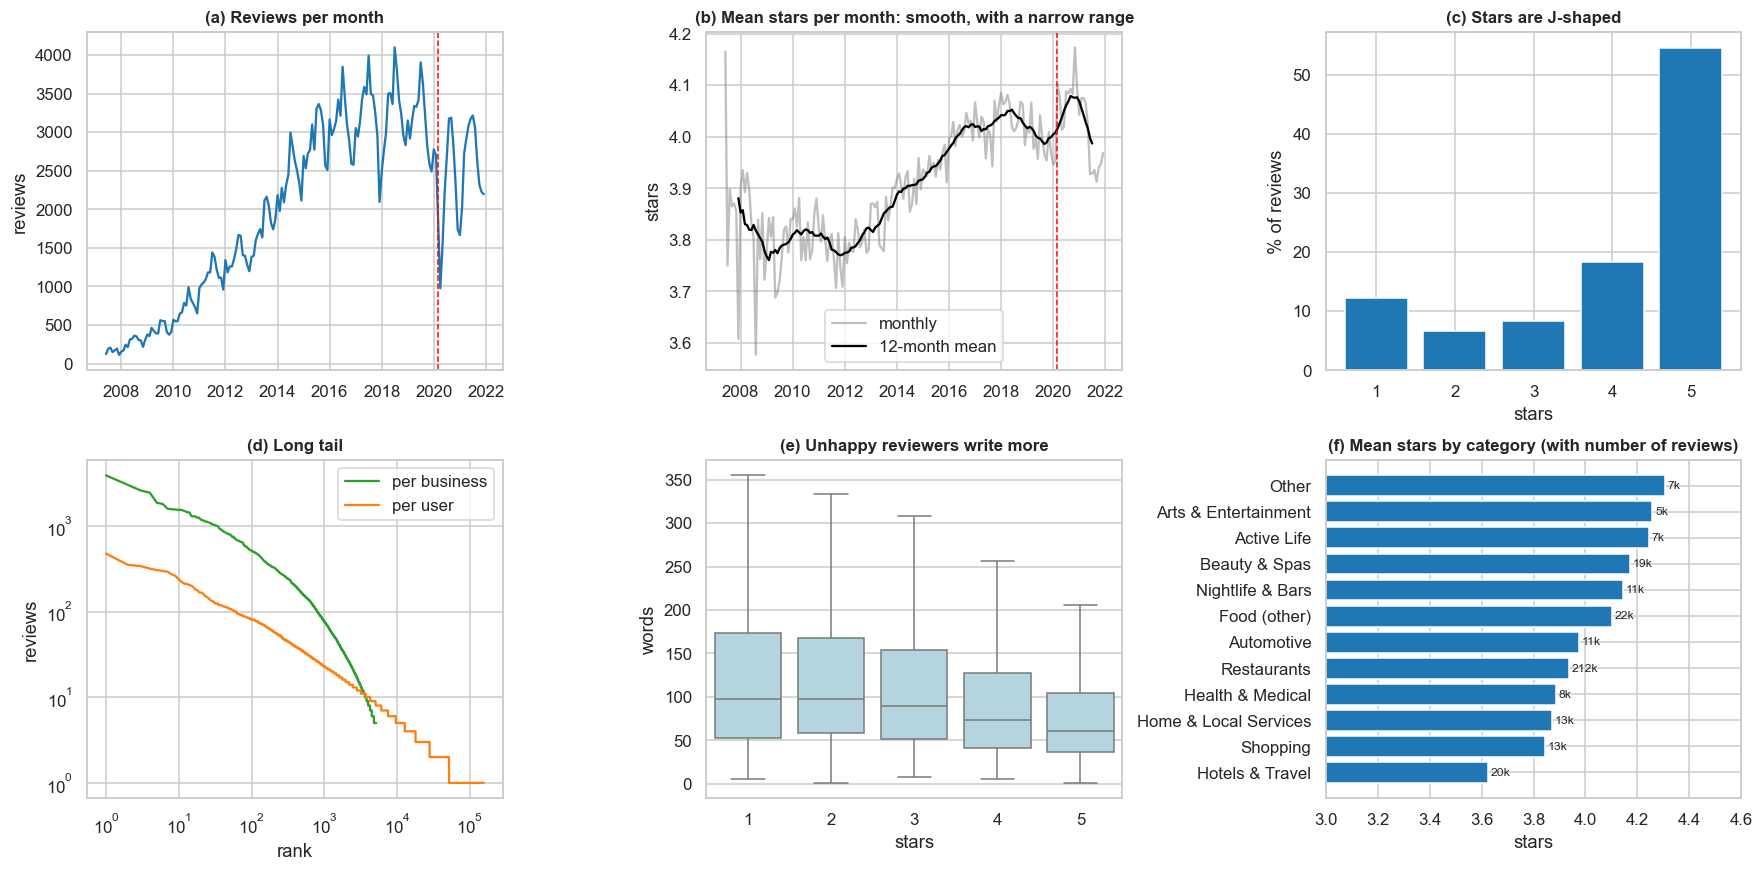

,value
Reviews,"348,014"
Businesses,"5,164"
Users,"155,252"
Mean / median stars,3.96 / 5
Median reviews per business / per user,20 / 1
Users with one review in the subset,66.7%
Businesses with at least 100 reviews,802 (70% of reviews)
Median words per review,71


,share of the variance of stars
between businesses,0.206
between users (users with 5+ reviews),0.264


In [4]:
fig, ax = plt.subplots(2, 3, figsize=(16, 8))
m = R[R["date"] <= LAST_FULL_MONTH].groupby("month")["stars"].agg(["size", "mean"])
m = m[m.index >= "2007-06-01"]
ax[0, 0].plot(m.index, m["size"], color="tab:blue"); ax[0, 0].set(title="(a) Reviews per month", ylabel="reviews")
ax[0, 0].axvline(COVID_START, color="red", ls="--", lw=1)
ax[0, 1].plot(m.index, m["mean"], color="grey", alpha=.5, label="monthly")
ax[0, 1].plot(m.index, m["mean"].rolling(12, center=True).mean(), color="black", label="12-month mean")
ax[0, 1].axvline(COVID_START, color="red", ls="--", lw=1); ax[0, 1].legend()
ax[0, 1].set(title="(b) Mean stars per month: smooth, with a narrow range", ylabel="stars")
s = R["stars"].value_counts(normalize=True).sort_index() * 100
ax[0, 2].bar(s.index, s.values, color="tab:blue"); ax[0, 2].set(title="(c) Stars are J-shaped", xlabel="stars", ylabel="% of reviews")
for name, col, c in (("per business", "b", "tab:green"), ("per user", "u", "tab:orange")):
    vc = R[col].value_counts().values
    ax[1, 0].loglog(np.arange(1, len(vc) + 1), vc, color=c, label=name)
ax[1, 0].set(title="(d) Long tail", xlabel="rank", ylabel="reviews"); ax[1, 0].legend()
sns.boxplot(data=R.sample(40_000, random_state=SEED), x="stars", y="text_len", showfliers=False, ax=ax[1, 1], color="lightblue")
ax[1, 1].set(title="(e) Unhappy reviewers write more", ylabel="words")
c = R.groupby("macro_cat", observed=True)["stars"].agg(["size", "mean"]).sort_values("mean")
ax[1, 2].barh(c.index, c["mean"], color="tab:blue"); ax[1, 2].set_xlim(3, 4.6)
for i, (n, v) in enumerate(zip(c["size"], c["mean"])):
    ax[1, 2].text(v + .01, i, f"{n / 1000:.0f}k", va="center", fontsize=8)
ax[1, 2].set(title="(f) Mean stars by category (with number of reviews)", xlabel="stars")
savefig("eda_overview")

rb, ru = R["b"].value_counts(), R["u"].value_counts()
display(pd.Series({"Reviews": f"{len(R):,}", "Businesses": f"{len(biz):,}", "Users": f"{n_users:,}",
                   "Mean / median stars": f"{R['stars'].mean():.2f} / {R['stars'].median():.0f}",
                   "Median reviews per business / per user": f"{rb.median():.0f} / {ru.median():.0f}",
                   "Users with one review in the subset": f"{(ru == 1).mean():.1%}",
                   "Businesses with at least 100 reviews": f"{(rb >= 100).sum():,} ({rb[rb >= 100].sum() / len(R):.0%} of reviews)",
                   "Median words per review": f"{R['text_len'].median():.0f}"}, name="value").to_frame())

# variance of the stars: how much belongs to the business, how much to the user?
tot = R["stars"].var()
frequent = R[R["u"].isin(ru[ru >= 5].index)]
display(pd.Series({"between businesses": R.groupby("b")["stars"].transform("mean").var() / tot,
                   "between users (users with 5+ reviews)": frequent.groupby("u")["stars"].transform("mean").var() / frequent["stars"].var()},
                  name="share of the variance of stars").round(3).to_frame())

**What this tells us.** Volume grew until about 2018 and fell sharply with COVID. Mean stars move slowly and in a narrow band, so an overall stars series has little to forecast: this is why the main forecast in Section 7 works at the level of businesses. Businesses and users each explain only about a fifth to a quarter of the variance of a single rating, so individual reviews are noisy. Any forecast of a rating will have a limited ceiling, which Section 7 estimates.

## 3. Text processing

**Pipeline.** Normalise the text (case, URLs, whitespace), filter by language, tokenise, and turn the text into features. Instead of assuming which preprocessing steps help, they are **tested**: each variant trains the same classifier on reviews from before 2017 and predicts reviews from 2017-2018.

| Variant | What changes |
|---|---|
| Counts, unigrams | baseline bag of words |
| TF-IDF, unigrams | term weighting |
| + stop-word removal | common words removed, *including "not"* |
| + lemmas (spaCy) | "tasted", "tastes" -> "taste" |
| + bigrams | "not good", "highly recommend" |
| + bigrams and negation tags | "not good" -> `not_good`, so that negation carries over to the next word |

In [5]:
TXT = pd.read_parquet(TEXT_PATH)["text"]
URL = re.compile(r"https?://\S+|www\.\S+")
SPACE = re.compile(r"\s+")
TOKEN = re.compile(r"[a-z']+")
NEG = re.compile(r"\b(not|no|never|without|hardly|isn't|wasn't|aren't|weren't|don't|didn't|doesn't|won't|can't|couldn't|wouldn't|shouldn't)\s+([a-z']+)")
STOP_EN = set("the and a to i was of it for is in that my we they this with you on but have had not at were are so be".split())
STOP_OTHER = set("de la el que y los las un una por para con muy der die und das ist nicht wir ich sehr ein eine le les des et est pour dans une il pas nous per che di il sono".split())


def normalise(t):
    return SPACE.sub(" ", URL.sub(" ", t.lower())).strip()


def mark_negation(t):
    return NEG.sub(lambda m: f"{m.group(1)} not_{m.group(2)}", t)


def looks_english(t):
    """A review is flagged only if words common in Spanish, German, French or Italian outnumber common English words."""
    tok = TOKEN.findall(t.lower())
    other = sum(w in STOP_OTHER for w in tok)
    return not tok or other <= sum(w in STOP_EN for w in tok) or other / len(tok) < .1


R["is_en"] = TXT.map(looks_english).values
print(f"Reviews that do not look English (kept out of the text models): {(~R['is_en']).sum():,} ({(~R['is_en']).mean():.2%})")
for t in TXT[~R["is_en"].values].sample(3, random_state=1):
    print("   ", t[:90].replace("\n", " "))

Reviews that do not look English (kept out of the text models): 355 (0.10%)
    Muchas gracias doctor , David McAninch y personal por su amabilidad y trabajo espectacular
    El ambiente y el servicio es espectacular! Muy lindo lugar. Creo que le erramos en lo que 
    Si vous pouvez aller ailleurs, allez y!!!  Aucun sens du service, accueille froide limite 


In [6]:
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS, CountVectorizer, TfidfVectorizer
from sklearn.linear_model import LogisticRegression, Ridge, SGDClassifier
from sklearn.metrics import accuracy_score, cohen_kappa_score, confusion_matrix, f1_score, mean_absolute_error
from sklearn.model_selection import KFold
from sklearn.preprocessing import normalize

STAR_CLASSES = np.arange(1, 6)


def three_class(s):
    """negative = 1-2 stars, neutral = 3, positive = 4-5"""
    return np.where(np.asarray(s) <= 2.5, 0, np.where(np.asarray(s) < 3.5, 1, 2))


def text_metrics(y, proba_or_expected, classes3=None):
    """Quality of a text model, on the same scale for every method."""
    exp = np.asarray(proba_or_expected)
    return {"macro_F1_3class": f1_score(three_class(y), three_class(exp) if classes3 is None else classes3, average="macro"),
            "accuracy_3class": accuracy_score(three_class(y), three_class(exp) if classes3 is None else classes3),
            "MAE_stars": mean_absolute_error(y, exp), "Spearman": stats.spearmanr(y, exp)[0]}


def sgd():
    return SGDClassifier(loss="log_loss", alpha=2e-6, max_iter=8, tol=None, average=True, random_state=SEED, n_jobs=5)


def lemmatise_sample(ids):
    import spacy
    nlp = spacy.load("en_core_web_sm", disable=["parser", "ner"])
    texts = [normalise(t)[:3000] for t in TXT.loc[ids]]
    out = [" ".join(w.lemma_ for w in doc if not w.is_punct and not w.is_space) for doc in nlp.pipe(texts, batch_size=256)]
    return pd.DataFrame({"lemma": out}, index=ids)


rng = np.random.default_rng(SEED)
en = R["is_en"].values
tr_ids = rng.choice(np.flatnonzero((R["date"] < TEXT_TRAIN_END).values & en), 30_000, replace=False)
te_ids = rng.choice(np.flatnonzero((R["date"] >= TEXT_TRAIN_END).values & (R["date"] < "2019-01-01").values & en), 10_000, replace=False)
lem = cached("lemmas", lambda: lemmatise_sample(np.r_[tr_ids, te_ids]))["lemma"]
base = dict(min_df=3, max_df=.6, dtype=np.float32)
norm_tr, norm_te = TXT.loc[tr_ids].map(normalise), TXT.loc[te_ids].map(normalise)
y_tr, y_te = R["stars"].values[tr_ids], R["stars"].values[te_ids]

VARIANTS = {
    "Counts, unigrams": (CountVectorizer(binary=True, **base), norm_tr, norm_te),
    "TF-IDF, unigrams": (TfidfVectorizer(sublinear_tf=True, **base), norm_tr, norm_te),
    "TF-IDF + stop-word removal": (TfidfVectorizer(sublinear_tf=True, stop_words="english", **base), norm_tr, norm_te),
    "TF-IDF + lemmas": (TfidfVectorizer(sublinear_tf=True, **base), lem.loc[tr_ids], lem.loc[te_ids]),
    "TF-IDF + bigrams": (TfidfVectorizer(sublinear_tf=True, ngram_range=(1, 2), **base), norm_tr, norm_te),
    "TF-IDF + bigrams + negation tags": (TfidfVectorizer(sublinear_tf=True, ngram_range=(1, 2), **base), norm_tr.map(mark_negation), norm_te.map(mark_negation)),
}
rows = []
for name, (vec, a, b) in VARIANTS.items():
    t0 = time.time()
    Xa, Xb = normalize(vec.fit_transform(a)), normalize(vec.transform(b))   # same scale for every variant
    p = sgd().fit(Xa, y_tr).predict_proba(Xb)
    rows.append({"variant": name, **text_metrics(y_te, p @ STAR_CLASSES), "vocabulary": Xa.shape[1], "seconds": time.time() - t0})
RESULTS["text_preprocessing"] = pd.DataFrame(rows).set_index("variant")
display(RESULTS["text_preprocessing"].round(3))
del VARIANTS, norm_tr, norm_te; gc.collect()

,macro_F1_3class,accuracy_3class,MAE_stars,Spearman,vocabulary,seconds
variant,,,,,,
"Counts, unigrams",0.708,0.880,0.430,0.763,17716,1.712
"TF-IDF, unigrams",0.694,0.873,0.448,0.757,17716,1.693
TF-IDF + stop-word removal,0.681,0.866,0.479,0.741,17424,1.501
TF-IDF + lemmas,0.697,0.873,0.455,0.750,13820,1.547
TF-IDF + bigrams,0.728,0.891,0.425,0.780,143867,4.659
TF-IDF + bigrams + negation tags,0.735,0.893,0.419,0.782,145703,5.498


3536

**Reading the table.** Bigrams with negation tags do best (macro-F1 about 0.73, against 0.69 for plain TF-IDF unigrams), and this variant is used in the rest of the notebook. Removing stop words *lowers* quality, because it deletes words such as "not", and lemmas add almost nothing here. Both keep their use elsewhere: they make *topics* readable (Section 4.3), which is a different job from classifying sentiment.

## 4. Sentiment analysis

### 4.1 Which sentiment model? A benchmark on future reviews

Star ratings act as weak labels for the sentiment of a review: 1-2 stars = negative, 3 = neutral, 4-5 = positive. Five approaches are compared on **the same 6,000 reviews written in 2019 or later**:

| Family | Model | Why |
|---|---|---|
| Lexicon | VADER | no training, handles negation and emphasis with rules |
| Supervised | TF-IDF + logistic regression | learns Yelp's own vocabulary from earlier reviews |
| Transfer learning | MiniLM sentence embeddings + logistic regression | pretrained meaning, trained classifier on top |
| Pretrained transformer | DistilBERT (SST-2, movie-review sentences) | off the shelf |
| Pretrained transformer | RoBERTa (Twitter, 3 classes) | off the shelf |

The pretrained models were not built for Yelp or for stars, so each gets a small calibration step (a logistic regression from its output to stars, fitted on 2,000 earlier reviews). All methods then give the same scale: expected stars.

**Coverage.** On this CPU the transformers process 10-70 reviews per second, so they run on samples. VADER and TF-IDF run on all 348k reviews.

**Avoiding a leak.** TF-IDF + LR is trained on reviews before 2017. Reviews from before 2017 get their scores by 5-fold cross-fitting, so no review is scored by a model that saw it. This matters later because these scores become forecast inputs.

In [7]:
def _vader_chunk(texts):
    from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer
    sia = SentimentIntensityAnalyzer()
    return [sia.polarity_scores(t)["compound"] for t in texts]


def compute_vader():
    chunks = np.array_split(TXT.values, N_JOBS * 8)
    res = Parallel(n_jobs=N_JOBS)(delayed(_vader_chunk)(list(c)) for c in chunks)
    return pd.DataFrame({"vader": np.concatenate(res)}, index=TXT.index)


def compute_lr_sentiment():
    """TF-IDF (1-2 grams, negation tags) + logistic regression: expected stars, out of sample for every review."""
    docs = TXT.map(lambda t: mark_negation(normalise(t)))
    train = np.flatnonzero((R["date"] < TEXT_TRAIN_END).values & R["is_en"].values)
    vec = TfidfVectorizer(sublinear_tf=True, ngram_range=(1, 2), min_df=5, max_df=.5, max_features=400_000, dtype=np.float32)
    vec.fit(docs.iloc[train])
    X = vec.transform(docs)
    del docs; gc.collect()
    y = R["stars"].values
    out = np.full(len(R), np.nan, dtype=np.float32)
    for k, (a, b) in enumerate(KFold(5, shuffle=True, random_state=SEED).split(train)):
        out[train[b]] = sgd().fit(X[train[a]], y[train[a]]).predict_proba(X[train[b]]) @ STAR_CLASSES
    clf = sgd().fit(X[train], y[train])
    rest = np.setdiff1d(np.arange(len(R)), train)
    out[rest] = clf.predict_proba(X[rest]) @ STAR_CLASSES
    names = np.array(vec.get_feature_names_out())
    w = (clf.coef_[4] - clf.coef_[0])                     # 5 stars against 1 star
    top = np.argsort(w)
    terms = pd.DataFrame({"negative": names[top[:25]], "positive": names[top[::-1][:25]]})
    terms.to_parquet(CACHE / "lr_terms.parquet")
    return pd.DataFrame({"sent_lr": out}, index=TXT.index)


R["vader"] = cached("vader", compute_vader)["vader"].values
R["sent_lr"] = cached("lr_sentiment", compute_lr_sentiment)["sent_lr"].values
R["gap"] = R["sent_lr"] - R["stars"]                     # text more positive (+) or negative (-) than the rating
print("Terms that separate 5-star from 1-star reviews most:")
display(pd.read_parquet(CACHE / "lr_terms.parquet").head(15).T)

Terms that separate 5-star from 1-star reviews most:


,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14
negative,worst,rude,horrible,terrible,one star,awful,not,unprofessional,the worst,disgusting,poor,bad,bland,disappointing,dirty
positive,amazing,great,best,delicious,awesome,excellent,love,perfect,fantastic,wonderful,friendly,the best,favorite,incredible,not_be disappointed


In [8]:
BENCH_IDS = np.random.default_rng(SEED + 1)
pool_old = np.flatnonzero((R["date"] < TEXT_TRAIN_END).values & R["is_en"].values)
pool_new = np.flatnonzero((R["date"] >= "2019-01-01").values & R["is_en"].values)
TEST_IDS = BENCH_IDS.choice(pool_new, 6000, replace=False)
CAL_IDS = BENCH_IDS.choice(pool_old, 2000, replace=False)
EMB_TRAIN_IDS = BENCH_IDS.choice(pool_old, 15_000, replace=False)
TORCH_THREADS = 10


def _batches(texts, tok, bs=32, max_len=128, pairs=None):
    """Sorted by length, which makes the batches smaller and the run faster."""
    order = np.argsort([len(t) for t in texts])
    for s in range(0, len(order), bs):
        idx = order[s:s + bs]
        kw = dict(truncation=True, max_length=max_len, padding=True, return_tensors="pt")
        yield idx, tok([texts[i] for i in idx], [pairs[i] for i in idx], **kw) if pairs is not None else tok([texts[i] for i in idx], **kw)


def transformer_scores(model_name, ids, pairs=None, max_len=128, texts=None):
    """Class probabilities of a classification transformer."""
    import torch
    from transformers import AutoModelForSequenceClassification, AutoTokenizer
    torch.set_num_threads(TORCH_THREADS)
    tok = AutoTokenizer.from_pretrained(model_name)
    model = AutoModelForSequenceClassification.from_pretrained(model_name).eval()
    texts = [TXT.iloc[i][:1500] for i in ids] if texts is None else texts
    out = None
    with torch.no_grad():
        for idx, enc in _batches(texts, tok, max_len=max_len, pairs=pairs):
            p = torch.softmax(model(**enc).logits, dim=1).numpy()
            if out is None:
                out = np.zeros((len(texts), p.shape[1]), dtype=np.float32)
            out[idx] = p
    del model; gc.collect()
    return pd.DataFrame(out, index=ids, columns=[f"p{k}" for k in range(out.shape[1])])


def minilm_embeddings(ids):
    import torch
    from transformers import AutoModel, AutoTokenizer
    torch.set_num_threads(TORCH_THREADS)
    name = "sentence-transformers/all-MiniLM-L6-v2"
    tok = AutoTokenizer.from_pretrained(name); model = AutoModel.from_pretrained(name).eval()
    texts = [TXT.iloc[i][:1500] for i in ids]
    out = np.zeros((len(ids), 384), dtype=np.float32)
    with torch.no_grad():
        for idx, enc in _batches(texts, tok):
            h = model(**enc).last_hidden_state
            mask = enc["attention_mask"].unsqueeze(-1).float()
            out[idx] = ((h * mask).sum(1) / mask.sum(1)).numpy()
    del model; gc.collect()
    return pd.DataFrame(out, index=ids, columns=[f"e{k}" for k in range(384)])


both = np.r_[CAL_IDS, TEST_IDS]
distil = cached("bench_distilbert", lambda: transformer_scores("distilbert-base-uncased-finetuned-sst-2-english", both))
roberta = cached("bench_roberta", lambda: transformer_scores("cardiffnlp/twitter-roberta-base-sentiment-latest", both))
emb = cached("bench_minilm", lambda: minilm_embeddings(np.r_[EMB_TRAIN_IDS, TEST_IDS]))
print("Transformer scores ready:", distil.shape, roberta.shape, emb.shape)

Transformer scores ready: (8000, 2) (8000, 3) (21000, 384)


,macro_F1_3class,accuracy_3class,MAE_stars,Spearman,F1_low,F1_high,training_reviews,reviews_per_s
model,,,,,,,,
TF-IDF + LR,0.747,0.903,0.424,0.801,0.733,0.763,"171,224","~10,000"
RoBERTa (calibrated),0.668,0.875,0.578,0.711,0.653,0.682,"2,000 (calibration)",~10
DistilBERT (calibrated),0.661,0.866,0.623,0.715,0.647,0.675,"2,000 (calibration)",~20
MiniLM + LR,0.650,0.846,0.558,0.723,0.639,0.662,"15,000",~70
VADER (lexicon),0.588,0.811,0.836,0.527,0.573,0.603,"2,000 (calibration)","~10,000"


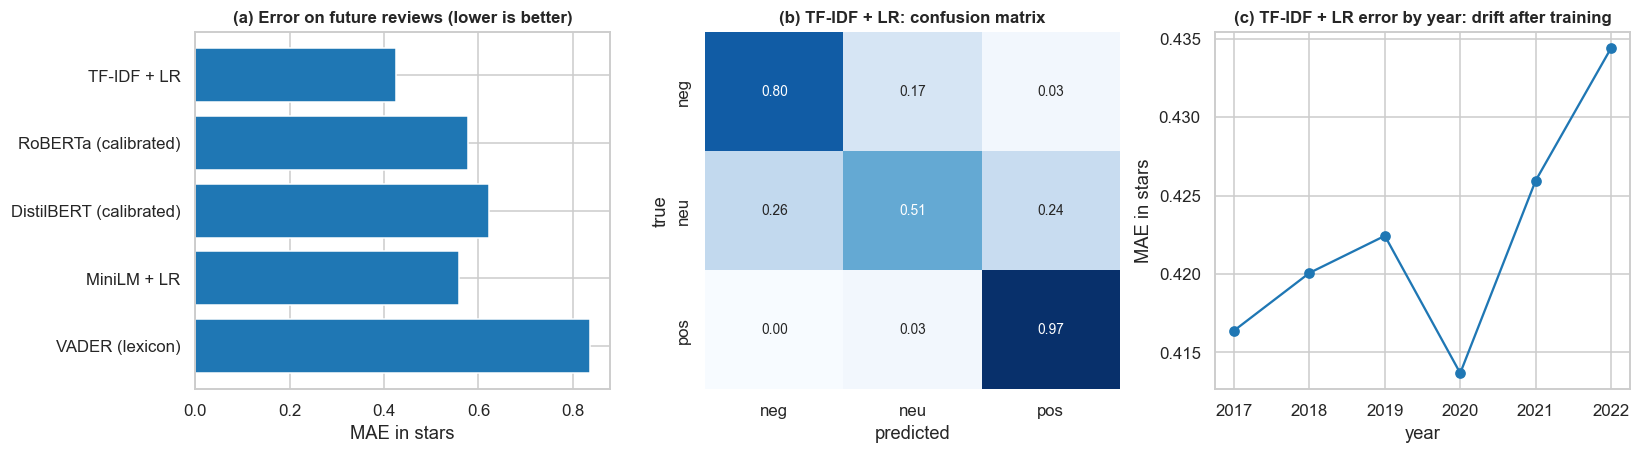

Largest errors of the best model. Some are real contradictions between the text and the stars:


,stars,pred,text
5855,1,4.7,Update: SB Locksmiths got the last laugh on t...
5087,1,4.7,"On the alley is, and was before a Favorite eat..."
679,5,1.3,I ordered take-out here on Cinco De Mayo. They...
2035,1,4.4,I always love coming here. The beauty and cam...
1959,1,4.4,Broke my favorite watch and just sent me away ...
4856,1,4.3,The beer and food are phenomenal. The service ...


In [9]:
def calibrated_stars(Xcal, ycal, Xtest):
    """Logistic regression from a model's raw output to the 5 star classes -> expected stars."""
    clf = LogisticRegression(max_iter=2000, C=10).fit(Xcal, ycal)
    return clf.predict_proba(Xtest) @ clf.classes_


y_true = R["stars"].values[TEST_IDS]
y_cal = R["stars"].values[CAL_IDS]
lg = lambda d, i: np.log(d.loc[i].values + 1e-4)
vad = R["vader"].values
PRED = {
    "VADER (lexicon)": calibrated_stars(np.c_[vad[CAL_IDS], vad[CAL_IDS] ** 3], y_cal, np.c_[vad[TEST_IDS], vad[TEST_IDS] ** 3]),
    "TF-IDF + LR": R["sent_lr"].values[TEST_IDS],
    "MiniLM + LR": LogisticRegression(max_iter=3000, C=3).fit(emb.loc[EMB_TRAIN_IDS].values, R["stars"].values[EMB_TRAIN_IDS]).predict_proba(emb.loc[TEST_IDS].values) @ STAR_CLASSES,
    "DistilBERT (calibrated)": calibrated_stars(lg(distil, CAL_IDS), y_cal, lg(distil, TEST_IDS)),
    "RoBERTa (calibrated)": calibrated_stars(lg(roberta, CAL_IDS), y_cal, lg(roberta, TEST_IDS)),
}
train_size = {"VADER (lexicon)": "2,000 (calibration)", "TF-IDF + LR": f"{int(((R['date'] < TEXT_TRAIN_END) & R['is_en']).sum()):,}", "MiniLM + LR": "15,000",
              "DistilBERT (calibrated)": "2,000 (calibration)", "RoBERTa (calibrated)": "2,000 (calibration)"}
speed = {"VADER (lexicon)": "~10,000", "TF-IDF + LR": "~10,000", "MiniLM + LR": "~70", "DistilBERT (calibrated)": "~20", "RoBERTa (calibrated)": "~10"}
rows = []
for name, p in PRED.items():
    boot = [f1_score(three_class(y_true[i]), three_class(p[i]), average="macro")
            for i in (np.random.default_rng(k).integers(0, len(p), len(p)) for k in range(200))]
    rows.append({"model": name, **text_metrics(y_true, p), "F1_low": np.percentile(boot, 2.5), "F1_high": np.percentile(boot, 97.5),
                 "training_reviews": train_size[name], "reviews_per_s": speed[name]})
RESULTS["sentiment_benchmark"] = pd.DataFrame(rows).set_index("model").sort_values("macro_F1_3class", ascending=False)
display(RESULTS["sentiment_benchmark"].round(3))

fig, ax = plt.subplots(1, 3, figsize=(15, 4.2))
names = RESULTS["sentiment_benchmark"].index
ax[0].barh(names[::-1], RESULTS["sentiment_benchmark"]["MAE_stars"][::-1], color="tab:blue")
ax[0].set(title="(a) Error on future reviews (lower is better)", xlabel="MAE in stars")
best = names[0]
cm = confusion_matrix(three_class(y_true), three_class(PRED[best]), normalize="true")
sns.heatmap(cm, annot=True, fmt=".2f", cmap="Blues", ax=ax[1], xticklabels=["neg", "neu", "pos"], yticklabels=["neg", "neu", "pos"], cbar=False)
ax[1].set(title=f"(b) {best}: confusion matrix", xlabel="predicted", ylabel="true")
d = R[R["is_en"] & (R["date"] >= TEXT_TRAIN_END)].groupby("year").apply(lambda g: mean_absolute_error(g["stars"], g["sent_lr"]))
ax[2].plot(d.index, d.values, "-o", color="tab:blue")
ax[2].set(title="(c) TF-IDF + LR error by year: drift after training", xlabel="year", ylabel="MAE in stars")
savefig("sentiment_benchmark")

errors = pd.DataFrame({"stars": y_true, "pred": PRED[best], "text": [TXT.iloc[i][:170].replace("\n", " ") for i in TEST_IDS]})
errors["err"] = errors["pred"] - errors["stars"]
print("Largest errors of the best model. Some are real contradictions between the text and the stars:")
display(errors.reindex(errors["err"].abs().sort_values(ascending=False).index).head(6)[["stars", "pred", "text"]].round(1))

**Reading the benchmark.** TF-IDF + LR wins clearly (macro-F1 about 0.75; MAE 0.42 stars), ahead of RoBERTa, DistilBERT and MiniLM (0.65-0.67), with VADER last (0.59). **This comparison is not fully even:** TF-IDF + LR learned from about 171,000 Yelp reviews, MiniLM's classifier from 15,000, and the pretrained transformers were not fine-tuned on Yelp at all (fine-tuning needs a GPU). The fair conclusion is that a simple model trained on the domain beats models trained elsewhere, not that TF-IDF is better than transformers in general. All methods find the neutral 3-star class hardest (the best model recalls about half), since 3 stars mix praise and complaints. Error on later years rises only slightly, so the model ages well. The largest errors include real contradictions between text and rating, which motivates the sentiment-star gap (4.6).

### 4.2 Aspect-based sentiment: *what* are people happy or unhappy about?

Overall sentiment says that a review is negative. Aspect-based sentiment says **why**, such as "food fine, service terrible". The steps are:

1. **Discover topics** with NMF on lemmatised text, to see what reviewers talk about, without assuming it (4.3).
2. **Define six aspects** from those topics: food, service, price, ambience, wait, cleanliness.
3. **Score each sentence** that mentions an aspect with VADER, and average per review. VADER is used here because it needs no training on stars, so these features cannot leak ratings into later models.
4. **Check against a transformer**: compare the scores with a dedicated aspect-based model (DeBERTa ABSA) on a sample.

The result is, for each review, a sentiment per aspect that it mentions (missing when it does not mention the aspect).

In [10]:
ASPECT_WORDS = {
    "food": r"food|dish(es)?|menu|meals?|taste[sd]?|tasty|delicious|flavou?rs?|flavou?rful|bland|fresh|pizza|burgers?|sandwich(es)?|tacos?|sushi|breakfast|brunch|lunch|dinner|dessert|appetizers?|salads?|burrito|coffee|wine|beer|cocktails?|drinks?",
    "service": r"service|staff|servers?|waiter|waitress|bartender|hosts?|hostess|manager|owner|employees?|customer service|rude|friendly|helpful|attentive|professional|receptionist",
    "price": r"prices?|pricey|priced|expensive|cheap|overpriced|affordable|worth|value|cost|costs|charged?|fees?|bill|pay|paid|deals?|money",
    "ambience": r"atmosphere|ambian?ce|decor|vibe|music|noisy|loud|patio|cozy|seating|views?|romantic|crowded|outdoor|setting",
    "wait": r"wait|waited|waiting|line|queue|slow|quick|quickly|fast|minutes|mins|hours?|reservations?|on time|late",
    "clean": r"clean|cleaned|cleanliness|dirty|filthy|bathrooms?|restrooms?|smell[sy]?|stinks?|sanitary|tidy|hygiene|gross",
}
ASP_RE = {a: re.compile(rf"\b(?:{p})\b") for a, p in ASPECT_WORDS.items()}
SENT_SPLIT = re.compile(r"(?<=[.!?])\s+|\n+")
COVID_RE = re.compile(r"\b(covid|covid-19|coronavirus|pandemic|quarantine|lockdown|masks?|social distanc\w+)\b")


def _aspect_chunk(texts):
    from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer
    sia = SentimentIntensityAnalyzer()
    out = np.full((len(texts), len(ASPECTS) + 1), np.nan, dtype=np.float32)
    for i, t in enumerate(texts):
        low = t.lower()
        sums = {a: [] for a in ASPECTS}
        for s in SENT_SPLIT.split(low):
            hit = [a for a in ASPECTS if ASP_RE[a].search(s)]
            if hit:
                c = sia.polarity_scores(s)["compound"]
                for a in hit:
                    sums[a].append(c)
        for k, a in enumerate(ASPECTS):
            if sums[a]:
                out[i, k] = np.mean(sums[a])
        out[i, -1] = float(COVID_RE.search(low) is not None)
    return out


def compute_aspects():
    chunks = np.array_split(TXT.values, N_JOBS * 8)
    res = Parallel(n_jobs=N_JOBS)(delayed(_aspect_chunk)(list(c)) for c in chunks)
    return pd.DataFrame(np.vstack(res), index=TXT.index, columns=ASP_COLS + ["covid_mention"])


asp = cached("aspects", compute_aspects)
for c_ in asp.columns:
    R[c_] = asp[c_].values
del asp; gc.collect()
display(pd.DataFrame({"mentioned in % of reviews": R[ASP_COLS].notna().mean() * 100,
                      "mean sentiment": R[ASP_COLS].mean(),
                      "sentiment at 1 star": R.loc[R["stars"] == 1, ASP_COLS].mean(),
                      "sentiment at 5 stars": R.loc[R["stars"] == 5, ASP_COLS].mean()}).round(2))

,mentioned in % of reviews,mean sentiment,sentiment at 1 star,sentiment at 5 stars
asp_food,64.85,0.38,-0.01,0.50
asp_service,53.87,0.42,-0.15,0.60
asp_price,30.25,0.26,-0.03,0.42
asp_ambience,22.34,0.45,0.06,0.55
asp_wait,30.23,0.23,-0.02,0.33
asp_clean,9.59,0.33,-0.15,0.56


### 4.3 Topic check: do the aspects match what reviewers talk about?

NMF is run on the lemmatised sample with stop words removed. If the discovered topics line up with the aspects, then the dictionary reflects real content and not just our assumptions. The table shows the top words of each topic and the aspect dictionary with the largest overlap.

In [11]:
from sklearn.decomposition import NMF

extra_stop = list(ENGLISH_STOP_WORDS | {"just", "get", "go", "got", "good", "great", "like", "place", "really", "come", "time", "would", "say", "try", "know", "make", "take", "come", "want", "look", "'s", "n't", "'m", "'ve", "'re", "'ll"})
tv = TfidfVectorizer(stop_words=extra_stop, min_df=20, max_df=.35, max_features=8000, token_pattern=r"[a-z]{3,}", sublinear_tf=True)
Xl = tv.fit_transform(lem.values)
nmf = NMF(n_components=14, init="nndsvd", random_state=SEED, max_iter=200).fit(Xl)
voc = np.array(tv.get_feature_names_out())
rows = []
for k, comp in enumerate(nmf.components_):
    top = voc[np.argsort(comp)[::-1][:9]]
    hits = {a: sum(bool(ASP_RE[a].fullmatch(w)) for w in top) for a in ASPECTS}
    a_best = max(hits, key=hits.get)
    rows.append({"topic": k, "top words": ", ".join(top), "closest aspect": a_best if hits[a_best] >= 2 else "(business type)", "matching words": hits[a_best]})
RESULTS["nmf_topics"] = pd.DataFrame(rows).set_index("topic")
with pd.option_context("display.max_colwidth", 95):
    display(RESULTS["nmf_topics"])

,top words,closest aspect,matching words
topic,,,
0,"order, chicken, salad, sandwich, eat, burger, fry, fresh, sauce",food,4
1,"work, tell, need, ask, customer, day, car, experience, bad",(business type),0
2,"love, amazing, favorite, absolutely, atmosphere, year, awesome, kid, super",(business type),1
3,"food, service, excellent, restaurant, delicious, atmosphere, customer, mexican, amazing",food,2
4,"room, stay, hotel, clean, beach, nice, location, bed, night",(business type),1
5,"santa, barbara, visit, favorite, stop, restaurant, area, trip, live",(business type),0
6,"wine, tasting, taste, tour, winery, glass, bottle, fun, enjoy",food,2
7,"recommend, highly, amazing, definitely, wedding, professional, work, job, experience",(business type),1
8,"taco, salsa, mexican, fish, chip, burrito, tortilla, asada, bean",food,2


### 4.4 Check against a dedicated aspect model

No hand-labelled aspect data exist here, so there is no gold standard. Two indirect checks are used on a sample of sentence-aspect pairs: agreement between the VADER scores and the DeBERTa ABSA model, and how well each predicts the stars of the review. A model that reads the aspect in context should do better, and the size of the difference shows what using the fast method costs.

In [12]:
def compute_absa(n_per_aspect=500):
    rng_ = np.random.default_rng(SEED)
    rows = []
    for a in ASPECTS:
        cand = rng_.permutation(np.flatnonzero(R[f"asp_{a}"].notna().values & R["is_en"].values))[:n_per_aspect * 4]
        got = 0
        for i in cand:
            sents = [s for s in SENT_SPLIT.split(TXT.iloc[i]) if ASP_RE[a].search(s.lower()) and 3 <= len(s.split()) <= 60]
            if sents:
                rows.append((int(i), a, sents[0]))
                got += 1
            if got >= n_per_aspect:
                break
    d = pd.DataFrame(rows, columns=["rid", "aspect", "sentence"])
    p = transformer_scores("yangheng/deberta-v3-base-absa-v1.1", d.index.values, pairs=d["aspect"].tolist(),
                           max_len=96, texts=d["sentence"].tolist())
    return pd.concat([d, p], axis=1)


absa = cached("absa_sample", compute_absa)
absa["absa_score"] = absa["p2"] - absa["p0"]             # positive minus negative
absa["absa_class"] = absa[["p0", "p1", "p2"]].values.argmax(1)
vs = pd.Series(np.concatenate(Parallel(n_jobs=N_JOBS)(delayed(_vader_chunk)(list(c)) for c in np.array_split(absa["sentence"].values, N_JOBS))), index=absa.index)
absa["vader_s"] = vs
absa["vader_class"] = np.where(vs <= -.05, 0, np.where(vs >= .05, 2, 1))
absa["stars"] = R["stars"].values[absa["rid"]]
rows = []
for a, g in list(absa.groupby("aspect")) + [("ALL", absa)]:
    rows.append({"aspect": a, "pairs": len(g), "agreement": (g["vader_class"] == g["absa_class"]).mean(), "Cohen kappa": cohen_kappa_score(g["vader_class"], g["absa_class"]),
                 "Spearman(scores)": stats.spearmanr(g["vader_s"], g["absa_score"])[0], "Spearman(VADER, stars)": stats.spearmanr(g["vader_s"], g["stars"])[0],
                 "Spearman(ABSA, stars)": stats.spearmanr(g["absa_score"], g["stars"])[0]})
RESULTS["absa_check"] = pd.DataFrame(rows).set_index("aspect")
display(RESULTS["absa_check"].round(3))

,pairs,agreement,Cohen kappa,Spearman(scores),"Spearman(VADER, stars)","Spearman(ABSA, stars)"
aspect,,,,,,
ambience,500,0.648,0.232,0.503,0.251,0.238
clean,500,0.712,0.411,0.653,0.529,0.546
food,500,0.496,0.205,0.429,0.330,0.282
price,500,0.498,0.219,0.439,0.385,0.525
service,500,0.670,0.326,0.493,0.557,0.514
wait,500,0.308,0.005,0.368,0.290,0.445
ALL,3000,0.555,0.250,0.527,0.414,0.451


**Reading the check.** VADER and the aspect model agree on 56 % of the pairs (kappa 0.25), which is modest. For predicting stars the aspect model is a little better overall (Spearman 0.45 against 0.41). The difference is large for **wait** (kappa near 0, and 0.45 against 0.29) and **price** (0.53 against 0.39): "we waited 40 minutes" contains no emotional words for a lexicon. So the wait and price scores are the weakest parts of this method and should be read with care. The aspect model handled about 26 pairs per second here, so with at least 700,000 review-aspect pairs a full run would take many hours on this CPU, which is why it serves as a check.

### 4.5 What drives the stars, by category?

A regression of a review's stars on its aspect sentiments shows which aspects weigh most in each type of business. Sentiment is standardised, and an unmentioned aspect is set to neutral (0), with an extra indicator for whether it was mentioned. A review's stars and text are written together, so these results describe **what explains a rating** rather than what causes it, and these same-review scores are not used as forecast inputs.

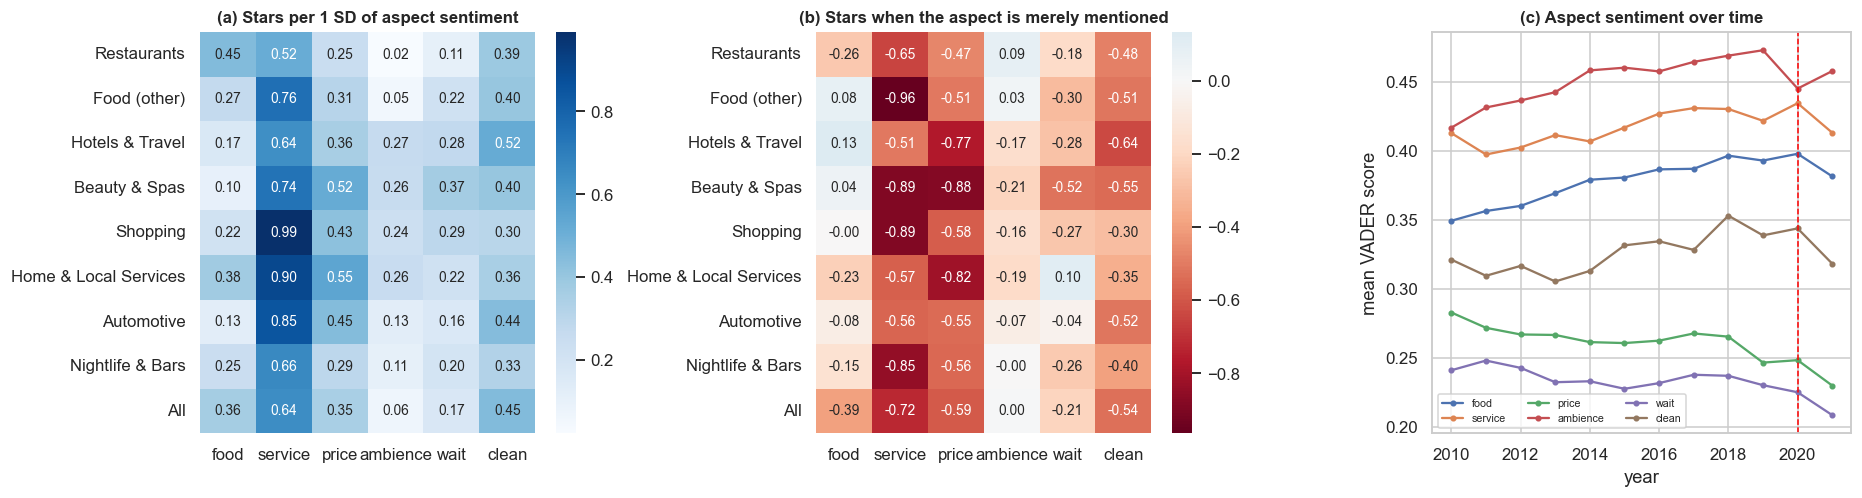

In [13]:
import statsmodels.api as sm


def aspect_drivers(d):
    X = pd.DataFrame(index=d.index)
    for a in ASP_COLS:
        X[a] = (d[a].fillna(0) - d[a].mean()) / d[a].std()
        X["m_" + a] = d[a].notna().astype(float)
    return sm.OLS(d["stars"].values, sm.add_constant(X)).fit(cov_type="HC1")


cats = R["macro_cat"].value_counts().head(8).index.tolist()
rows, mention = {}, {}
for cat in cats + ["All"]:
    d = R[R["is_en"]] if cat == "All" else R[(R["macro_cat"] == cat) & R["is_en"]]
    res = aspect_drivers(d)
    rows[cat] = res.params[ASP_COLS]
    mention[cat] = res.params[["m_" + a for a in ASP_COLS]]
drv = pd.DataFrame(rows).T; drv.columns = ASPECTS
men = pd.DataFrame(mention).T; men.columns = ASPECTS
RESULTS["aspect_drivers"] = drv

fig, ax = plt.subplots(1, 3, figsize=(17, 4.6))
sns.heatmap(drv, annot=True, fmt=".2f", cmap="Blues", ax=ax[0]); ax[0].set_title("(a) Stars per 1 SD of aspect sentiment")
sns.heatmap(men, annot=True, fmt=".2f", cmap="RdBu", center=0, ax=ax[1]); ax[1].set_title("(b) Stars when the aspect is merely mentioned")
ys = R[R["is_en"] & (R["year"] >= 2010) & (R["date"] <= LAST_FULL_MONTH)].groupby("year")[ASP_COLS].mean()
for a, col in zip(ASPECTS, ASP_COLS):
    ax[2].plot(ys.index, ys[col], "-o", ms=3, label=a)
ax[2].axvline(2020, color="red", ls="--", lw=1); ax[2].legend(ncol=3, fontsize=7)
ax[2].set(title="(c) Aspect sentiment over time", ylabel="mean VADER score", xlabel="year")
savefig("aspect_drivers")

**Reading the figure.** Service is the strongest driver of the rating in every category, even in restaurants (0.52 against 0.45 for food). In panel (b), merely *mentioning* service, price or cleanliness goes with fewer stars: people bring these topics up mostly when something went wrong. Mentioning ambience is neutral. Sentiment drifted slowly upwards for food, service, ambience and cleanliness until about 2019, price and wait did not, and most aspects were lower by 2021.

### 4.6 The sentiment-star gap

`gap = expected stars from the text - actual stars`. A negative gap means that the text is **more negative than the rating**: a polite 4 stars with an unhappy text. If people soften their ratings but not their words, the gap could be an early warning that a business's ratings will fall. This hypothesis is tested with real forecasts in Section 8.3. Here we only look at how the gap behaves.

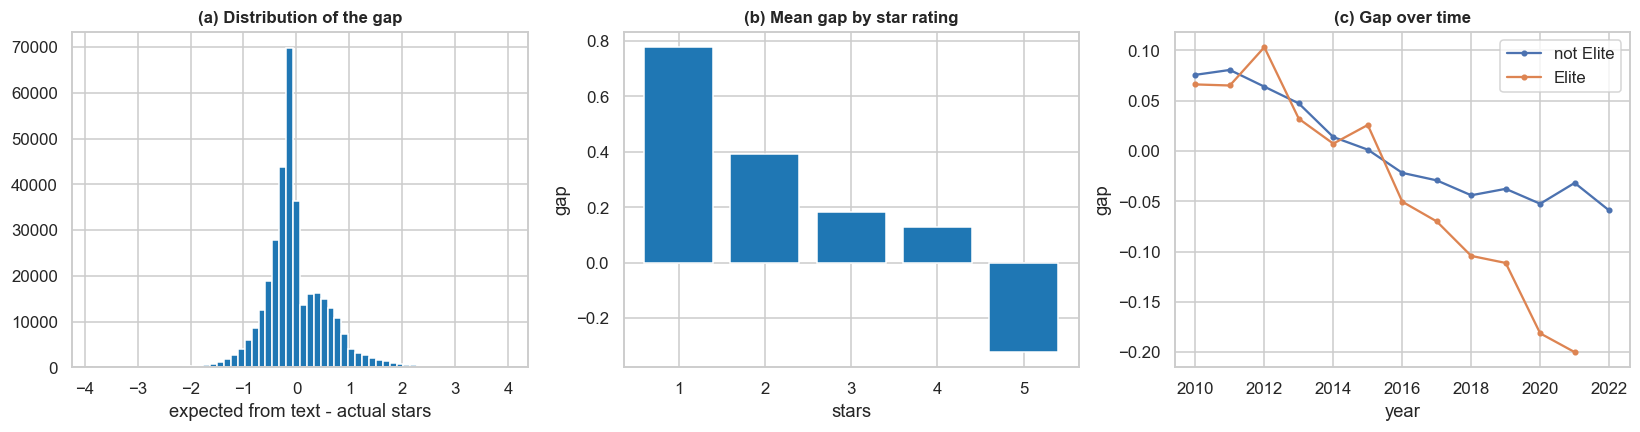

The gap by construction tends to be positive at low stars and negative at high stars, because predictions regress towards the middle. Later analyses therefore compare the gap within a business over time, and control for the stars.


In [14]:
gp = R[R["is_en"]]
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
ax[0].hist(gp["gap"].clip(-4, 4), bins=60, color="tab:blue"); ax[0].set(title="(a) Distribution of the gap", xlabel="expected from text - actual stars")
g = gp.groupby("stars")["gap"].mean(); ax[1].bar(g.index, g.values, color="tab:blue")
ax[1].set(title="(b) Mean gap by star rating", xlabel="stars", ylabel="gap")
g = gp.assign(e=gp["elite_now"]).groupby("e")["gap"].mean()
ybar = gp[gp["year"] >= 2010].groupby(["year", "elite_now"])["gap"].mean().unstack()
ax[2].plot(ybar.index, ybar[False], "-o", ms=3, label="not Elite"); ax[2].plot(ybar.index, ybar[True], "-o", ms=3, label="Elite")
ax[2].legend(); ax[2].set(title="(c) Gap over time", xlabel="year", ylabel="gap")
savefig("sentiment_gap")
print(f"The gap by construction tends to be positive at low stars and negative at high stars, because predictions regress towards the middle. "
      f"Later analyses therefore compare the gap within a business over time, and control for the stars.")

## 5. Social network analysis

### 5.1 The friendship network

Users are nodes and friendships are undirected edges, kept only between users in the subset. **Limitations:** this is a single snapshot taken at the end of the data, with no dates, and friends outside the area are missing. Section 5.5 builds a dated network to partly offset this.

Slow metrics (Louvain communities, approximate betweenness from 100 sampled sources) are stored in the cache.

In [15]:
import networkx as nx
from networkx.algorithms.community import louvain_communities, modularity as nx_modularity
from scipy.sparse.csgraph import connected_components
from sklearn.metrics import adjusted_rand_score


def compute_node_metrics():
    G = nx.from_pandas_edgelist(EDGES, "a", "b")
    d = pd.DataFrame(index=pd.Index(sorted(G.nodes), name="u"))
    pr = nx.pagerank(G, alpha=.85, tol=1e-7)
    d["pagerank"] = pd.Series(pr)
    d["core"] = pd.Series(nx.core_number(G))
    comps = max(nx.connected_components(G), key=len)
    H = G.subgraph(comps)
    d["betweenness"] = pd.Series(nx.betweenness_centrality(H, k=100, seed=SEED, normalized=True))
    d["clustering"] = pd.Series(nx.clustering(G, nodes=np.random.default_rng(SEED).choice(list(G.nodes), 20_000, replace=False).tolist()))
    c1 = sorted(louvain_communities(G, seed=SEED), key=len, reverse=True)
    c2 = louvain_communities(G, seed=SEED + 1)
    d["community"] = pd.Series({u: i for i, c in enumerate(c1) for u in c})
    d2 = pd.Series({u: i for i, c in enumerate(c2) for u in c}).reindex(d.index)
    q1, q2 = nx_modularity(G, c1), nx_modularity(G, c2)
    # sampled average shortest path in the largest component
    src = np.random.default_rng(SEED).choice(list(H.nodes), 40, replace=False)
    lens = [np.mean(list(nx.single_source_shortest_path_length(H, int(s)).values())) for s in src]
    # configuration model with the same degrees, for clustering and path length
    deg_seq = [x for _, x in G.degree()]
    C = nx.Graph(nx.configuration_model(deg_seq, seed=SEED)); C.remove_edges_from(nx.selfloop_edges(C))
    nodes_c = np.random.default_rng(SEED).choice(list(C.nodes), 20_000, replace=False).tolist()
    clust_null = nx.average_clustering(C, nodes=nodes_c)
    Hc = C.subgraph(max(nx.connected_components(C), key=len))
    src2 = np.random.default_rng(SEED).choice(list(Hc.nodes), 40, replace=False)
    lens_null = [np.mean(list(nx.single_source_shortest_path_length(Hc, int(s)).values())) for s in src2]
    d.attrs = {}
    meta = pd.DataFrame([{"nodes": G.number_of_nodes(), "edges": G.number_of_edges(), "lcc": len(comps), "components": nx.number_connected_components(G),
                          "n_comm": len(c1), "Q": q1, "Q_seed2": q2, "ARI_seeds": adjusted_rand_score(d["community"], d2),
                          "path": float(np.mean(lens)), "path_null": float(np.mean(lens_null)), "clust_null": clust_null}])
    meta.to_parquet(CACHE / "net_meta.parquet")
    del G, H, C, Hc; gc.collect()
    return d.reset_index()


NODES = cached("node_metrics", compute_node_metrics).set_index("u")
meta = pd.read_parquet(CACHE / "net_meta.parquet").iloc[0]
NODES["degree"] = deg[NODES.index]
netdeg = NODES["degree"]
display(pd.Series({"Nodes (users with a friend in the subset)": f"{int(meta['nodes']):,} of {n_users:,}", "Edges": f"{int(meta['edges']):,}",
                   "Density": f"{2 * meta['edges'] / (meta['nodes'] * (meta['nodes'] - 1)):.6f}",
                   "Mean / median / max degree": f"{netdeg.mean():.1f} / {netdeg.median():.0f} / {netdeg.max():,}",
                   "Components; largest": f"{int(meta['components']):,}; {meta['lcc'] / meta['nodes']:.1%} of the nodes",
                   "Average clustering (observed vs same degrees, random)": f"{NODES['clustering'].mean():.3f} vs {meta['clust_null']:.3f}",
                   "Mean path length (observed vs same degrees, random)": f"{meta['path']:.2f} vs {meta['path_null']:.2f}",
                   "Louvain communities; modularity Q": f"{int(meta['n_comm']):,}; {meta['Q']:.3f}",
                   "Stability: Q with another seed; adjusted Rand index": f"{meta['Q_seed2']:.3f}; {meta['ARI_seeds']:.2f}"}, name="value").to_frame())

,value
Nodes (users with a friend in the subset),"64,154 of 155,252"
Edges,"471,089"
Density,0.000229
Mean / median / max degree,"14.7 / 4 / 2,007"
Components; largest,"1,093; 96.3% of the nodes"
"Average clustering (observed vs same degrees, random)",0.098 vs 0.020
"Mean path length (observed vs same degrees, random)",4.26 vs 3.72
Louvain communities; modularity Q,"1,676; 0.526"
Stability: Q with another seed; adjusted Rand index,0.518; 0.57


### 5.2 Who befriends whom? Homophily and the opinion network

If friends rate alike, it matters for all that follows. The **assortativity** of an attribute is its correlation across the two ends of a friendship. To tell whether a value is large, it is compared with a null model in which the attribute is shuffled among the nodes. These user attributes describe all of a user's reviews, so this analysis describes the network and is not used for forecasting.

In [16]:
ua = R.groupby("u").agg(n=("stars", "size"), stars=("stars", "mean"), sent=("sent_lr", "mean"), vader=("vader", "mean"), gap=("gap", "mean"),
                        elite=("elite_now", "max"), first_year=("year", "min"), text_len=("text_len", "mean"))
ua = ua.reindex(np.arange(n_users))
ua["join_year"] = USERS.set_index("u")["join_year"].reindex(np.arange(n_users)).values
ua["log_reviews"] = np.log1p(ua["n"])
ua["log_degree"] = np.log1p(deg)
for a in ASP_COLS:
    ua[a] = R.groupby("u")[a].mean().reindex(np.arange(n_users)).values


def assortativity(x, mask=None, n_perm=100):
    a, b = EDGES["a"].values, EDGES["b"].values
    x = np.asarray(x, float)
    keep = np.isfinite(x)
    if mask is not None:
        keep &= mask
    ok = keep[a] & keep[b]
    a, b = a[ok], b[ok]
    corr = lambda v: np.corrcoef(np.r_[v[a], v[b]], np.r_[v[b], v[a]])[0, 1]
    obs = corr(x)
    ids = np.unique(np.r_[a, b])
    rng_ = np.random.default_rng(SEED)
    null = []
    for _ in range(n_perm):
        y = x.copy(); y[ids] = rng_.permutation(x[ids])
        null.append(corr(y))
    return obs, np.mean(null), np.std(null), len(a)


multi = (ua["n"] >= 3).values                            # opinions of users with very few reviews are too noisy
rows = []
for name, col, mask in (("log degree", "log_degree", None), ("log number of reviews", "log_reviews", None), ("join year", "join_year", None), ("Elite ever", "elite", None),
                        ("mean stars given (3+ reviews)", "stars", multi), ("mean text sentiment (3+ reviews)", "sent", multi),
                        ("service sentiment (3+ reviews)", "asp_service", multi), ("food sentiment (3+ reviews)", "asp_food", multi)):
    o, m_, s_, n_ = assortativity(ua[col].astype(float), mask)
    rows.append({"attribute": name, "assortativity": o, "null mean": m_, "z vs null": (o - m_) / s_, "edges": n_})
RESULTS["assortativity"] = pd.DataFrame(rows).set_index("attribute")
display(RESULTS["assortativity"].round(3))

,assortativity,null mean,z vs null,edges
attribute,,,,
log degree,0.298,-0.000,195.645,471089
log number of reviews,0.166,-0.000,127.131,471089
join year,0.495,0.000,350.998,471089
Elite ever,0.452,-0.000,295.430,471089
mean stars given (3+ reviews),0.053,-0.001,17.737,100164
mean text sentiment (3+ reviews),0.055,-0.001,19.170,100164
service sentiment (3+ reviews),0.008,-0.001,2.340,88173
food sentiment (3+ reviews),0.045,-0.001,13.722,94828


**Reading the table.** Friendship is sorted mainly by **activity**: when users joined (0.50) and being Elite (0.45). Opinions are much less sorted: mean stars 0.05 and mean sentiment 0.06, far above the null but small in size. Friends resemble each other much more in how they use Yelp than in how they rate. This early hint matters for what follows: a friendship tie carries little general information about opinions.

### 5.3 Communities and central users: what knowledge does the network give?

The top communities are described by size, activity and opinions. For categories, **lift** shows what a community reviews more than average: 1.5 means 50 % more than expected. A separate table shows that the various centrality measures partly capture the same thing, and how they relate to activity.

Communities with at least 5,000 reviews: 6; they hold 52% of all reviews


,users,reviews,median degree,mean join year,reviews by Elite %,share in Santa Barbara %,reviews per user,mean stars,mean sentiment,top category (lift)
community,,,,,,,,,,
0,17263,59445,6,2013.1,4.56,77.25,3.44,4.04,4.02,Health & Medical (1.64)
4,7119,41500,3,2012.5,32.22,73.82,5.83,4.04,4.00,Food (other) (1.22)
1,10771,27294,6,2010.9,45.29,82.70,2.53,4.01,3.98,Arts & Entertainment (1.74)
2,9188,24402,3,2010.4,40.30,82.74,2.66,4.00,3.98,Hotels & Travel (1.40)
5,5962,15358,6,2014.3,17.86,58.21,2.58,3.94,3.90,Nightlife & Bars (1.25)
3,7822,13160,3,2011.8,5.30,81.21,1.68,4.07,4.04,Hotels & Travel (1.60)


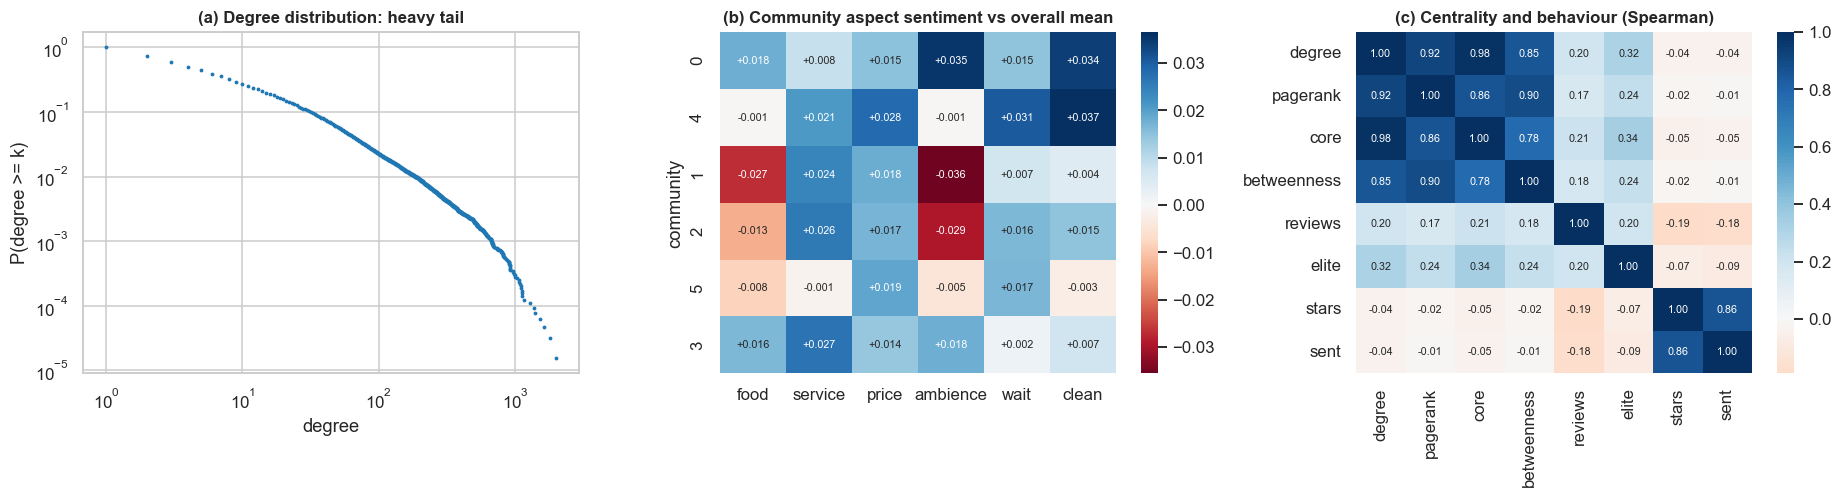

In [17]:
R["community"] = R["u"].map(NODES["community"])
vc_comm = R["community"].value_counts()
top_comm = vc_comm[vc_comm >= 5000].index.astype(int).tolist()   # only communities large enough to give a usable time series
print(f"Communities with at least 5,000 reviews: {len(top_comm)}; they hold {vc_comm[vc_comm >= 5000].sum() / len(R):.0%} of all reviews")
overall_cat = R["macro_cat"].value_counts(normalize=True)
overall_city = (R["city"] == "Santa Barbara").mean()
rows = []
for c in top_comm:
    g = R[R["community"] == c]
    members = NODES.index[NODES["community"] == c]
    lift = (g["macro_cat"].value_counts(normalize=True) / overall_cat).dropna()
    shares = g["macro_cat"].value_counts(normalize=True)
    lift = lift[shares.reindex(lift.index) >= .02].sort_values(ascending=False)
    rows.append({"community": c, "users": len(members), "reviews": len(g), "median degree": int(NODES.loc[members, "degree"].median()),
                 "mean join year": round(USERS.set_index("u").loc[members, "join_year"].mean(), 1), "reviews by Elite %": 100 * g["elite_now"].mean(),
                 "share in Santa Barbara %": 100 * (g["city"] == "Santa Barbara").mean(), "reviews per user": len(g) / len(members),
                 "mean stars": g["stars"].mean(), "mean sentiment": g["sent_lr"].mean(), "top category (lift)": f"{lift.index[0]} ({lift.iloc[0]:.2f})"})
RESULTS["community_profile"] = pd.DataFrame(rows).set_index("community")
display(RESULTS["community_profile"].round(2))

fig, ax = plt.subplots(1, 3, figsize=(17, 4.6))
vals, cnt = np.unique(netdeg, return_counts=True)
ccdf = 1 - np.cumsum(cnt) / cnt.sum() + cnt / cnt.sum()
ax[0].loglog(vals, ccdf, ".", ms=3, color="tab:blue"); ax[0].set(title="(a) Degree distribution: heavy tail", xlabel="degree", ylabel="P(degree >= k)")
asp_dev = pd.DataFrame({c: R.loc[R["community"] == c, ASP_COLS].mean() - R[ASP_COLS].mean() for c in top_comm}).T
asp_dev.columns = ASPECTS
sns.heatmap(asp_dev, annot=True, fmt="+.3f", cmap="RdBu", center=0, ax=ax[1], annot_kws={"size": 7}); ax[1].set_title("(b) Community aspect sentiment vs overall mean")
ax[1].set_ylabel("community")
centr = NODES[["degree", "pagerank", "core", "betweenness"]].join(ua[["n", "elite", "stars", "sent"]]).rename(columns={"n": "reviews"}).dropna(subset=["betweenness"]).astype(float)
sp_corr = centr.corr(method="spearman")
sns.heatmap(sp_corr, annot=True, fmt=".2f", cmap="RdBu", center=0, ax=ax[2], annot_kws={"size": 7}); ax[2].set_title("(c) Centrality and behaviour (Spearman)")
savefig("network_structure")
RESULTS["centrality_spearman"] = sp_corr

**What the network tells us.** It is a small world: clustering is about 5 times that of a random network with the same degrees (0.098 against 0.020), with a similar path length (4.3 against 3.7). Louvain finds clear structure (Q = 0.53), but the exact boundaries depend on the seed (adjusted Rand index 0.57), so communities are useful groupings, not exact facts.

Six communities hold about half of all reviews, and they differ in character, for example: C1 and C2 are older, Elite-heavy groups (40-45 % of their reviews are by Elite users), C0 is the largest and contains few Elite reviews (5 %), C3 has few reviews per user and leans to hotels and travel, which suggests visitors. Differences in aspect sentiment between communities are small. Centrality measures largely overlap, and PageRank and betweenness are only weakly related to how much a person reviews in this subset.

### 5.4 Influence: do friends affect ratings and visits?

Yelp has no record of who read what, so influence has to be inferred. The main threats are **homophily** (friends have similar tastes) and **joint visits** (friends go together). Three tests are designed around these threats.

**Test A. Rating conformity, friend against matched stranger.** Take a review by user *v* at business *b*, preceded by a review from a friend of *v*. Pair it with an earlier review of *b* by a **non-friend written as close as possible in time to the friend's**, which holds the business and period nearly fixed. Then regress *v*'s rating deviation on both reviewers' deviations, controlling for how generous each person usually is (their earlier deviations elsewhere), with business and quarter fixed effects. The clues are:

* friend > non-friend: rating is more similar among friends;
* a *friend of a friend* (no direct tie) against a stranger: a large effect here would suggest shared tastes more than direct influence;
* decay with the time since the friend's review: influence should fade, while stable shared tastes should not.

Same-day reviews are reported separately because they likely reflect joint visits.

In [18]:
R = R.sort_values(["date"], kind="stable")
R["prior_mean"] = R.groupby("b")["stars"].transform(lambda s: s.shift().expanding().mean())
R["prior_n"] = R.groupby("b").cumcount()
R["dev"] = R["stars"] - R["prior_mean"]
R["lenient"] = R.groupby("u")["dev"].transform(lambda s: s.shift().expanding().mean()).fillna(0)
R["rid"] = R.index
ptr, ind = A.indptr, A.indices


def compute_pairs():
    """For every review with an earlier friend review of the same business: most recent friend + matched non-friend."""
    D = R[["b", "u", "stars", "day", "prior_mean", "prior_n", "lenient", "q", "rid"]].sort_values(["b", "day"], kind="stable")
    bb, uu, ss, dd, pm, pn, ln, ridd = [D[c].values for c in ("b", "u", "stars", "day", "prior_mean", "prior_n", "lenient", "rid")]
    cut = np.r_[0, np.flatnonzero(np.diff(bb)) + 1, len(bb)]
    rows = []
    for s, e in zip(cut[:-1], cut[1:]):
        if e - s < 6:
            continue
        pos = {}                                         # user -> last position in this business
        for i in range(s, e):
            v = uu[i]
            nb = ind[ptr[v]:ptr[v + 1]]
            if len(nb) and pos and pn[i] >= 5:
                fset = set(nb.tolist())
                friends = [pos[f] for f in fset if f in pos] if len(fset) <= len(pos) else [p for w, p in pos.items() if w in fset]
                if friends:
                    f = max(friends)
                    # nearest earlier non-friend reviewer, searching outwards from the friend's position
                    n_ = -1
                    for off in range(1, e - s):
                        for j in (f - off, f + off):
                            if s <= j < i and uu[j] != v and uu[j] not in fset:
                                n_ = j
                                break
                        if n_ >= 0:
                            break
                    if n_ >= 0:
                        common = np.intersect1d(nb, ind[ptr[uu[n_]]:ptr[uu[n_] + 1]], assume_unique=True).size
                        rows.append((ridd[i], bb[i], v, ss[i], pm[i], ln[i], ss[f], ln[f], dd[i] - dd[f], ss[n_], ln[n_], abs(dd[f] - dd[n_]), common, len(friends)))
            pos[v] = i
    return pd.DataFrame(rows, columns=["rid", "b", "u", "y", "pm", "len_v", "s_f", "len_f", "lag", "s_n", "len_n", "match_days", "n_common", "n_friends"])


P = cached("influence_pairs", compute_pairs)
P["y_dev"] = P["y"] - P["pm"]; P["x_f"] = P["s_f"] - P["pm"]; P["x_n"] = P["s_n"] - P["pm"]
P["q"] = R.loc[P["rid"].values, "q"].astype(str).values
P["fof"] = (P["n_common"] > 0).astype(float)


def conformity(d, extra=()):
    cols = ["y_dev", "x_f", "x_n", "len_v", "len_f", "len_n", *extra]
    W = within(d, cols, ["b", "q"])
    return ols_cluster(W["y_dev"], W[cols[1:]], d["u"].values)


rows = []
for label, mask in (("all lags (1+ days)", P["lag"] >= 1), ("same day (joint visits?)", P["lag"] == 0), ("1-30 days", P["lag"].between(1, 30)),
                    ("31-180 days", P["lag"].between(31, 180)), ("181-730 days", P["lag"].between(181, 730)), ("over 2 years", P["lag"] > 730)):
    d = P[mask]
    m = conformity(d)
    t = m.t_test("x_f - x_n = 0")
    rows.append({"time since friend's review": label, "pairs": len(d), "friend": m.params["x_f"], "friend_se": m.bse["x_f"], "non-friend": m.params["x_n"], "non-friend_se": m.bse["x_n"],
                 "difference": float(t.effect[0]), "diff_se": float(t.sd[0][0]), "p": float(t.pvalue)})
RESULTS["conformity_by_lag"] = pd.DataFrame(rows).set_index("time since friend's review")
display(RESULTS["conformity_by_lag"].round(4))

# friend of a friend vs total stranger: is the non-friend socially close?
d = P[P["lag"] >= 1].copy()
d["x_n_fof"] = d["x_n"] * d["fof"]
m = conformity(d, extra=("x_n_fof", "fof"))
print(f"Non-friend reviewer who IS a friend of a friend: extra effect {m.params['x_n_fof']:+.4f} (SE {m.bse['x_n_fof']:.4f}, p = {m.pvalues['x_n_fof']:.3f}); "
      f"share of pairs {d['fof'].mean():.1%}; stranger effect {m.params['x_n']:+.4f} (SE {m.bse['x_n']:.4f})")
RESULTS["conformity_fof"] = pd.DataFrame({"coef": m.params, "se": m.bse, "p": m.pvalues}).loc[["x_f", "x_n", "x_n_fof"]]

,pairs,friend,friend_se,non-friend,non-friend_se,difference,diff_se,p
time since friend's review,,,,,,,,
all lags (1+ days),30937,0.1270,0.0084,0.0098,0.0056,0.1172,0.0098,0.0000
same day (joint visits?),933,0.9042,0.0229,0.0019,0.0204,0.9024,0.0293,0.0000
1-30 days,4187,0.3737,0.0231,0.0440,0.0133,0.3297,0.0268,0.0000
31-180 days,7726,0.1089,0.0155,0.0048,0.0109,0.1040,0.0191,0.0000
181-730 days,11257,0.0544,0.0121,0.0108,0.0092,0.0436,0.0151,0.0039
over 2 years,7767,0.0810,0.0153,0.0017,0.0124,0.0793,0.0202,0.0001


Non-friend reviewer who IS a friend of a friend: extra effect +0.0105 (SE 0.0154, p = 0.496); share of pairs 19.6%; stranger effect +0.0087 (SE 0.0060)


**Test B. Visits: are people more likely to review a place their friend reviewed?** This is a matched case-control test. Each *case* (user *v* reviews *b*) is paired with a *control*: another user with a similar number of friends, active in the same city and month, who has not yet reviewed *b*. The odds ratio comes from discordant pairs (one exposed, the other not). It is split by how recently the friend reviewed.

**Test C. Mood contagion: lead placebo.** Is a user's rating at any business related to how favourably their friends rated businesses in the **previous** month? Controls are the user's usual generosity and month fixed effects. The placebo is the same variable for the friends' **next** month: it cannot have an influence on an earlier rating, so a similar size would point to shared shocks and tastes and not to contagion.

In [19]:
def compute_case_control(n_cases=60_000):
    rng_ = np.random.default_rng(SEED)
    D = R[(R["deg"] > 0) & (R["prior_n"] >= 1)][["u", "b", "day", "month", "city", "deg"]].copy()
    D["bucket"] = pd.cut(D["deg"], [0, 1, 2, 5, 10, 20, 50, 100, 1e6], labels=False)
    first = {}                                           # (b) -> {user: first day}
    for b_, u_, d_ in zip(R["b"].values, R["u"].values, R["day"].values):
        m_ = first.setdefault(int(b_), {})
        m_.setdefault(int(u_), int(d_))
    pools = {k: v["u"].unique() for k, v in D.groupby(["city", "month", "bucket"], observed=True)}
    idx = rng_.choice(len(D), min(n_cases, len(D)), replace=False)

    def exposure(user, b_, day):
        m_ = first[b_]
        nb = ind[ptr[user]:ptr[user + 1]]
        best = None
        nbs = set(nb.tolist())
        for f in (nbs if len(nbs) <= len(m_) else [w for w in m_ if w in nbs]):
            t = m_.get(f)
            if t is not None and t < day:
                gap_ = day - t
                best = gap_ if best is None or gap_ < best else best
        return -1 if best is None else best

    rows = []
    cols = D[["u", "b", "day", "city", "month", "bucket"]].values
    for i in idx:
        v, b_, day, city, month, bk = cols[i]
        pool = pools.get((city, month, bk))
        if pool is None or len(pool) < 2:
            continue
        m_ = first[int(b_)]
        w = None
        for _ in range(10):
            c_ = int(pool[rng_.integers(len(pool))])
            if c_ != v and not (c_ in m_ and m_[c_] <= day):
                w = c_
                break
        if w is None:
            continue
        rows.append((exposure(int(v), int(b_), int(day)), exposure(w, int(b_), int(day))))
    return pd.DataFrame(rows, columns=["case", "control"])


CC = cached("case_control", compute_case_control)
rows = []
for label, lo, hi in (("1-30 days", 1, 30), ("31-180 days", 31, 180), ("over 180 days", 181, 10 ** 6), ("any earlier friend", 1, 10 ** 6)):
    e_case = CC["case"].between(lo, hi); e_ctrl = CC["control"].between(lo, hi)
    un_case, un_ctrl = CC["case"] == -1, CC["control"] == -1
    b_ = (e_case & un_ctrl).sum(); c_ = (e_ctrl & un_case).sum()
    or_ = b_ / c_; se = np.sqrt(1 / b_ + 1 / c_)
    rows.append({"friend reviewed": label, "% cases exposed": 100 * e_case.mean(), "% controls exposed": 100 * e_ctrl.mean(), "discordant pairs": int(b_ + c_), "odds ratio": or_,
                 "CI low": np.exp(np.log(or_) - 1.96 * se), "CI high": np.exp(np.log(or_) + 1.96 * se)})
RESULTS["case_control_visits"] = pd.DataFrame(rows).set_index("friend reviewed")
print(f"Matched pairs: {len(CC):,}")
display(RESULTS["case_control_visits"].round(3))

Matched pairs: 59,369


,% cases exposed,% controls exposed,discordant pairs,odds ratio,CI low,CI high
friend reviewed,,,,,,
1-30 days,2.308,0.898,1120,4.490,3.858,5.226
31-180 days,4.090,2.481,2056,2.398,2.181,2.637
over 180 days,10.334,8.061,6421,1.654,1.573,1.740
any earlier friend,16.731,11.440,9597,1.973,1.891,2.058


Reviews with active friends in both neighbouring months: 58,139


,coef,se,p
friend_prev,0.0286,0.0087,0.0010
friend_next,0.0159,0.0086,0.0644
lenient,0.3940,0.0148,0.0000


previous month - next month = +0.0128 (p = 0.328)


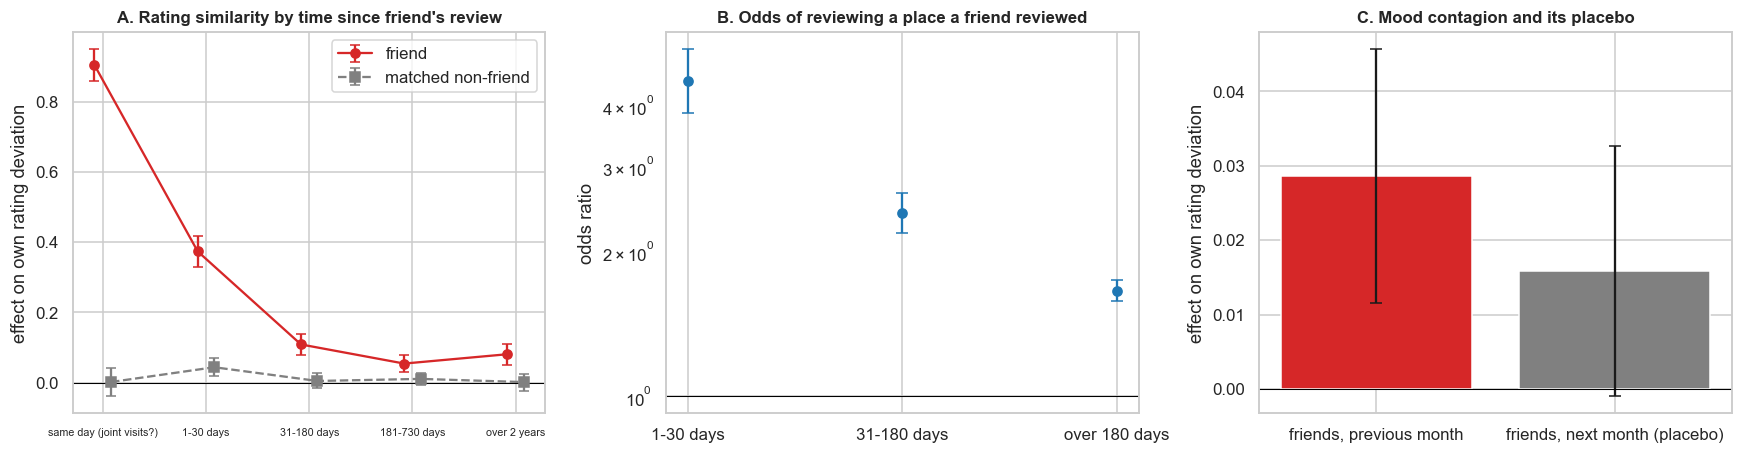

In [20]:
# ---- Test C: monthly friend mood (previous and next month) -----------------------------------------------------------
months = sorted(R["month"].unique())
mi = {m_: i for i, m_ in enumerate(months)}
RR = R[R["dev"].notna()].copy()
RR["mi"] = RR["month"].map(mi).astype(int)
fm = np.full((len(RR),), np.nan); fl = fm.copy()
sums = [None] * len(months); cnts = [None] * len(months)
for m_, g in RR.groupby("mi"):
    s_ = np.zeros(n_users); c_ = np.zeros(n_users)
    np.add.at(s_, g["u"].values, g["dev"].values); np.add.at(c_, g["u"].values, 1.0)
    sums[m_] = A @ s_; cnts[m_] = A @ c_
uu_, mm_ = RR["u"].values, RR["mi"].values
for shift, arr in ((-1, fm), (1, fl)):
    for m_ in np.unique(mm_):
        k = m_ + shift
        if 0 <= k < len(months) and sums[k] is not None:
            sel = np.flatnonzero(mm_ == m_)
            arr[sel] = sums[k][uu_[sel]] / np.where(cnts[k][uu_[sel]] > 0, cnts[k][uu_[sel]], np.nan)
RR["friend_prev"], RR["friend_next"] = fm, fl
d = RR.dropna(subset=["friend_prev", "friend_next"])
d = d[d["prior_n"] >= 5]
W = within(d, ["dev", "friend_prev", "friend_next", "lenient"], ["mi"])
mC = ols_cluster(W["dev"], W[["friend_prev", "friend_next", "lenient"]], d["u"].values)
tC = mC.t_test("friend_prev - friend_next = 0")
RESULTS["mood_contagion"] = pd.DataFrame({"coef": mC.params, "se": mC.bse, "p": mC.pvalues}).drop("const")
print(f"Reviews with active friends in both neighbouring months: {len(d):,}")
display(RESULTS["mood_contagion"].round(4))
print(f"previous month - next month = {float(tC.effect[0]):+.4f} (p = {float(tC.pvalue):.3f})")
del RR, sums, cnts, fm, fl, W; gc.collect()

fig, ax = plt.subplots(1, 3, figsize=(16, 4.2))
t = RESULTS["conformity_by_lag"].iloc[1:]
x = np.arange(len(t))
ax[0].errorbar(x - .08, t["friend"], 1.96 * t["friend_se"], fmt="o-", color="tab:red", capsize=3, label="friend")
ax[0].errorbar(x + .08, t["non-friend"], 1.96 * t["non-friend_se"], fmt="s--", color="grey", capsize=3, label="matched non-friend")
ax[0].set_xticks(x); ax[0].set_xticklabels(t.index, fontsize=7); ax[0].legend(); ax[0].axhline(0, color="black", lw=.7)
ax[0].set(title="A. Rating similarity by time since friend's review", ylabel="effect on own rating deviation")
t = RESULTS["case_control_visits"].iloc[:3]
ax[1].errorbar(np.arange(len(t)), t["odds ratio"], [t["odds ratio"] - t["CI low"], t["CI high"] - t["odds ratio"]], fmt="o", color="tab:blue", capsize=4)
ax[1].axhline(1, color="black", lw=.7); ax[1].set_xticks(np.arange(len(t))); ax[1].set_xticklabels(t.index)
ax[1].set(title="B. Odds of reviewing a place a friend reviewed", ylabel="odds ratio", yscale="log")
t = RESULTS["mood_contagion"].loc[["friend_prev", "friend_next"]]
ax[2].bar(["friends, previous month", "friends, next month (placebo)"], t["coef"], yerr=1.96 * t["se"], color=["tab:red", "grey"], capsize=4)
ax[2].axhline(0, color="black", lw=.7); ax[2].set(title="C. Mood contagion and its placebo", ylabel="effect on own rating deviation")
savefig("influence_tests")

**Reading the three tests.**

* **A. Ratings.** A friend's earlier rating is far more informative than a matched stranger's (0.127 against 0.010, for all lags of 1+ days). The effect is 0.37 within 30 days and fades to about 0.05-0.08 after 6 months. Same-day reviews reach 0.90, which most likely reflects joint visits. A friend of a friend is not more similar than a complete stranger (p = 0.50), so the similarity seems tied to direct contact and not to a broad social neighbourhood.
* **B. Visits.** Compared with matched users, those who reviewed a place are much more likely to have a friend who reviewed it recently: odds ratio 4.5 within 30 days, 2.4 for 31-180 days, 1.7 after that.
* **C. Mood.** Friends' previous-month ratings go with the user's own (0.029), but the placebo with next month's ratings is not significantly smaller (0.016; difference p = 0.33). So there is **no clear evidence of general mood contagion**: this looks more like shared taste and common shocks.

**What can be claimed.** The decay and the failed friend-of-friend link favour something specific to friends over general homophily. But reviews within 30 days can still be joint visits written up on different days, and we cannot observe this. The evidence is compatible with influence and does not prove it.

### 5.5 Yearly co-review networks: a network that changes over time

The friendship graph has no dates, but co-reviewing does. For each year Y, two active users (2+ reviews in Y) are linked when they reviewed **at least 2 of the same businesses in Y**. One shared business says little, because popular places link almost everyone. Requiring two reduces that noise.

Growth in the number of reviews can change a network's structure by itself. So each year is compared with a **null network**: the businesses of that year's reviews are randomly reassigned, keeping each user's activity and each business's popularity. Only differences from the null count as real structure.

This also gives dated network inputs for the forecasts: for each year, a business-to-business network whose links are shared reviewers (with less weight for very active users). Section 8 uses it because it does not depend on the undated friendship list.

,active_users,edges,null_edges,mean_degree,modularity,null_modularity,clustering,null_clustering,largest_comp_%,top1%_retained_%,top1%_elite_%,coreview_ties_friends_%,null_coreview_ties_friends_%
year,,,,,,,,,,,,,
2009,911,1010,958,2.217,0.536,0.422,0.307,0.338,45.115,NaN,22.222,2.574,1.044
2010,1443,2314,1812,3.207,0.515,0.418,0.381,0.335,47.748,0.000,42.857,2.593,1.876
2011,2205,4746,4042,4.305,0.467,0.376,0.399,0.377,54.376,4.545,27.273,2.065,1.534
2012,2601,4849,3780,3.729,0.438,0.371,0.422,0.432,49.673,30.769,42.308,2.454,2.487
2013,3300,6026,4773,3.652,0.458,0.389,0.390,0.369,47.424,12.121,33.333,2.257,1.928
2014,4454,8399,6618,3.771,0.451,0.392,0.394,0.334,45.510,11.364,20.455,1.750,2.191
2015,5372,12891,9300,4.799,0.420,0.371,0.438,0.389,46.835,9.434,35.849,2.063,2.215
2016,5682,13248,8402,4.663,0.461,0.420,0.428,0.354,44.650,14.286,41.071,2.053,2.261
2017,5894,12365,8070,4.196,0.456,0.407,0.431,0.338,44.181,15.517,60.345,2.887,3.643


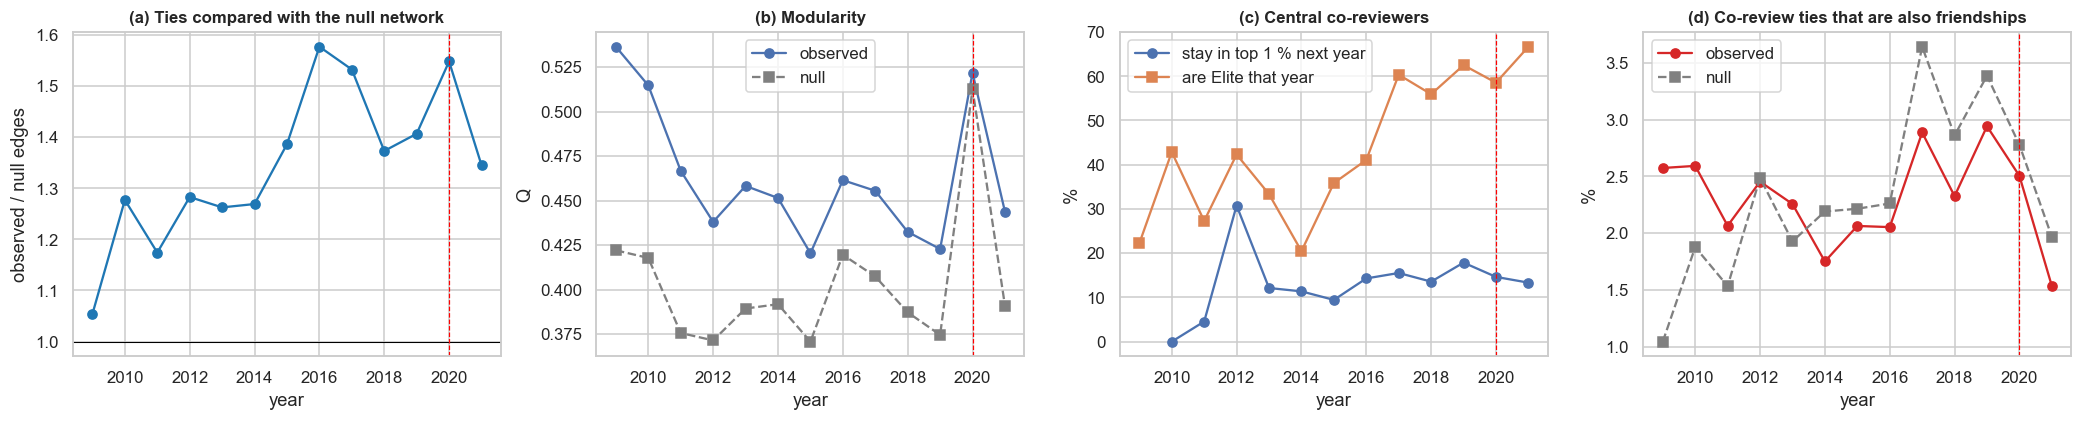

In [21]:
def _yearly_user_net(d, min_shared=2):
    u_, b_ = pd.factorize(d["u"].values)[0], pd.factorize(d["b"].values)[0]
    B = sp.csr_matrix((np.ones(len(d)), (u_, b_)))
    B.data[:] = 1
    B.sum_duplicates(); B.data[:] = 1
    M = (B @ B.T).tocsr()
    M.setdiag(0); M.eliminate_zeros()
    M.data = (M.data >= min_shared).astype(np.int8); M.eliminate_zeros()
    return M, pd.unique(d["u"].values)


def _net_stats(M, ids=None, do_mod=True):
    n = M.shape[0]
    edges = M.nnz // 2
    ncomp, lab = connected_components(M, directed=False)
    sizes = np.bincount(lab)
    res = {"active_users": n, "edges": edges, "density": 2 * edges / max(1, n * (n - 1)), "mean_degree": 2 * edges / max(1, n), "isolated_%": 100 * (np.asarray(M.sum(1)).ravel() == 0).mean(),
           "largest_comp_%": 100 * sizes.max() / n}
    if do_mod and edges:
        keep = np.flatnonzero(np.asarray(M.sum(1)).ravel() > 0)
        G = nx.from_scipy_sparse_array(M[keep][:, keep])
        comm = louvain_communities(G, seed=SEED)
        res["modularity"] = nx_modularity(G, comm); res["communities"] = len(comm)
        res["clustering"] = nx.average_clustering(G, nodes=np.random.default_rng(SEED).choice(G.number_of_nodes(), min(2000, G.number_of_nodes()), replace=False).tolist())
    return res


def compute_yearly_networks():
    rows = []
    prev_top = None
    rng_ = np.random.default_rng(SEED)
    Rn = R[(R["year"] >= 2009) & (R["year"] <= 2021)]
    for y, d in Rn.groupby("year"):
        d = d.drop_duplicates(["u", "b"])
        d = d[d.groupby("u")["b"].transform("size") >= 2]
        M, ids = _yearly_user_net(d)
        st = _net_stats(M)
        # central users: top 1 % by degree in this year's network
        dg = np.asarray(M.sum(1)).ravel()
        top = set(ids[np.argsort(dg)[::-1][:max(1, len(ids) // 100)]])
        st["top1%_retained_%"] = np.nan if prev_top is None else 100 * len(top & prev_top) / len(top)
        prev_top = top
        st["top1%_elite_%"] = 100 * np.mean([(u_, y) in ELITE_SET for u_ in top])
        # how many co-review ties are also friendships?
        Mu = sp.triu(M, k=1).tocoo()
        st["coreview_ties_friends_%"] = 100 * np.asarray(A[ids[Mu.row], ids[Mu.col]]).mean() if Mu.nnz else np.nan
        # null: businesses reassigned at random
        dn = d.copy(); dn["b"] = rng_.permutation(dn["b"].values)
        dn = dn.drop_duplicates(["u", "b"])
        Mn, idsn = _yearly_user_net(dn)
        sn = _net_stats(Mn)
        Mun = sp.triu(Mn, k=1).tocoo()
        st["null_edges"] = sn["edges"]; st["null_modularity"] = sn.get("modularity", np.nan); st["null_clustering"] = sn.get("clustering", np.nan)
        st["null_coreview_ties_friends_%"] = 100 * np.asarray(A[idsn[Mun.row], idsn[Mun.col]]).mean() if Mun.nnz else np.nan
        rows.append({"year": y, **st})
        print(f"  {y}: users {st['active_users']:,}, edges {st['edges']:,}, null edges {st['null_edges']:,}", flush=True)
    return pd.DataFrame(rows).set_index("year")


ELITE_SET = set(zip(ELITE["u"].values, ELITE["year"].values))
YN = cached("yearly_networks", compute_yearly_networks)
RESULTS["yearly_coreview_network"] = YN
display(YN[["active_users", "edges", "null_edges", "mean_degree", "modularity", "null_modularity", "clustering", "null_clustering", "largest_comp_%", "top1%_retained_%", "top1%_elite_%", "coreview_ties_friends_%", "null_coreview_ties_friends_%"]].round(3))

fig, ax = plt.subplots(1, 4, figsize=(19, 3.9))
ax[0].plot(YN.index, YN["edges"] / YN["null_edges"], "-o", color="tab:blue"); ax[0].axhline(1, color="black", lw=.7)
ax[0].set(title="(a) Ties compared with the null network", ylabel="observed / null edges")
ax[1].plot(YN.index, YN["modularity"], "-o", label="observed"); ax[1].plot(YN.index, YN["null_modularity"], "--s", color="grey", label="null")
ax[1].legend(); ax[1].set(title="(b) Modularity", ylabel="Q")
ax[2].plot(YN.index, YN["top1%_retained_%"], "-o", label="stay in top 1 % next year"); ax[2].plot(YN.index, YN["top1%_elite_%"], "-s", label="are Elite that year")
ax[2].legend(); ax[2].set(title="(c) Central co-reviewers", ylabel="%")
ax[3].plot(YN.index, YN["coreview_ties_friends_%"], "-o", color="tab:red", label="observed"); ax[3].plot(YN.index, YN["null_coreview_ties_friends_%"], "--s", color="grey", label="null")
ax[3].legend(); ax[3].set(title="(d) Co-review ties that are also friendships", ylabel="%")
for a in ax:
    a.axvline(2020, color="red", ls="--", lw=.8); a.set_xlabel("year")
savefig("yearly_networks")

**Reading the yearly networks.** The comparison with the null prevents false conclusions.

* Observed ties exceed the null, by about 1.2-1.6 times since 2010, so co-reviewing is more than chance given activity and popularity. The excess grew up to 2016.
* Modularity looks high every year, but much of that is present in the null as well. The jump in 2020 occurs **in both**: fewer reviews make a sparser network, and that alone raises modularity. It would be wrong to read this as communities closing up during COVID.
* Co-review ties are *not* more often friendships than in the null (about 1.5-3.5 % in both, and in most recent years lower than the null). Sharing a place and being friends are largely separate things on Yelp.
* Central co-reviewers change quickly (mostly about 10-20 % stay in the top 1 % the next year), and they are increasingly Elite (about 20-40 % before 2016, 55-67 % from 2017 on).

In [22]:
def business_graphs():
    """Per year: business-business graph, links = shared reviewers, each reviewer weighted 1/(businesses reviewed - 1)."""
    out = {}
    n_b = len(biz)
    for y, d in R[(R["year"] >= 2006) & (R["year"] <= 2021)].groupby("year"):
        d = d.drop_duplicates(["u", "b"])
        d = d[d.groupby("u")["b"].transform("size") >= 2]
        k = d.groupby("u")["b"].transform("size").values
        uids, u_ = np.unique(d["u"].values, return_inverse=True)
        B = sp.csr_matrix((1 / np.sqrt(k - 1), (u_, d["b"].values)), shape=(len(uids), n_b))
        G_ = (B.T @ B).tolil()
        G_.setdiag(0)
        out[y] = G_.tocsr()
    return out


def weighted_pagerank(W, alpha=.85, iters=40):
    n = W.shape[0]
    s = np.asarray(W.sum(1)).ravel()
    D = sp.diags(np.where(s > 0, 1 / np.where(s > 0, s, 1), 0))
    T = (D @ W).T.tocsr()
    x = np.full(n, 1 / n)
    for _ in range(iters):
        x = alpha * (T @ x) + (alpha * x[s == 0].sum() + 1 - alpha) / n
    return x


BIZ_G = business_graphs()
BIZ_PR = {y: weighted_pagerank(g) for y, g in BIZ_G.items()}
print(f"Business co-review graphs ready for {min(BIZ_G)}-{max(BIZ_G)}; links in 2019: {BIZ_G[2019].nnz // 2:,}")

Business co-review graphs ready for 2006-2021; links in 2019: 72,483


## 6. Recommender system

**Task.** Recommend businesses that a user has not yet reviewed, and predict the rating they would give.

**Evaluation design.** A random split would let a model learn from the future, so the split is by time:

| Set | Period | Use |
|---|---|---|
| Train | before 2018 | fit the models |
| Test | 2018-2019 | final evaluation (before COVID) |
| Validation | train on reviews before 2017, evaluate on 2017 | choose hyperparameters and hybrid weights |

Users and businesses are restricted to those with **at least 5 training reviews** (using only pre-split data). Separately, Section 6.4 looks at **cold-start** users with few or no training reviews.

**Metrics.** RMSE and MAE for rating prediction. Ranking counts a test review of 4+ stars as relevant, and all candidate businesses are ranked, not a small sample, since sampled metrics can mislead. Reported: NDCG@10, Recall@10, HitRate@10. Beyond accuracy: **catalogue coverage** (share of businesses ever recommended) and **novelty** (how unpopular the recommended places are).

| Model | Idea | Source of information |
|---|---|---|
| Popularity | the same most-reviewed places for everyone | baseline |
| Bias model | global mean + user bias + business bias | ratings |
| Biased MF | user and business factors, ALS on ratings | ratings |
| Implicit ALS | "who visited what", no matter the rating | visits |
| Item kNN | similar to places the user liked | ratings |
| Content | TF-IDF text of a business's reviews against the user's liked text | text |
| Aspect | what the user cares about × how the business scores on it | sentiment |
| Social | places that friends reviewed and liked | network |
| Hybrid | a weighted mix, with weights selected on validation | all |

In [23]:
for name_ in ("distil", "roberta", "emb", "PRED", "errors", "absa", "Xl", "nmf", "tv", "voc", "lem", "gp", "ys", "drv", "men", "ua", "centr", "CC"):
    globals().pop(name_, None)
gc.collect()


def k_core_filter(d, k=5):
    pairs = d[["u", "b"]].drop_duplicates()
    while True:
        keep = (pairs.groupby("u")["b"].transform("size") >= k) & (pairs.groupby("b")["u"].transform("size") >= k)
        if keep.all():
            return set(pairs["u"]), set(pairs["b"])
        pairs = pairs[keep]


class RecData:
    """Index maps, sparse matrices and test sets for one time split."""

    def __init__(self, train_end, test_end, k=5):
        hist = R[R["date"] < train_end]
        users, items = k_core_filter(hist, k)
        self.users, self.items = np.array(sorted(users)), np.array(sorted(items))
        self.ui = pd.Series(np.arange(len(self.users)), index=self.users)
        self.ii = pd.Series(np.arange(len(self.items)), index=self.items)
        tr = hist[hist["u"].isin(users) & hist["b"].isin(items)].sort_values("date").drop_duplicates(["u", "b"], keep="last")
        self.tr = tr.assign(ux=tr["u"].map(self.ui).values, ix=tr["b"].map(self.ii).values)
        te = R[(R["date"] >= train_end) & (R["date"] < test_end) & R["u"].isin(users) & R["b"].isin(items)]
        te = te.sort_values("date").drop_duplicates(["u", "b"], keep="first")
        te = te.assign(ux=te["u"].map(self.ui).values, ix=te["b"].map(self.ii).values)
        seen = set(zip(self.tr["ux"], self.tr["ix"]))
        self.te = te[[pair not in seen for pair in zip(te["ux"], te["ix"])]]        # only new user-business pairs
        self.n_u, self.n_i = len(self.users), len(self.items)
        self.Rm = sp.csr_matrix((self.tr["stars"].astype(float), (self.tr["ux"], self.tr["ix"])), shape=(self.n_u, self.n_i))
        self.Bin = (self.Rm > 0).astype(float).tocsr()


class BiasModel:
    def fit(self, D, reg=5, iters=15):
        self.mu = D.tr["stars"].mean()
        bu, bi = np.zeros(D.n_u), np.zeros(D.n_i)
        ux, ix, s = D.tr["ux"].values, D.tr["ix"].values, D.tr["stars"].values
        for _ in range(iters):
            bi = np.bincount(ix, s - self.mu - bu[ux], D.n_i) / (np.bincount(ix, minlength=D.n_i) + reg)
            bu = np.bincount(ux, s - self.mu - bi[ix], D.n_u) / (np.bincount(ux, minlength=D.n_u) + reg)
        self.bu, self.bi = bu, bi
        return self

    def predict(self, ux, ix):
        return self.mu + self.bu[ux] + self.bi[ix]


class BiasedMF:
    """Biased matrix factorisation with alternating least squares on the residuals of the bias model."""

    def __init__(self, k=20, reg=10, iters=12, bias_reg=5):
        self.k, self.reg, self.iters, self.bias_reg = k, reg, iters, bias_reg

    def fit(self, D):
        self.base = BiasModel().fit(D, reg=self.bias_reg)
        ux, ix = D.tr["ux"].values, D.tr["ix"].values
        res = D.tr["stars"].values - self.base.predict(ux, ix)
        M = sp.csr_matrix((res, (ux, ix)), shape=(D.n_u, D.n_i))
        Mt = M.T.tocsr()
        rng_ = np.random.default_rng(SEED)
        P, Q = rng_.normal(0, .1, (D.n_u, self.k)), rng_.normal(0, .1, (D.n_i, self.k))
        I = self.reg * np.eye(self.k)
        for _ in range(self.iters):
            for u_ in range(D.n_u):
                idx, val = M.indices[M.indptr[u_]:M.indptr[u_ + 1]], M.data[M.indptr[u_]:M.indptr[u_ + 1]]
                if len(idx):
                    Qi = Q[idx]; P[u_] = np.linalg.solve(Qi.T @ Qi + I, Qi.T @ val)
            for i_ in range(D.n_i):
                idx, val = Mt.indices[Mt.indptr[i_]:Mt.indptr[i_ + 1]], Mt.data[Mt.indptr[i_]:Mt.indptr[i_ + 1]]
                if len(idx):
                    Pu = P[idx]; Q[i_] = np.linalg.solve(Pu.T @ Pu + I, Pu.T @ val)
        self.P, self.Q = P, Q
        return self

    def predict(self, ux, ix):
        return self.base.predict(ux, ix) + (self.P[ux] * self.Q[ix]).sum(1)

    def score_user(self, u_):
        return self.base.mu + self.base.bu[u_] + self.base.bi + self.Q @ self.P[u_]


class ImplicitALS:
    """Weighted matrix factorisation for implicit feedback (Hu, Koren and Volinsky 2008)."""

    def __init__(self, k=40, reg=5, alpha=20, iters=10):
        self.k, self.reg, self.alpha, self.iters = k, reg, alpha, iters

    def fit(self, D):
        B = D.Bin; Bt = B.T.tocsr()
        rng_ = np.random.default_rng(SEED)
        P, Q = rng_.normal(0, .05, (D.n_u, self.k)), rng_.normal(0, .05, (D.n_i, self.k))
        I = self.reg * np.eye(self.k)
        a = self.alpha

        def step(X, Y, Mx):
            YtY = Y.T @ Y
            for r in range(X.shape[0]):
                idx = Mx.indices[Mx.indptr[r]:Mx.indptr[r + 1]]
                if len(idx):
                    Yi = Y[idx]
                    X[r] = np.linalg.solve(YtY + a * Yi.T @ Yi + I, (1 + a) * Yi.sum(0))
                else:
                    X[r] = 0
        for _ in range(self.iters):
            step(P, Q, B); step(Q, P, Bt)
        self.P, self.Q = P, Q
        return self

    def score_user(self, u_):
        return self.Q @ self.P[u_]


class ItemKNN:
    """Item-based collaborative filtering on mean-centred ratings, top-k cosine neighbours."""

    def __init__(self, k=50, shrink=10):
        self.k, self.shrink = k, shrink

    def fit(self, D):
        self.D = D
        self.base = BiasModel().fit(D)
        res = D.tr["stars"].values - self.base.predict(D.tr["ux"].values, D.tr["ix"].values)
        M = sp.csr_matrix((res, (D.tr["ux"], D.tr["ix"])), shape=(D.n_u, D.n_i))
        self.M = M
        Mc = M.T.tocsr()
        nrm = np.sqrt(np.asarray(Mc.multiply(Mc).sum(1)).ravel())
        S = (Mc @ Mc.T).tocsr()
        S.setdiag(0); S.eliminate_zeros()
        coo = S.tocoo()
        cnt = (D.Bin.T @ D.Bin).tocsr()
        support = np.asarray(cnt[coo.row, coo.col]).ravel()
        coo.data = coo.data / (nrm[coo.row] * nrm[coo.col] + 1e-9) * support / (support + self.shrink)
        S = sp.csr_matrix((coo.data, (coo.row, coo.col)), shape=S.shape)
        rows, cols, vals = [], [], []
        for i_ in range(D.n_i):
            idx, v = S.indices[S.indptr[i_]:S.indptr[i_ + 1]], S.data[S.indptr[i_]:S.indptr[i_ + 1]]
            if len(idx) > self.k:
                top = np.argpartition(np.abs(v), -self.k)[-self.k:]
                idx, v = idx[top], v[top]
            rows.append(np.full(len(idx), i_)); cols.append(idx); vals.append(v)
        self.S = sp.csr_matrix((np.concatenate(vals), (np.concatenate(rows), np.concatenate(cols))), shape=S.shape)
        return self

    def score_user(self, u_):
        r = self.M[u_]
        num = np.asarray(self.S @ r.T.toarray()).ravel()
        mask = (r != 0).astype(float).T.toarray()
        den = np.asarray(np.abs(self.S) @ mask).ravel()
        return self.base.mu + self.base.bu[u_] + self.base.bi + num / (den + 1)

    def predict(self, ux, ix):
        out = np.zeros(len(ux))
        for u_ in np.unique(ux):
            sel = ux == u_
            out[sel] = self.score_user(u_)[ix[sel]]
        return out

In [24]:
class ContentModel:
    """A business profile = TF-IDF of the text of its training reviews; a user profile = weighted mean of liked businesses."""

    def fit(self, D, max_reviews=60):
        rids = D.tr.sort_values("date").groupby("ix").tail(max_reviews)
        docs = pd.Series(TXT.iloc[rids["rid"].values].values, index=rids["ix"].values).groupby(level=0).agg(" ".join)
        tfidf = TfidfVectorizer(stop_words="english", min_df=5, max_df=.5, max_features=30_000, sublinear_tf=True, dtype=np.float32)
        X = tfidf.fit_transform(docs.values)
        Xc = X.tocoo()
        self.X = sp.csr_matrix((Xc.data, (docs.index.values[Xc.row], Xc.col)), shape=(D.n_i, X.shape[1]))
        w = (D.Rm.copy()); w.data = w.data - 3                  # likes count positive, dislikes negative
        P = (w @ self.X).tocsr()
        nrm = np.sqrt(np.asarray(P.multiply(P).sum(1)).ravel())
        self.P = sp.diags(1 / np.where(nrm > 0, nrm, 1)) @ P
        return self

    def score_user(self, u_):
        return np.asarray((self.X @ self.P[u_].T).todense()).ravel()


class AspectModel:
    """Aspect-aware taste: user weights over aspects (ridge on the user's training ratings) x business aspect sentiment."""

    def fit(self, D, reg=2.0):
        tr = D.tr
        mu = tr[ASP_COLS].mean()
        bz = tr.groupby("ix")[ASP_COLS].mean().reindex(np.arange(D.n_i))
        self.mean_, self.std_ = bz.mean(), bz.std()
        self.Z = ((bz - self.mean_) / self.std_).fillna(0).values
        self.base = BiasModel().fit(D)
        res = tr["stars"].values - self.base.predict(tr["ux"].values, tr["ix"].values)
        Zr = self.Z[tr["ix"].values]
        k = self.Z.shape[1]
        self.global_w = np.linalg.solve(Zr.T @ Zr + np.eye(k), Zr.T @ res)
        self.W = np.tile(self.global_w, (D.n_u, 1))
        order = np.argsort(tr["ux"].values, kind="stable")
        ux_sorted = tr["ux"].values[order]
        starts = np.searchsorted(ux_sorted, np.arange(D.n_u + 1))
        for u_ in range(D.n_u):
            idx = order[starts[u_]:starts[u_ + 1]]
            if len(idx):
                Zi = Zr[idx]
                self.W[u_] = self.global_w + np.linalg.solve(Zi.T @ Zi + reg * np.eye(k), Zi.T @ (res[idx] - Zi @ self.global_w))
        return self

    def score_user(self, u_):
        return self.Z @ self.W[u_]

    def predict(self, ux, ix):
        return self.base.predict(ux, ix) + (self.Z[ix] * self.W[ux]).sum(1)


class SocialModel:
    """Friends' opinions: score(b) = sum over friends who reviewed b of (their rating - 3 + c), shrunk."""

    def fit(self, D, shrink=2.0):
        idx = D.users
        self.F = A[idx].tocsr()                               # user (in D) x all users
        tr_all = R[R["date"] < D.tr["date"].max()]
        tr_all = tr_all[tr_all["b"].isin(D.items)].drop_duplicates(["u", "b"], keep="last")
        rows, cols = tr_all["u"].values, tr_all["b"].map(D.ii).values
        self.Vis = sp.csr_matrix((np.ones(len(tr_all)), (rows, cols)), shape=(n_users, D.n_i))
        self.Rat = sp.csr_matrix((tr_all["stars"].values - 3.0, (rows, cols)), shape=(n_users, D.n_i))
        self.shrink = shrink
        self.base = BiasModel().fit(D)
        self.Cnt = (self.F @ self.Vis).tocsr()
        self.Sum = (self.F @ self.Rat).tocsr()
        return self

    def score_user(self, u_):
        c, s = self.Cnt[u_].toarray().ravel(), self.Sum[u_].toarray().ravel()
        return np.log1p(c) + s / (c + self.shrink)

    def predict(self, ux, ix):
        cnt = np.asarray(self.Cnt[ux, ix]).ravel(); sm = np.asarray(self.Sum[ux, ix]).ravel()
        return self.base.predict(ux, ix) + .5 * sm / (cnt + self.shrink)

In [25]:
def rating_metrics(y, p):
    p = np.clip(p, 1, 5)
    return {"RMSE": float(np.sqrt(np.mean((y - p) ** 2))), "MAE": float(np.mean(np.abs(y - p)))}


def zscore(x):
    s = x.std()
    return (x - x.mean()) / s if s > 0 else x * 0


def rank_eval(D, score_fn, name=None, K=10, max_users=None, seed=SEED):
    """Rank all businesses the user has not reviewed in training; relevant = reviewed with 4+ stars in the test period."""
    te = D.te[D.te["stars"] >= 4]
    rel = te.groupby("ux")["ix"].agg(set)
    users = rel.index.values
    if max_users and len(users) > max_users:
        users = np.random.default_rng(seed).choice(users, max_users, replace=False)
    seen = D.Bin
    disc = 1 / np.log2(np.arange(2, K + 2))
    pop = np.asarray(D.Bin.sum(0)).ravel()
    novelty_base = -np.log2((pop + 1) / (pop.sum() + 1))
    per, shown = [], set()
    nov = []
    for u_ in users:
        s = score_fn(u_).astype(float).copy()
        s[seen.indices[seen.indptr[u_]:seen.indptr[u_ + 1]]] = -np.inf
        top = np.argpartition(-s, K)[:K]
        top = top[np.argsort(-s[top])]
        rr = rel[u_]
        hits = np.array([i_ in rr for i_ in top], float)
        ideal = disc[:min(K, len(rr))].sum()
        per.append((u_, (hits * disc).sum() / ideal, hits.sum() / len(rr), float(hits.any())))
        shown.update(top.tolist())
        nov.append(novelty_base[top].mean())
    d = pd.DataFrame(per, columns=["ux", "NDCG@10", "Recall@10", "HitRate@10"]).set_index("ux")
    return d, {"NDCG@10": d["NDCG@10"].mean(), "Recall@10": d["Recall@10"].mean(), "HitRate@10": d["HitRate@10"].mean(),
               "Coverage_%": 100 * len(shown) / D.n_i, "Novelty_bits": float(np.mean(nov)), "users": len(users)}


def fit_all(D, mf_k=20, mf_reg=10, ials=(40, 5, 20)):
    models = {}
    pop = np.asarray(D.Bin.sum(0)).ravel().astype(float)
    t = {}
    for name, m in (("Bias model", BiasModel()), ("Biased MF", BiasedMF(k=mf_k, reg=mf_reg)), ("Implicit ALS", ImplicitALS(k=ials[0], reg=ials[1], alpha=ials[2])),
                    ("Item kNN", ItemKNN()), ("Content (TF-IDF)", ContentModel()), ("Aspect", AspectModel()), ("Social", SocialModel())):
        t0 = time.time()
        models[name] = m.fit(D)
        t[name] = time.time() - t0
    models["Popularity"] = pop
    models["_seconds"] = t
    return models


def scorers(M):
    """score(user) -> vector over all businesses, for every model."""
    pop = M["Popularity"]
    bm = M["Bias model"]
    return {"Popularity": lambda u_: pop, "Bias model": lambda u_: bm.mu + bm.bu[u_] + bm.bi, "Biased MF": M["Biased MF"].score_user,
            "Implicit ALS": M["Implicit ALS"].score_user, "Item kNN": M["Item kNN"].score_user, "Content (TF-IDF)": M["Content (TF-IDF)"].score_user,
            "Aspect": M["Aspect"].score_user, "Social": M["Social"].score_user}


# ------------- the experiment; results are stored because this step refits every model -----------------------------
HYB_PARTS = ["Popularity", "Implicit ALS", "Item kNN", "Content (TF-IDF)", "Aspect", "Social"]


def hybrid_scorer(S, w):
    def fn(u_):
        return sum(wi * zscore(S[n](u_)) for n, wi in w.items() if wi)
    return fn


def tune_hybrid(S, D, parts, trials=40, max_users=1500):
    """Random search on validation, starting from equal weights."""
    rng_ = np.random.default_rng(SEED)
    best = {p: 1 / len(parts) for p in parts}
    best_score = rank_eval(D, hybrid_scorer(S, best), max_users=max_users)[1]["NDCG@10"]
    for _ in range(trials):
        w = dict(zip(parts, rng_.dirichlet(np.ones(len(parts)) * .7)))
        sc = rank_eval(D, hybrid_scorer(S, w), max_users=max_users)[1]["NDCG@10"]
        if sc > best_score:
            best, best_score = w, sc
    return best, best_score


def rating_features(M, D, ux, ix):
    return np.c_[M["Bias model"].predict(ux, ix), M["Biased MF"].predict(ux, ix), M["Item kNN"].predict(ux, ix), M["Aspect"].predict(ux, ix), M["Social"].predict(ux, ix)]


def run_recommender():
    out = {"log": []}
    # ---- validation: train before 2017, evaluate on 2017 --------------------------------------------------------------
    Dv = RecData(pd.Timestamp("2017-01-01"), pd.Timestamp("2018-01-01"))
    out["log"].append(f"Validation split: {Dv.n_u:,} users, {Dv.n_i:,} businesses, train {len(Dv.tr):,}, test {len(Dv.te):,}; density {len(Dv.tr) / (Dv.n_u * Dv.n_i):.4f}")
    rows = []
    for k_, reg in itertools.product((10, 20), (5, 15, 30)):
        m_ = BiasedMF(k=k_, reg=reg, iters=8).fit(Dv)
        rows.append({"k": k_, "reg": reg, "RMSE": rating_metrics(Dv.te["stars"].values, m_.predict(Dv.te["ux"].values, Dv.te["ix"].values))["RMSE"]})
    mf_grid = pd.DataFrame(rows).sort_values("RMSE")
    MF_K, MF_REG = int(mf_grid.iloc[0]["k"]), int(mf_grid.iloc[0]["reg"])
    rows = []
    for k_, reg, al in ((20, 5, 10), (40, 5, 20), (40, 20, 20), (80, 20, 20), (40, 5, 40)):
        d_, s_ = rank_eval(Dv, ImplicitALS(k=k_, reg=reg, alpha=al, iters=6).fit(Dv).score_user, max_users=1500)
        rows.append({"k": k_, "reg": reg, "alpha": al, "NDCG@10": s_["NDCG@10"]})
    ials_grid = pd.DataFrame(rows).sort_values("NDCG@10", ascending=False)
    IALS = tuple(int(x) for x in ials_grid.iloc[0][["k", "reg", "alpha"]])
    out["log"].append(f"Chosen on validation: Biased MF k={MF_K}, reg={MF_REG}; Implicit ALS k, reg, alpha = {IALS}")
    Mv = fit_all(Dv, MF_K, MF_REG, IALS)
    Sv = scorers(Mv)
    W_FULL, val_full = tune_hybrid(Sv, Dv, HYB_PARTS)
    W_NOSOC, val_nosoc = tune_hybrid(Sv, Dv, [p for p in HYB_PARTS if p != "Social"])
    out["log"].append(f"Hybrid weights chosen on validation (NDCG@10 = {val_full:.4f}): " + str({k: round(v, 3) for k, v in W_FULL.items()}))
    out["log"].append(f"Hybrid without the network, on validation: NDCG@10 = {val_nosoc:.4f}")
    blend = Ridge(alpha=1.0).fit(rating_features(Mv, Dv, Dv.te["ux"].values, Dv.te["ix"].values), Dv.te["stars"].values)
    del Mv, Sv, Dv; gc.collect()

    # ---- final evaluation: train before 2018, test on 2018-2019 ----------------------------------------------------------
    Dt = RecData(REC_TRAIN_END, REC_TEST_END)
    out["log"].append(f"Test split: {Dt.n_u:,} users, {Dt.n_i:,} businesses, train {len(Dt.tr):,}, test {len(Dt.te):,} new pairs; density {len(Dt.tr) / (Dt.n_u * Dt.n_i):.4f}")
    Mt = fit_all(Dt, MF_K, MF_REG, IALS)
    St = scorers(Mt)
    ux, ix, yt = Dt.te["ux"].values, Dt.te["ix"].values, Dt.te["stars"].values
    rm = {"Global mean": rating_metrics(yt, np.full(len(yt), Dt.tr["stars"].mean())),
          "Bias model": rating_metrics(yt, Mt["Bias model"].predict(ux, ix)), "Biased MF": rating_metrics(yt, Mt["Biased MF"].predict(ux, ix)),
          "Item kNN": rating_metrics(yt, Mt["Item kNN"].predict(ux, ix)), "Aspect": rating_metrics(yt, Mt["Aspect"].predict(ux, ix)),
          "Social": rating_metrics(yt, Mt["Social"].predict(ux, ix)), "Hybrid": rating_metrics(yt, blend.predict(rating_features(Mt, Dt, ux, ix)))}
    out["rating"] = pd.DataFrame(rm).T.sort_values("RMSE")
    per_user, rows = {}, []
    models_eval = {**St, "Hybrid (all)": hybrid_scorer(St, W_FULL), "Hybrid (no network)": hybrid_scorer(St, W_NOSOC)}
    for name, fn in models_eval.items():
        d_, s_ = rank_eval(Dt, fn)
        per_user[name] = d_["NDCG@10"]
        rows.append({"model": name, **s_})
    out["ranking"] = pd.DataFrame(rows).set_index("model").sort_values("NDCG@10", ascending=False)
    out["per_user"] = pd.DataFrame(per_user)
    hist = np.asarray(Dt.Bin.sum(1)).ravel()
    out["history"] = pd.Series(hist[out["per_user"].index], index=out["per_user"].index)

    # ---- cold-start users: 1-4 earlier reviews, at least one friend -----------------------------------------------------
    hist_all = R[R["date"] < REC_TRAIN_END]
    cnt_hist = hist_all.groupby("u").size()
    cold_users = cnt_hist[cnt_hist <= 4].index
    cold_users = cold_users[deg[cold_users] > 0]
    te_cold = R[(R["date"] >= REC_TRAIN_END) & (R["date"] < REC_TEST_END) & (R["stars"] >= 4) & R["u"].isin(cold_users) & R["b"].isin(Dt.items)]
    seen_cold = hist_all[hist_all["u"].isin(cold_users)].groupby("u")["b"].agg(set)
    te_cold = te_cold[[b_ not in seen_cold.get(u_, set()) for u_, b_ in zip(te_cold["u"], te_cold["b"])]]
    rel_cold = te_cold.groupby("u")["b"].agg(set)
    rel_cold = rel_cold.sample(min(4000, len(rel_cold)), random_state=SEED)
    soc = Mt["Social"]
    pop_s = zscore(Mt["Popularity"].copy())
    disc = 1 / np.log2(np.arange(2, 12))
    rows = []
    for u_, rr in rel_cold.items():
        rr_ix = {Dt.ii[b_] for b_ in rr}
        seen_ix = [Dt.ii[b_] for b_ in seen_cold.get(u_, set()) if b_ in Dt.ii.index]
        c = (A[u_] @ soc.Vis).toarray().ravel(); s_ = (A[u_] @ soc.Rat).toarray().ravel()
        social = np.log1p(c) + s_ / (c + soc.shrink)
        row = {"friends_active": c.sum() > 0}
        for name, sc in (("Popularity", pop_s), ("Friends only", social), ("Popularity + friends", pop_s + .7 * zscore(social))):
            sc = sc.copy(); sc[seen_ix] = -np.inf
            top = np.argpartition(-sc, 10)[:10]; top = top[np.argsort(-sc[top])]
            hits = np.array([i_ in rr_ix for i_ in top], float)
            row[name] = (hits * disc).sum() / disc[:min(10, len(rr_ix))].sum()
        rows.append(row)
    out["cold"] = pd.DataFrame(rows)

    # ---- one example ----------------------------------------------------------------------------------------------------
    fn = models_eval["Hybrid (all)"]
    heavy = out["per_user"]["Hybrid (all)"].sort_values(ascending=False).index[:200]
    u_ = heavy[np.argmin(np.abs(hist[heavy] - 25))]
    s_ = fn(u_).copy(); s_[Dt.Bin.indices[Dt.Bin.indptr[u_]:Dt.Bin.indptr[u_ + 1]]] = -np.inf
    top = np.argsort(-s_)[:5]
    biz_i = biz.set_index("b")
    liked = Dt.tr[(Dt.tr["ux"] == u_) & (Dt.tr["stars"] >= 4)].sort_values("date").tail(4)["b"]
    truth = set(Dt.te[(Dt.te["ux"] == u_) & (Dt.te["stars"] >= 4)]["ix"])
    ex = ["An example user recently liked: " + ", ".join(biz_i.loc[liked, "name"]), "Recommended by the hybrid (* = the user did review it with 4+ stars in 2018-2019):"]
    for i_ in top:
        b_ = Dt.items[i_]
        ex.append(f"  {'*' if i_ in truth else ' '} {biz_i.loc[b_, 'name']} ({biz_i.loc[b_, 'macro_cat']}, {biz_i.loc[b_, 'city']})")
    out["example"] = ex
    return out


import pickle

REC_PATH = CACHE / "recommender.pkl"
if REC_PATH.exists() and "recommender" not in RECOMPUTE:
    REC = pickle.load(open(REC_PATH, "rb"))
else:
    t0 = time.time()
    REC = run_recommender()
    pickle.dump(REC, open(REC_PATH, "wb"))
    print(f"[recommender] computed in {time.time() - t0:.0f} s")
print("\n".join(REC["log"]))
RESULTS["rec_rating"], RESULTS["rec_ranking"] = REC["rating"], REC["ranking"]
per_user = REC["per_user"]
display(RESULTS["rec_rating"].round(4)); display(RESULTS["rec_ranking"].round(4))


def paired_boot(a, b, n=2000, seed=SEED):
    d = (a - b).values
    rng_ = np.random.default_rng(seed)
    means = np.array([d[rng_.integers(0, len(d), len(d))].mean() for _ in range(n)])
    return d.mean(), np.percentile(means, 2.5), np.percentile(means, 97.5)


rows = []
for a, b in (("Hybrid (no network)", "Popularity"), ("Hybrid (no network)", "Implicit ALS"), ("Hybrid (all)", "Popularity"), ("Hybrid (all)", "Implicit ALS"), ("Hybrid (all)", "Hybrid (no network)"), ("Social", "Popularity")):
    m_, lo, hi = paired_boot(per_user[a], per_user[b])
    rows.append({"comparison": f"{a} - {b}", "NDCG@10 difference": m_, "CI low": lo, "CI high": hi})
RESULTS["rec_tests"] = pd.DataFrame(rows).set_index("comparison")
display(RESULTS["rec_tests"].round(4))

[recommender] computed in 1765 s
Validation split: 5,674 users, 2,010 businesses, train 60,098, test 4,267; density 0.0053
Chosen on validation: Biased MF k=10, reg=15; Implicit ALS k, reg, alpha = (20, 5, 10)
Hybrid weights chosen on validation (NDCG@10 = 0.0364): {'Popularity': 0.027, 'Implicit ALS': 0.181, 'Item kNN': 0.151, 'Content (TF-IDF)': 0.425, 'Aspect': 0.199, 'Social': 0.016}
Hybrid without the network, on validation: NDCG@10 = 0.0371
Test split: 7,031 users, 2,344 businesses, train 75,365, test 7,239 new pairs; density 0.0046


,RMSE,MAE
Hybrid,1.1909,0.9306
Bias model,1.1923,0.9235
Biased MF,1.1927,0.9240
Item kNN,1.1928,0.9239
Social,1.1966,0.9108
Aspect,1.2599,0.9414
Global mean,1.3391,1.1087


,NDCG@10,Recall@10,HitRate@10,Coverage_%,Novelty_bits,users
model,,,,,,
Hybrid (no network),0.0422,0.0612,0.1432,33.1058,8.8644,1641
Hybrid (all),0.0393,0.0588,0.1395,44.3686,9.1524,1641
Implicit ALS,0.0388,0.0559,0.1335,16.5102,8.7324,1641
Popularity,0.0336,0.0441,0.1085,1.0239,7.5030,1641
Content (TF-IDF),0.0212,0.0313,0.0786,59.6843,9.9908,1641
Social,0.0203,0.0285,0.0810,59.5990,10.5095,1641
Biased MF,0.0084,0.0115,0.0390,1.1092,11.7552,1641
Bias model,0.0082,0.0112,0.0378,0.5546,11.7651,1641
Item kNN,0.0080,0.0116,0.0384,1.7065,11.7728,1641


,NDCG@10 difference,CI low,CI high
comparison,,,
Hybrid (no network) - Popularity,0.0086,0.0018,0.0156
Hybrid (no network) - Implicit ALS,0.0033,-0.0001,0.0071
Hybrid (all) - Popularity,0.0058,-0.0009,0.0126
Hybrid (all) - Implicit ALS,0.0005,-0.0038,0.0046
Hybrid (all) - Hybrid (no network),-0.0028,-0.0054,-0.0005
Social - Popularity,-0.0133,-0.0199,-0.0064


**Reading the results.** For **rating prediction**, the bias model already does most of the work (RMSE 1.19 against 1.34 for the global mean), and factor models add almost nothing with data this sparse (density 0.5 %). For **ranking**, models that predict ratings do badly (NDCG@10 about 0.008) because they promote highly rated niche places. Knowing where people go matters more than how they rate: Implicit ALS is the strongest single personalised model (0.039), ahead of popularity (0.034).

The best model is the **hybrid without network** (0.042). It reliably beats popularity (+0.009, CI +0.002 to +0.016), while its lead over Implicit ALS is borderline (+0.003, CI -0.0001 to +0.007). Its clearest advantage is **coverage**: it recommends about a third of the catalogue, against 1 % for popularity. Adding friends' signals slightly but reliably *lowers* NDCG (-0.003, CI -0.005 to -0.0005), while widening coverage to 44 %. NDCG values are low in absolute terms, which is typical: most test users have very few relevant items among thousands of candidates.

### 6.4 Who benefits, and cold start

Users with little history are the hard case. Below, ranking quality is split by training history. A second experiment covers **users who were not in the training filter (1-4 earlier reviews)** but do have friends in the network: for them collaborative filtering has almost no data, so we check whether friends' reviews can do better than recommending what is popular. A concrete example of recommendations closes the section.

,users,Popularity,Implicit ALS,Social,Hybrid (no network),Hybrid (all)
5-7,648,0.0363,0.0355,0.0179,0.0384,0.0355
8-15,591,0.0284,0.0385,0.0172,0.0394,0.0374
16-40,316,0.0343,0.0449,0.0283,0.0532,0.0500
41+,86,0.0449,0.0441,0.0294,0.0491,0.0426


Cold-start users, NDCG@10 (the weight 0.7 was fixed in advance, not tuned on these users):


,Popularity,Friends only,Popularity + friends,users
friends_active,,,,
False,0.0429,0.0036,0.0429,130
True,0.0384,0.0234,0.0391,2150


Popularity + friends - Popularity, among users with active friends: +0.0007 (95 % CI -0.0030 to +0.0044)


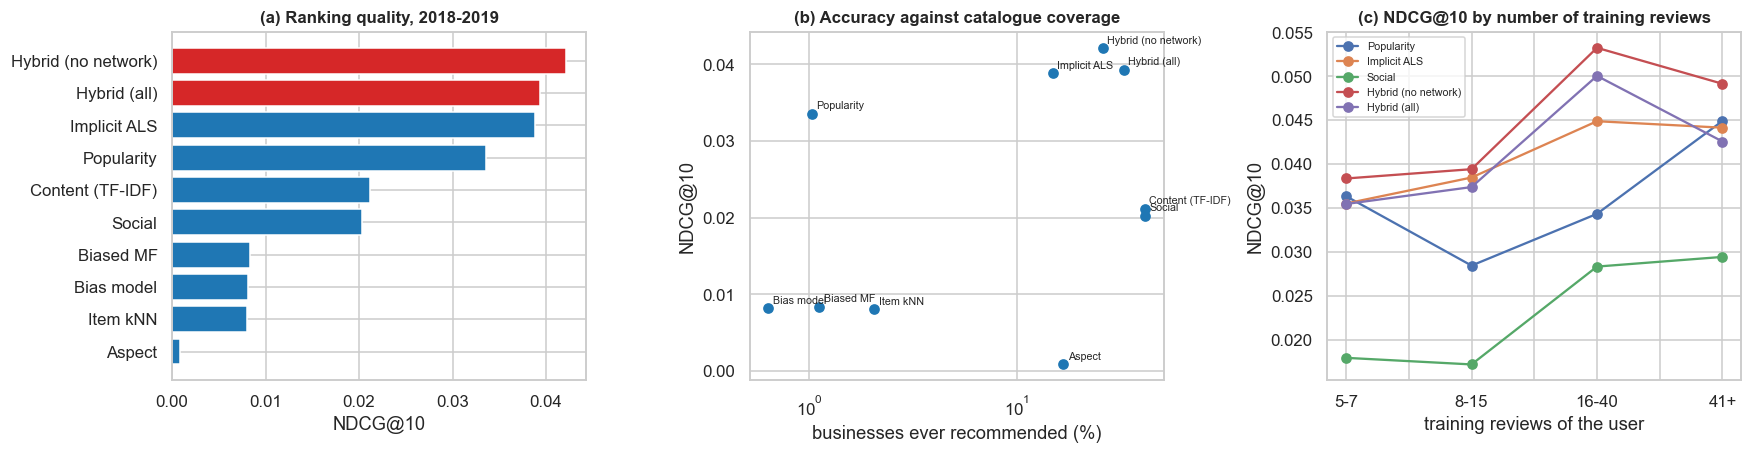

An example user recently liked: Knapp Nursery, Nikka Ramen, Anna's Marketplace Bakery, Meun Fan Thai Cafe
Recommended by the hybrid (* = the user did review it with 4+ stars in 2018-2019):
  * Kyle's Kitchen (Restaurants, Goleta)
    Finch & Fork (Restaurants, Santa Barbara)
    Zaytoon (Restaurants, Santa Barbara)
    Red Pepper Restaurant (Restaurants, Goleta)
    Lure Fish House (Restaurants, Santa Barbara)


17215

In [26]:
seg = pd.cut(REC["history"], [4, 7, 15, 40, 10 ** 6], labels=["5-7", "8-15", "16-40", "41+"])
bys = per_user[["Popularity", "Implicit ALS", "Social", "Hybrid (no network)", "Hybrid (all)"]].groupby(seg).mean()
bys.insert(0, "users", seg.value_counts().reindex(bys.index))
RESULTS["rec_by_history"] = bys
display(bys.round(4))

cold = REC["cold"]
RESULTS["rec_cold_start"] = cold.groupby("friends_active")[["Popularity", "Friends only", "Popularity + friends"]].mean().assign(users=cold.groupby("friends_active").size())
print("Cold-start users, NDCG@10 (the weight 0.7 was fixed in advance, not tuned on these users):")
display(RESULTS["rec_cold_start"].round(4))
m_, lo, hi = paired_boot(cold.loc[cold["friends_active"], "Popularity + friends"], cold.loc[cold["friends_active"], "Popularity"])
print(f"Popularity + friends - Popularity, among users with active friends: {m_:+.4f} (95 % CI {lo:+.4f} to {hi:+.4f})")

fig, ax = plt.subplots(1, 3, figsize=(16, 4.2))
t = RESULTS["rec_ranking"].sort_values("NDCG@10")
ax[0].barh(t.index, t["NDCG@10"], color=["tab:red" if "Hybrid" in n else "tab:blue" for n in t.index]); ax[0].set(title="(a) Ranking quality, 2018-2019", xlabel="NDCG@10")
ax[1].scatter(t["Coverage_%"], t["NDCG@10"], color="tab:blue")
for n, r_ in t.iterrows():
    ax[1].annotate(n, (r_["Coverage_%"], r_["NDCG@10"]), fontsize=7, xytext=(3, 3), textcoords="offset points")
ax[1].set(title="(b) Accuracy against catalogue coverage", xlabel="businesses ever recommended (%)", ylabel="NDCG@10", xscale="symlog")
bys.drop(columns="users").plot(ax=ax[2], marker="o"); ax[2].legend(fontsize=7)
ax[2].set(title="(c) NDCG@10 by number of training reviews", xlabel="training reviews of the user", ylabel="NDCG@10")
savefig("recommender")
print("\n".join(REC["example"]))
del TXT; gc.collect()                                    # the review text is not needed after this point

**Cold start.** Friends alone do worse than popularity for new users, and adding them to popularity brings no reliable gain (+0.0007, CI includes 0). With 2,150 cold users who have active friends, this is a fairly clear null: friend data did not solve cold start here.

**Note on the network in the recommender.** The friendship list is a snapshot from the end of the data, so some friendships used here formed after the training cut-off. This can make the social model look better than it would have been in real use. The comparison of the hybrid with and without the network should therefore be read as an upper bound on the value of friends.

## 7. Time series: forecasting the stars

Two levels are used, because they answer different questions:

* **7.1-7.3 Aggregated series (overall and per friendship community), monthly.** Classic time-series modelling with clean series and classical models.
* **7.4-7.6 Business panel, quarterly.** The main forecast: next-quarter mean stars for each business, from one global model trained across businesses. A single business's series is too short and noisy for its own complex model, but businesses can share what is learned.

### 7.1 Diagnostics of the aggregated series

Mean stars per month from 2012, when volume is high enough. Diagnostics: decomposition into trend, season and remainder (STL), stationarity (ADF, KPSS) and autocorrelation.

Median reviews per month: {'Overall': 2744, 'C0': 454, 'C4': 340, 'C1': 187, 'C2': 141, 'C5': 114, 'C3': 98}


C:\Users\iscap\AppData\Local\Temp\ipykernel_9236\1090838232.py:44: InterpolationWarning: The test statistic is outside of the range of p-values available in the
look-up table. The actual p-value is smaller than the p-value returned.

  return {"ADF p": adfuller(s.dropna(), autolag="AIC")[1], "KPSS p": kpss(s.dropna(), regression="c", nlags="auto")[1]}
C:\Users\iscap\AppData\Local\Temp\ipykernel_9236\1090838232.py:44: InterpolationWarning: The test statistic is outside of the range of p-values available in the
look-up table. The actual p-value is greater than the p-value returned.

  return {"ADF p": adfuller(s.dropna(), autolag="AIC")[1], "KPSS p": kpss(s.dropna(), regression="c", nlags="auto")[1]}
C:\Users\iscap\AppData\Local\Temp\ipykernel_9236\1090838232.py:44: InterpolationWarning: The test statistic is outside of the range of p-values available in the
look-up table. The actual p-value is smaller than the p-value returned.

  return {"ADF p": adfuller(s.dropna(), autolag="AIC")[1],

,ADF p,KPSS p
"stars, level",0.293,0.01
"stars, first difference",0.000,0.10
seasonal difference (12),0.786,0.01


STL strength: trend F_T = 0.88, seasonality F_S = 0.24. (Note: KPSS p-values are bounded to the range 0.01-0.10.)


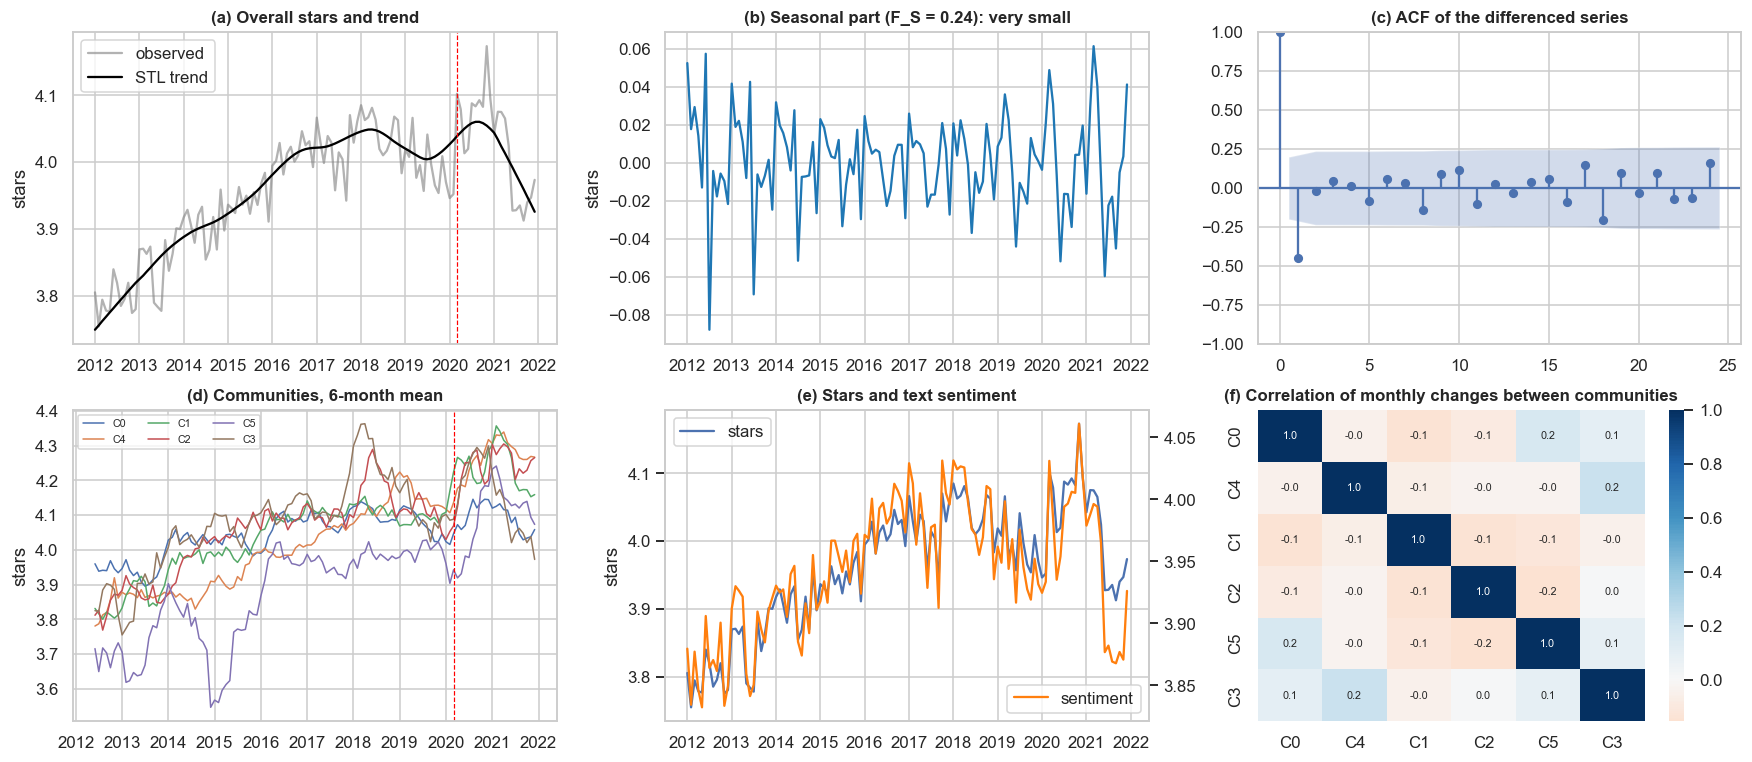

In [27]:
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.seasonal import STL
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.tsa.stattools import adfuller, grangercausalitytests, kpss
from statsmodels.stats.multitest import multipletests

TS_IDX = pd.date_range("2012-01-01", "2021-12-01", freq="MS")
Rm_ = R[(R["month"] >= TS_IDX[0]) & (R["month"] <= TS_IDX[-1])]
series = {"Overall": Rm_.groupby("month")["stars"].mean().reindex(TS_IDX)}
sent_s = {"Overall": Rm_.groupby("month")["sent_lr"].mean().reindex(TS_IDX)}
gap_s = {"Overall": Rm_.groupby("month")["gap"].mean().reindex(TS_IDX)}
count_s = {"Overall": Rm_.groupby("month").size().reindex(TS_IDX).fillna(0)}
for c in top_comm:
    g = Rm_[Rm_["community"] == c]
    gm = g.groupby("month")
    name = f"C{c}"
    series[name] = gm["stars"].mean().reindex(TS_IDX)
    sent_s[name] = gm["sent_lr"].mean().reindex(TS_IDX)
    gap_s[name] = gm["gap"].mean().reindex(TS_IDX)
    count_s[name] = gm.size().reindex(TS_IDX).fillna(0)
Y = pd.DataFrame(series).interpolate(limit_direction="both")
SENT = pd.DataFrame(sent_s).interpolate(limit_direction="both")
GAP = pd.DataFrame(gap_s).interpolate(limit_direction="both")
CNT = pd.DataFrame(count_s)
print("Median reviews per month:", CNT.median().astype(int).to_dict())

# network-weighted stars of the OTHER communities: weights = friendship edges from community c to community d
comm_of = NODES["community"].reindex(np.arange(n_users)).values
ca, cb = comm_of[EDGES["a"].values], comm_of[EDGES["b"].values]
Wc = pd.DataFrame(0.0, index=top_comm, columns=top_comm)
for x_, y_ in zip(ca, cb):
    if x_ in Wc.index and y_ in Wc.index and x_ != y_:
        Wc.loc[x_, y_] += 1; Wc.loc[y_, x_] += 1
Wc = Wc.div(Wc.sum(1), axis=0).fillna(0)
NETLAG = pd.DataFrame({f"C{c}": sum(Wc.loc[c, d] * Y[f"C{d}"] for d in top_comm if d != c) for c in top_comm}, index=TS_IDX)

y0 = Y["Overall"]
res = STL(y0, period=12, robust=True).fit()
F_trend = max(0, 1 - res.resid.var() / (res.trend + res.resid).var()); F_seas = max(0, 1 - res.resid.var() / (res.seasonal + res.resid).var())
pre = y0[y0.index < COVID_START]


def stat_tests(s):
    return {"ADF p": adfuller(s.dropna(), autolag="AIC")[1], "KPSS p": kpss(s.dropna(), regression="c", nlags="auto")[1]}


RESULTS["ts_stationarity"] = pd.DataFrame({"stars, level": stat_tests(pre), "stars, first difference": stat_tests(pre.diff()), "seasonal difference (12)": stat_tests(pre.diff(12))}).T
display(RESULTS["ts_stationarity"].round(3))
print(f"STL strength: trend F_T = {F_trend:.2f}, seasonality F_S = {F_seas:.2f}. (Note: KPSS p-values are bounded to the range 0.01-0.10.)")

fig, ax = plt.subplots(2, 3, figsize=(16, 7))
ax[0, 0].plot(y0.index, y0, color="grey", alpha=.6, label="observed"); ax[0, 0].plot(res.trend.index, res.trend, color="black", label="STL trend")
ax[0, 0].axvline(COVID_START, color="red", ls="--", lw=.8); ax[0, 0].legend(); ax[0, 0].set(title="(a) Overall stars and trend", ylabel="stars")
ax[0, 1].plot(res.seasonal.index, res.seasonal, color="tab:blue"); ax[0, 1].set(title=f"(b) Seasonal part (F_S = {F_seas:.2f}): very small", ylabel="stars")
plot_acf(pre.diff().dropna(), lags=24, ax=ax[0, 2]); ax[0, 2].set_title("(c) ACF of the differenced series")
for c in Y.columns[1:]:
    ax[1, 0].plot(Y.index, Y[c].rolling(6).mean(), lw=1, label=c)
ax[1, 0].axvline(COVID_START, color="red", ls="--", lw=.8); ax[1, 0].legend(ncol=3, fontsize=7); ax[1, 0].set(title="(d) Communities, 6-month mean", ylabel="stars")
ax[1, 1].plot(y0.index, y0, label="stars"); axb = ax[1, 1].twinx(); axb.plot(SENT.index, SENT["Overall"], color="tab:orange", label="sentiment"); ax[1, 1].set(title="(e) Stars and text sentiment", ylabel="stars"); axb.grid(False)
ax[1, 1].legend(loc="upper left"); axb.legend(loc="lower right")
sns.heatmap(Y.iloc[:, 1:].diff().corr(), cmap="RdBu", center=0, annot=True, fmt=".1f", annot_kws={"size": 7}, ax=ax[1, 2]); ax[1, 2].set_title("(f) Correlation of monthly changes between communities")
savefig("ts_diagnostics")

### 7.2 Forecasting the aggregated series

**Rolling origin.** At each month the models are refitted with data up to that month and forecast 1 and 3 months ahead. Origins are evaluated separately before COVID (2018-2019) and during COVID (2020-2021).

**Models.** Long-run mean, last value, 12-month mean, seasonal naive, simple exponential smoothing, ARIMA and seasonal ARIMA, and then ARIMAX with lagged inputs. The diagnostics above found a non-stationary level that becomes stationary after one difference and very weak seasonality, hence `d = 1`, and a seasonal term only as a comparison:

* **+ sentiment**: last month's sentiment and sentiment-star gap of the same series;
* **+ network**: last month's stars of the other communities, weighted by friendship ties between communities (a *network lag*);
* **+ both**.

Inputs are lagged by one month, and the last known value is held constant for the 3-month forecast, so no future value is used.

**Metric.** MAE and MASE, where below 1 means better than the last-value forecast on the training data. The Diebold-Mariano test compares each model with ARIMA(0,1,1). The network lag exists only for communities, so all models are compared on the same community series.

In [28]:
def f_mean(y_, h, *_): return np.full(h, y_.mean())
def f_last(y_, h, *_): return np.full(h, y_.iloc[-1])
def f_ma12(y_, h, *_): return np.full(h, y_.iloc[-12:].mean())
def f_snaive(y_, h, *_): return np.array([y_.iloc[-12 + (i % 12)] for i in range(h)])


def f_ses(y_, h, *_):
    best, sse = None, np.inf
    v = y_.values
    for a in (.05, .1, .2, .3, .5):
        l_ = v[0]; e = 0
        for x_ in v[1:]:
            e += (x_ - l_) ** 2; l_ = a * x_ + (1 - a) * l_
        if e < sse:
            sse, best = e, l_
    return np.full(h, best)


def sarimax_forecast(y_, h, X=None, Xf=None, order=(0, 1, 1), seasonal=(0, 0, 0, 0)):
    m = SARIMAX(y_.values, exog=X, order=order, seasonal_order=seasonal, trend="n", enforce_stationarity=False, enforce_invertibility=False)
    return m.fit(disp=False, maxiter=60).forecast(h, exog=Xf)


def exog_for(name, kinds):
    cols = []
    if "sent" in kinds:
        cols += [SENT[name].rename("sent"), GAP[name].rename("gap")]
    if "net" in kinds and name in NETLAG:
        cols += [NETLAG[name].rename("netlag")]
    return pd.concat(cols, axis=1).shift(1) if cols else None


def run_series(name, H=3):
    y_all = Y[name]
    rows = []
    ex_sets = {"ARIMAX + sentiment": ("sent",), "ARIMAX + network": ("net",), "ARIMAX + both": ("sent", "net")}
    exogs = {k: exog_for(name, v) for k, v in ex_sets.items()}
    origins = pd.date_range("2017-12-01", "2021-09-01", freq="MS")
    for o in origins:
        tr = y_all[:o]
        act = y_all[o + pd.DateOffset(months=1): o + pd.DateOffset(months=H)].values
        fc = {"Long-run mean": f_mean(tr, H), "Last value": f_last(tr, H), "12-month mean": f_ma12(tr, H), "Seasonal naive": f_snaive(tr, H), "SES": f_ses(tr, H)}
        scale = np.abs(tr.diff().dropna()).mean()
        for label, kw in (("ARIMA(0,1,1)", {}), ("ARIMA(1,1,1)", {"order": (1, 1, 1)}), ("SARIMA(0,1,1)(1,0,0,12)", {"seasonal": (1, 0, 0, 12)})):
            try:
                fc[label] = sarimax_forecast(tr, H, **kw)
            except Exception:
                fc[label] = f_mean(tr, H)
        for label, ex in exogs.items():
            if ex is None or ("network" in label and name not in NETLAG) or ("both" in label and name not in NETLAG):
                continue
            Xtr = ex.loc[tr.index].bfill().values
            Xf = np.tile(ex.loc[o + pd.DateOffset(months=1)].values, (H, 1))
            try:
                fc[label] = sarimax_forecast(tr, H, X=Xtr, Xf=Xf)
            except Exception:
                fc[label] = f_mean(tr, H)
        for model, f_ in fc.items():
            for h_, (a_, p_) in enumerate(zip(act, f_), 1):
                rows.append((name, model, o + pd.DateOffset(months=h_), h_, a_, p_, scale))
    return rows


def compute_ts_backtest():
    res_ = Parallel(n_jobs=N_JOBS)(delayed(run_series)(n) for n in Y.columns)
    return pd.DataFrame([r_ for rr in res_ for r_ in rr], columns=["series", "model", "target", "h", "actual", "pred", "scale"])


BT = cached("ts_backtest", compute_ts_backtest)
BT["ae"] = (BT["actual"] - BT["pred"]).abs(); BT["se"] = (BT["actual"] - BT["pred"]) ** 2
BT["ase"] = BT["ae"] / BT["scale"]
BT["period"] = np.where(BT["target"] < COVID_START, "before COVID", "COVID")


def dm_test(e1, e2, h=1):
    """Diebold-Mariano on squared errors, with the Harvey small-sample correction."""
    d = np.asarray(e1) - np.asarray(e2); n = len(d)
    if n < 8 or np.allclose(d, 0):
        return np.nan
    v = d.var(ddof=0)
    for k in range(1, h):
        v += 2 * np.cov(d[k:], d[:-k], ddof=0)[0, 1]
    if v <= 0:
        return np.nan
    t_ = d.mean() / np.sqrt(v / n) * np.sqrt((n + 1 - 2 * h + h * (h - 1) / n) / n)
    return 2 * stats.t.sf(abs(t_), n - 1)


# the network lag only exists for communities, so all models are compared on the same community series
BTc = BT[BT["series"] != "Overall"]
summ = BTc[BTc["period"] == "before COVID"].groupby(["h", "model"]).agg(MAE=("ae", "mean"), RMSE=("se", lambda s: np.sqrt(s.mean())), MASE=("ase", "mean"))
cov = BTc[BTc["period"] == "COVID"].groupby(["h", "model"]).agg(MAE_COVID=("ae", "mean"), MASE_COVID=("ase", "mean"))
tab = summ.join(cov).unstack("h")
RESULTS["ts_community_backtest"] = tab.sort_values(("MAE", 1))
print(f"Mean over the {BTc['series'].nunique()} communities:")
display(RESULTS["ts_community_backtest"].round(3))
ov = BT[BT["series"] == "Overall"].groupby(["period", "model"]).agg(MAE=("ae", "mean"), MASE=("ase", "mean")).unstack("period")
RESULTS["ts_overall_backtest"] = ov.sort_values(("MAE", "before COVID"))
print("Overall series, all horizons:")
display(RESULTS["ts_overall_backtest"].round(3))

rows = []
for period in ("before COVID", "COVID"):
    for (series_, h_), g in BTc[BTc["period"] == period].groupby(["series", "h"]):
        if h_ != 1:
            continue
        base = g[g["model"] == "ARIMA(0,1,1)"].sort_values("target")["se"].values
        for model, gm_ in g.groupby("model"):
            if model == "ARIMA(0,1,1)":
                continue
            rows.append({"period": period, "series": series_, "model": model, "MSE ratio": gm_["se"].mean() / base.mean(), "DM p": dm_test(gm_.sort_values("target")["se"].values, base)})
dm = pd.DataFrame(rows)
dm["better"] = (dm["MSE ratio"] < 1) & (dm["DM p"] < .05); dm["worse"] = (dm["MSE ratio"] > 1) & (dm["DM p"] < .05)
RESULTS["ts_community_dm"] = dm.groupby(["period", "model"]).agg(mean_MSE_ratio=("MSE ratio", "mean"), series_with_lower_MSE=("MSE ratio", lambda s: int((s < 1).sum())), significantly_better=("better", "sum"), significantly_worse=("worse", "sum"), series=("MSE ratio", "size")).sort_values(["period", "mean_MSE_ratio"])
print("One month ahead, against ARIMA(0,1,1) on the same community series (MSE ratio < 1 means better; DM test at 5 %):")
display(RESULTS["ts_community_dm"].round(3))

Mean over the 6 communities:


MAE                 RMSE                 MASE  \
h                            1      2      3      1      2      3      1   
model                                                                      
ARIMAX + sentiment       0.086  0.086  0.085  0.112  0.110  0.111  0.702   
SES                      0.086  0.086  0.086  0.111  0.111  0.111  0.702   
ARIMA(0,1,1)             0.086  0.086  0.086  0.112  0.111  0.111  0.706   
ARIMAX + network         0.087  0.087  0.086  0.113  0.112  0.111  0.712   
12-month mean            0.087  0.086  0.085  0.115  0.113  0.114  0.711   
ARIMA(1,1,1)             0.087  0.086  0.086  0.113  0.111  0.111  0.715   
ARIMAX + both            0.087  0.088  0.086  0.114  0.112  0.111  0.716   
SARIMA(0,1,1)(1,0,0,12)  0.087  0.089  0.089  0.113  0.113  0.113  0.716   
Last value               0.106  0.112  0.111  0.138  0.143  0.138  0.860   
Seasonal naive           0.117  0.117  0.115  0.157  0.158  0.155  0.946   
Long-run mean            0.137  0.134  0.134  0.168  0.163  0.162  1.144   

                                      MAE_COVID               MASE_COVID  \
h                            2      3         1      2      3          1   
model                                                                      
ARIMAX + sentiment       0.710  0.706     0.110  0.116  0.122      0.888   
SES                      0.708  0.710     0.109  0.113  0.119      0.892   
ARIMA(0,1,1)             0.710  0.710     0.109  0.114  0.119      0.893   
ARIMAX + network         0.720  0.715     0.108  0.113  0.119      0.880   
12-month mean            0.704  0.704     0.117  0.123  0.127      0.951   
ARIMA(1,1,1)             0.710  0.709     0.110  0.114  0.120      0.896   
ARIMAX + both            0.723  0.715     0.107  0.116  0.124      0.867   
SARIMA(0,1,1)(1,0,0,12)  0.734  0.734     0.112  0.116  0.119      0.916   
Last value               0.919  0.922     0.133  0.153  0.144      1.093   
Seasonal naive           0.948  0.936     0.179  0.179  0.181      1.442   
Long-run mean            1.122  1.121     0.202  0.200  0.201      1.675   

                                       
h                            2      3  
model                                  
ARIMAX + sentiment       0.943  0.981  
SES                      0.924  0.960  
ARIMA(0,1,1)             0.929  0.962  
ARIMAX + network         0.916  0.953  
12-month mean            0.991  1.019  
ARIMA(1,1,1)             0.931  0.964  
ARIMAX + both            0.936  0.989  
SARIMA(0,1,1)(1,0,0,12)  0.946  0.958  
Last value               1.229  1.172  
Seasonal naive           1.438  1.454  
Long-run mean            1.661  1.672

Overall series, all horizons:


MAE                MASE             
period                   COVID before COVID  COVID before COVID
model                                                          
ARIMA(1,1,1)             0.055        0.032  1.577        0.939
SARIMA(0,1,1)(1,0,0,12)  0.056        0.032  1.607        0.940
ARIMA(0,1,1)             0.054        0.032  1.550        0.940
ARIMAX + sentiment       0.055        0.032  1.588        0.953
SES                      0.054        0.032  1.533        0.955
Last value               0.053        0.036  1.530        1.069
12-month mean            0.077        0.037  2.194        1.089
Seasonal naive           0.099        0.050  2.824        1.472
Long-run mean            0.095        0.076  2.711        2.268

One month ahead, against ARIMA(0,1,1) on the same community series (MSE ratio < 1 means better; DM test at 5 %):


mean_MSE_ratio  series_with_lower_MSE  \
period       model                                                            
COVID        ARIMAX + both                     0.982                      3   
             ARIMAX + network                  0.987                      4   
             SES                               0.987                      5   
             ARIMAX + sentiment                1.001                      3   
             ARIMA(1,1,1)                      1.005                      1   
             SARIMA(0,1,1)(1,0,0,12)           1.018                      2   
             12-month mean                     1.109                      1   
             Last value                        1.460                      0   
             Seasonal naive                    2.299                      0   
             Long-run mean                     3.069                      0   
before COVID SES                               0.990                      5   
             ARIMAX + sentiment                1.001                      3   
             ARIMAX + network                  1.024                      1   
             ARIMA(1,1,1)                      1.028                      0   
             ARIMAX + both                     1.038                      1   
             12-month mean                     1.041                      2   
             SARIMA(0,1,1)(1,0,0,12)           1.043                      1   
             Last value                        1.444                      0   
             Seasonal naive                    1.902                      0   
             Long-run mean                     2.519                      0   

                                      significantly_better  \
period       model                                           
COVID        ARIMAX + both                               0   
             ARIMAX + network                            0   
             SES                                         0   
             ARIMAX + sentiment                          0   
             ARIMA(1,1,1)                                0   
             SARIMA(0,1,1)(1,0,0,12)                     0   
             12-month mean                               0   
             Last value                                  0   
             Seasonal naive                              0   
             Long-run mean                               0   
before COVID SES                                         0   
             ARIMAX + sentiment                          0   
             ARIMAX + network                            0   
             ARIMA(1,1,1)                                0   
             ARIMAX + both                               0   
             12-month mean                               0   
             SARIMA(0,1,1)(1,0,0,12)                     0   
             Last value                                  0   
             Seasonal naive                              0   
             Long-run mean                               0   

                                      significantly_worse  series  
period       model                                                 
COVID        ARIMAX + both                              0       6  
             ARIMAX + network                           0       6  
             SES                                        0       6  
             ARIMAX + sentiment                         0       6  
             ARIMA(1,1,1)                               0       6  
             SARIMA(0,1,1)(1,0,0,12)                    0       6  
             12-month mean                              0       6  
             Last value                                 1       6  
             Seasonal naive                             5       6  
             Long-run mean                              4       6  
before COVID SES                                        0       6  
             ARIMAX + sentiment                   

**Reading the results.** Simple level-tracking models win: SES and ARIMA(0,1,1), which are nearly the same model, are as good as anything else. The long-run mean and seasonal naive are clearly worst, as the diagnostics suggested: a slowly moving level with very little seasonality (F_S = 0.24). Lagged sentiment and the network lag give **no reliable gain** on the same community series (mean MSE ratio about 1.00-1.04 before COVID, with none significantly better in the Diebold-Mariano tests). During COVID the network lag has a slightly lower error (0.98-0.99), which is not significant either.

### 7.3 Do text and network lead ratings? Granger tests

Granger causality here means only that lags of one series **help to predict** another: it says nothing about a real causal mechanism. Tests use changes in the monthly series before COVID (2012 to February 2020), 3 lags, and the Holm correction for the number of tests. Three directions are tested for each community: sentiment -> stars, stars -> sentiment, and network lag -> stars.

In [29]:
rows = []
win = Y.index < COVID_START
for name in Y.columns:
    d_ = pd.DataFrame({"stars": Y[name], "sent": SENT[name], "gap": GAP[name], **({"net": NETLAG[name]} if name in NETLAG else {})})[win].diff().dropna()
    pairs = [("sent", "stars", "sentiment -> stars"), ("stars", "sent", "stars -> sentiment"), ("gap", "stars", "gap -> stars")]
    if "net" in d_:
        pairs.append(("net", "stars", "network lag -> stars"))
    for cause, effect, label in pairs:
        r_ = grangercausalitytests(d_[[effect, cause]], maxlag=3, verbose=False)[3][0]["ssr_ftest"]
        rows.append({"series": name, "test": label, "F": r_[0], "p": r_[1]})
gr = pd.DataFrame(rows)
gr["p_holm"] = multipletests(gr["p"], method="holm")[1]
RESULTS["granger"] = gr.pivot(index="series", columns="test", values="p_holm")
print("Holm-adjusted p-values:")
display(RESULTS["granger"].round(3))
print("Significant after Holm:", gr[gr["p_holm"] < .05][["series", "test"]].values.tolist() or "none", "| unadjusted p < 0.05:", int((gr["p"] < .05).sum()), "of", len(gr))

Holm-adjusted p-values:


test,gap -> stars,network lag -> stars,sentiment -> stars,stars -> sentiment
series,,,,
C0,1.000,1.0,1.000,1.000
C1,0.411,1.0,0.411,0.611
C2,0.556,1.0,0.556,0.611
C3,1.000,1.0,1.000,1.000
C4,1.000,1.0,1.000,1.000
C5,1.000,1.0,1.000,1.000
Overall,1.000,NaN,1.000,1.000


Significant after Holm: none | unadjusted p < 0.05: 6 of 27


**Reading the Granger tests.** No relation survives the Holm correction. Text, stars and neighbouring communities do not visibly lead each other from month to month at this level of aggregation. The 6 of 27 tests with an unadjusted p below 0.05 are more than chance alone would suggest, but too weak to rely on, so these are not reported as findings.

### 7.4 The business panel: data and baselines

**Businesses.** At least 50 reviews **before 2018**, so that the selection does not depend on the future.

**Target.** Mean stars of the business in the next quarter, kept when that quarter has at least 3 reviews. Errors are weighted by the number of reviews, because a mean of 40 reviews is more reliable than a mean of 3.

**Test design (walk-forward).** For each quarter from 2018Q1 to 2021Q4, models are retrained on all earlier rows whose target has already happened. 2016-2017 serves for choosing hyperparameters. Results are split into before COVID and COVID.

**Baselines.** Global mean, last quarter, mean of the last 4 quarters, the business's long-run mean, exponential smoothing, and an **empirical-Bayes mean** (the long-run mean shrunk towards the overall mean, more when a business has few reviews). The diagnostics show ratings as a noisy signal around a stable level, so this is a tough baseline.

**Noise limit.** A mean of *n* reviews has sampling noise even when the business's quality is perfectly known. We estimate this floor: the error that even a model knowing the true level of each business could not avoid.

**Three groups of inputs**, all from reviews written before the target quarter:

| Group | Inputs |
|---|---|
| **History** | past stars at several horizons, trend, volume, age, season, category, overall market level |
| **Sentiment** | mean sentiment and sentiment-star gap, recent and relative to the business's own past; aspect sentiment (food, service, price, ambience, wait, clean) |
| **Network** | *friendship:* how connected and Elite recent reviewers are, the share with a friend who reviewed earlier, opinions weighted by PageRank, recent mood of the reviewers' friends, how generous the likely next audience is, the mood of the main community. *co-review (dated):* the business's centrality in last year's co-review graph; recent stars and sentiment at its co-review neighbours |

In [30]:
PQ = pd.period_range("2008Q1", "2021Q4", freq="Q")
qi = {p: i for i, p in enumerate(PQ)}
early = R[R["date"] < "2018-01-01"].groupby("b").size()
PANEL_B = early[early >= 50].index.values
pb = pd.Series(np.arange(len(PANEL_B)), index=PANEL_B)
Rp = R[R["b"].isin(PANEL_B) & (R["q"] >= PQ[0]) & (R["q"] <= PQ[-1])].copy()
Rp["qi"] = Rp["q"].map(qi).astype(int); Rp["pb"] = Rp["b"].map(pb).astype(int)
nB, nQ = len(PANEL_B), len(PQ)
print(f"Panel: {nB} businesses, {len(Rp):,} reviews ({len(Rp) / len(R):.0%} of all), {nQ} quarters")


def grid_sum(df, col=None):
    """nB x nQ matrix with the sum of a column (or a count)."""
    M = np.zeros((nB, nQ))
    v = np.ones(len(df)) if col is None else df[col].fillna(0).values.astype(float)
    np.add.at(M, (df["pb"].values, df["qi"].values), v)
    return M


def roll(M, k):
    """Sum over the last k quarters, including the current one."""
    c = np.cumsum(M, axis=1)
    out = c.copy()
    out[:, k:] = c[:, k:] - c[:, :-k]
    return out


def safe(a, b):
    return np.where(b > 0, a / np.where(b > 0, b, 1), np.nan)


N = grid_sum(Rp); S = grid_sum(Rp, "stars"); S2 = grid_sum(Rp.assign(s2=Rp["stars"] ** 2), "s2")
cumN, cumS = np.cumsum(N, 1), np.cumsum(S, 1)
glob_q = S.sum(0) / np.maximum(N.sum(0), 1)
glob_cum = cumS.sum(0) / np.maximum(cumN.sum(0), 1)

# ---------- history features ----------
HIST = {}
qmean = safe(S, N)
for lag in range(4):
    a = np.full_like(qmean, np.nan); a[:, lag:] = qmean[:, :nQ - lag]
    HIST[f"stars_l{lag}"] = a
HIST["stars_4q"] = safe(roll(S, 4), roll(N, 4)); HIST["stars_8q"] = safe(roll(S, 8), roll(N, 8))
HIST["stars_all"] = safe(cumS, cumN)
EB_K = 10
HIST["eb_mean"] = (cumS + EB_K * glob_cum[None, :]) / (cumN + EB_K)
HIST["trend_4v8"] = HIST["stars_4q"] - safe(roll(S, 12) - roll(S, 4), roll(N, 12) - roll(N, 4))
HIST["dev_4q"] = HIST["stars_4q"] - HIST["stars_all"]
HIST["log_n"] = np.log1p(N); HIST["log_n4"] = np.log1p(roll(N, 4)); HIST["log_cum"] = np.log1p(cumN)
var_all = safe(np.cumsum(S2, 1), cumN) - HIST["stars_all"] ** 2
HIST["std_all"] = np.sqrt(np.clip(var_all, 0, None))
HIST["age_q"] = np.cumsum(cumN > 0, 1).astype(float)
HIST["market"] = np.tile(glob_q, (nB, 1)); HIST["market_4q"] = np.tile(pd.Series(glob_q).rolling(4, min_periods=1).mean().values, (nB, 1))

# exponential smoothing on the review stream of each quarter (level updated with weight depending on n)
def ewma_panel(alpha):
    L = np.full((nB, nQ), np.nan)
    level = np.full(nB, np.nan)
    for t in range(nQ):
        has = N[:, t] > 0
        w = 1 - (1 - alpha) ** N[:, t]
        new = np.where(np.isnan(level), qmean[:, t], level + w * (np.nan_to_num(qmean[:, t]) - level))
        level = np.where(has, new, level)
        L[:, t] = level
    return L


# ---------- sentiment features ----------
SENTF = {}
for name, col in (("sent", "sent_lr"), ("gap", "gap"), ("vader", "vader")):
    s_ = grid_sum(Rp, col)
    SENTF[f"{name}_l0"] = safe(s_, N); SENTF[f"{name}_4q"] = safe(roll(s_, 4), roll(N, 4)); SENTF[f"{name}_all"] = safe(np.cumsum(s_, 1), cumN)
    SENTF[f"{name}_dev4"] = SENTF[f"{name}_4q"] - SENTF[f"{name}_all"]
for a in ASPECTS:
    col = f"asp_{a}"
    s_ = grid_sum(Rp, col); c_ = grid_sum(Rp[Rp[col].notna()])
    SENTF[f"{col}_4q"] = safe(roll(s_, 4), roll(c_, 4)); SENTF[f"{col}_all"] = safe(np.cumsum(s_, 1), np.cumsum(c_, 1))
    SENTF[f"{col}_dev4"] = SENTF[f"{col}_4q"] - SENTF[f"{col}_all"]
    SENTF[f"{col}_share4"] = safe(roll(c_, 4), roll(N, 4))
print(f"History features: {len(HIST)} | sentiment features: {len(SENTF)}")

Panel: 932 businesses, 239,470 reviews (69% of all), 56 quarters
History features: 17 | sentiment features: 36


In [31]:
# ---------- network features ----------
def exposed_flags(adj):
    """For each panel review: did a friend (in graph adj) review the same business earlier?"""
    p_, i_ = adj.indptr, adj.indices
    out = np.zeros(len(Rp), dtype=bool)
    order = np.lexsort((Rp["day"].values, Rp["pb"].values))
    pb_, uu_, dd_ = Rp["pb"].values[order], Rp["u"].values[order], Rp["day"].values[order]
    cut = np.r_[0, np.flatnonzero(np.diff(pb_)) + 1, len(pb_)]
    for s, e in zip(cut[:-1], cut[1:]):
        seen = set()
        for k in range(s, e):
            v = uu_[k]
            nb = i_[p_[v]:p_[v + 1]]
            if len(nb) and seen:
                if len(nb) <= len(seen):
                    out[order[k]] = any(int(x) in seen for x in nb)
                else:
                    nbs = set(nb.tolist())
                    out[order[k]] = any(x in nbs for x in seen)
            seen.add(int(v))
    return out


def network_features(adj, pr, comm, label):
    """All friendship-based features for a given graph. A rewired graph gives the placebo."""
    F = {}
    df = Rp[["pb", "qi", "u", "stars", "dev", "lenient"]].copy()
    df["ld"] = np.log1p(np.asarray(adj.sum(1)).ravel()[df["u"].values])
    df["conn"] = (df["ld"] > 0).astype(float)
    df["pr"] = pr[df["u"].values]
    df["pr_stars"] = df["pr"] * df["stars"]
    df["exposed"] = exposed_flags(adj).astype(float)
    df["exp_dev"] = df["exposed"] * df["dev"].fillna(0)
    df["cid"] = comm[df["u"].values]
    for col in ("ld", "conn", "exposed"):
        F[f"net_{col}_4q"] = safe(roll(grid_sum(df, col), 4), roll(N, 4))
    w4 = roll(grid_sum(df, "pr"), 4)
    F["net_pr_stars_gap"] = safe(roll(grid_sum(df, "pr_stars"), 4), w4) - HIST["stars_4q"]
    F["net_top_pr_share"] = safe(w4, roll(N, 4))
    F["net_exposed_dev_4q"] = safe(roll(grid_sum(df, "exp_dev"), 4), roll(grid_sum(df, "exposed"), 4))
    # mood of the friends of recent reviewers, over all businesses, and generosity of the likely next audience
    allR = R[(R["q"] >= PQ[0]) & (R["q"] <= PQ[-1]) & R["dev"].notna()]
    aq = allR["q"].map(qi).astype(int).values
    au, ad = allR["u"].values, allR["dev"].values
    mood, aud = np.full((nB, nQ), np.nan), np.full((nB, nQ), np.nan)
    cmood = np.full((nB, nQ), np.nan); cshare = np.full((nB, nQ), np.nan)
    sum_all = np.zeros(n_users); cnt_all = np.zeros(n_users)
    order = np.argsort(aq, kind="stable"); au, ad, aq = au[order], ad[order], aq[order]
    starts = np.searchsorted(aq, np.arange(nQ + 1))
    pre_q = df[["pb", "qi", "u"]].drop_duplicates()
    for t in range(nQ):
        idx = np.arange(starts[t], starts[t + 1])
        qsum = np.bincount(au[idx], ad[idx], n_users); qcnt = np.bincount(au[idx], minlength=n_users).astype(float)
        sum_all += qsum; cnt_all += qcnt
        rec = pre_q[(pre_q["qi"] <= t) & (pre_q["qi"] > t - 4)]
        if len(rec) == 0:
            continue
        Bq = sp.csr_matrix((np.ones(len(rec)), (rec["pb"].values, rec["u"].values)), shape=(nB, n_users))
        Bq.data[:] = 1
        fm_s, fm_c = adj @ qsum, adj @ qcnt
        num, den = Bq @ fm_s, Bq @ fm_c
        mood[:, t] = safe(num, den)
        # generosity of friends, using only the past: mean of their earlier deviations
        ls = adj @ np.where(cnt_all > 0, sum_all / np.where(cnt_all > 0, cnt_all, 1), 0.0); lc = adj @ (cnt_all > 0).astype(float)
        aud[:, t] = safe(Bq @ ls, Bq @ lc)
        # community mood weighted by the community mix of recent reviewers
        valid = comm[au[idx]] >= 0
        cs = np.bincount(comm[au[idx]][valid], ad[idx][valid], minlength=COMM_MAX); cc = np.bincount(comm[au[idx]][valid], minlength=COMM_MAX).astype(float)
        cm_ = safe(cs, cc)
        rv = rec[comm[rec["u"].values] >= 0]
        if len(rv):
            rc = comm[rv["u"].values]
            has = np.isfinite(cm_[rc])
            nm = np.bincount(rv["pb"].values[has], cm_[rc][has], minlength=nB); dn = np.bincount(rv["pb"].values[has], minlength=nB).astype(float)
            cmood[:, t] = safe(nm, dn)
            mat = sp.csr_matrix((np.ones(len(rv)), (rv["pb"].values, rc)), shape=(nB, COMM_MAX))
            cshare[:, t] = safe(np.asarray(mat.max(axis=1).todense()).ravel(), np.asarray(mat.sum(1)).ravel())
    F["net_friend_mood"] = mood; F["net_audience_generosity"] = aud; F["net_comm_mood"] = cmood; F["net_top_comm_share"] = cshare
    return F


def coreview_features(permute=None):
    """Dated features from last year's business co-review graph. `permute` shuffles the business identities (placebo)."""
    F = {k: np.full((nB, nQ), np.nan) for k in ("cr_pagerank", "cr_nb_dev", "cr_nb_sent", "cr_nb_stars_4q")}
    b_all = len(biz)
    allR = R[(R["q"] >= PQ[0]) & (R["q"] <= PQ[-1])]
    aqi = allR["q"].map(qi).astype(int).values
    dev_ = np.zeros((b_all, nQ)); sent_ = np.zeros((b_all, nQ)); cnt_ = np.zeros((b_all, nQ)); st_ = np.zeros((b_all, nQ))
    np.add.at(dev_, (allR["b"].values, aqi), allR["dev"].fillna(0).values)
    np.add.at(sent_, (allR["b"].values, aqi), allR["sent_lr"].fillna(allR["sent_lr"].mean()).values - allR["sent_lr"].mean())
    np.add.at(st_, (allR["b"].values, aqi), allR["stars"].values)
    np.add.at(cnt_, (allR["b"].values, aqi), 1.0)
    for t, p_ in enumerate(PQ):
        y_ = p_.year - 1 if p_.quarter < 4 else p_.year                 # the Q4 forecast may use the finished year
        G_ = BIZ_G.get(y_)
        if G_ is None:
            continue
        pr_ = BIZ_PR[y_]
        idx = np.arange(b_all) if permute is None else permute
        Gs = G_[PANEL_B]
        F["cr_pagerank"][:, t] = np.log(pr_[idx[PANEL_B]] * b_all + 1e-3)
        Gw = Gs if permute is None else Gs[:, np.argsort(idx)]
        num_d, num_s, den_ = Gw @ dev_[:, t], Gw @ sent_[:, t], Gw @ cnt_[:, t]
        F["cr_nb_dev"][:, t] = safe(num_d, den_); F["cr_nb_sent"][:, t] = safe(num_s, den_)
        lo = max(0, t - 3)
        F["cr_nb_stars_4q"][:, t] = safe(Gw @ st_[:, lo:t + 1].sum(1), Gw @ cnt_[:, lo:t + 1].sum(1))
    return F


def stack_features(F):
    return pd.DataFrame({k: v.ravel() for k, v in F.items()})


COMM_MAX = int(NODES["community"].max()) + 2
comm_real = NODES["community"].reindex(np.arange(n_users)).fillna(-1).astype(int).values
pr_real = NODES["pagerank"].reindex(np.arange(n_users)).fillna(0).values * 1e4


def _real_net():
    return stack_features(network_features(A, pr_real, comm_real, "real"))


def _placebo_perm():
    return np.random.default_rng(SEED + 7).permutation(n_users)


def _placebo_net():
    perm = _placebo_perm()
    P_ = sp.csr_matrix((np.ones(n_users), (np.arange(n_users), perm)), shape=(n_users, n_users))
    A_rew = (P_ @ A @ P_.T).tocsr()
    return stack_features(network_features(A_rew, pr_real[np.argsort(perm)], comm_real[np.argsort(perm)], "placebo"))


NET_REAL = cached("panel_net_real", _real_net)
NET_PLAC = cached("panel_net_placebo", _placebo_net)
CR_REAL = cached("panel_cr_real", lambda: stack_features(coreview_features()))
CR_PLAC = cached("panel_cr_placebo", lambda: stack_features(coreview_features(np.random.default_rng(SEED + 8).permutation(len(biz)))))
print("Network features:", NET_REAL.columns.tolist(), CR_REAL.columns.tolist())

Network features: ['net_ld_4q', 'net_conn_4q', 'net_exposed_4q', 'net_pr_stars_gap', 'net_top_pr_share', 'net_exposed_dev_4q', 'net_friend_mood', 'net_audience_generosity', 'net_comm_mood', 'net_top_comm_share'] ['cr_pagerank', 'cr_nb_dev', 'cr_nb_sent', 'cr_nb_stars_4q']


In [32]:
def build_panel(h=1):
    """One row per business and forecast origin t; the target is the mean stars of quarter t + h."""
    b_idx, t_idx = np.meshgrid(np.arange(nB), np.arange(nQ), indexing="ij")
    D = pd.DataFrame({"pb": b_idx.ravel(), "t": t_idx.ravel()})
    tgt_n = np.full((nB, nQ), 0.0); tgt_s = np.full((nB, nQ), np.nan); tgt_v = np.full((nB, nQ), np.nan)
    tgt_n[:, :nQ - h] = N[:, h:]; tgt_s[:, :nQ - h] = qmean[:, h:]
    D["y"], D["w"] = tgt_s.ravel(), tgt_n.ravel()
    D = pd.concat([D, stack_features(HIST), stack_features(SENTF)], axis=1)
    D = D.loc[:, ~D.columns.duplicated()]
    return D


CAT_CODES = biz.set_index("b")["macro_cat"].astype("category").cat.codes
H_COLS = list(HIST) + ["q_sin", "q_cos", "cat"]
S_COLS = list(SENTF)
NF_COLS = list(NET_REAL.columns)
NC_COLS = list(CR_REAL.columns)


def prepare(h=1, min_target=3, t_start=PQ.get_loc(pd.Period("2011Q1", "Q"))):
    D = build_panel(h)
    D = pd.concat([D, NET_REAL, CR_REAL, NET_PLAC.add_prefix("pl_"), CR_PLAC.add_prefix("pl_")], axis=1)
    D["cat"] = CAT_CODES.reindex(PANEL_B[D["pb"].values]).values
    target_q = (D["t"].values + h) % 4
    D["q_sin"], D["q_cos"] = np.sin(2 * np.pi * target_q / 4), np.cos(2 * np.pi * target_q / 4)
    D["target_t"] = D["t"] + h
    D = D[(D["t"] >= t_start) & (D["t"] + h < nQ) & (D["w"] >= min_target) & D["eb_mean"].notna() & (D["log_cum"] >= np.log1p(5))].copy()
    D["base"] = D["eb_mean"]
    D["resid"] = D["y"] - D["base"]
    return D.reset_index(drop=True)


PANEL1 = prepare(1)
print(f"Panel rows with a target: {len(PANEL1):,}; businesses {PANEL1['pb'].nunique()}; median reviews in target quarter {PANEL1['w'].median():.0f}")

TEST_T = [qi[p] for p in pd.period_range("2018Q1", "2021Q4", freq="Q")]
VAL_T = [qi[p] for p in pd.period_range("2016Q1", "2017Q4", freq="Q")]
LAST_PRE_T = qi[pd.Period("2019Q4", "Q")]


def wmse(y, p, w): return float(np.average((y - p) ** 2, weights=w))
def wmae(y, p, w): return float(np.average(np.abs(y - p), weights=w))


# within-quarter sampling noise: pooled variance of a single review within business-quarter
within_var = (S2 - S ** 2 / np.where(N > 0, N, 1))[N > 1].sum() / (N[N > 1] - 1).sum()
print(f"Variance of one review around its business-quarter mean: {within_var:.3f} (SD {np.sqrt(within_var):.2f} stars)")


def noise_floor(D):
    return float(np.average(within_var / D["w"], weights=D["w"]))


# ---- exponential smoothing chosen on validation -----------------------------------------------------------------------
def add_ewma(D, alpha):
    return ewma_panel(alpha)[D["pb"].values, D["t"].values]


best_a, best_e = None, np.inf
v = PANEL1[PANEL1["target_t"].isin(VAL_T)]
for a in (.01, .02, .03, .05, .08, .12, .2):
    e = wmse(v["y"], add_ewma(v, a), v["w"])
    if e < best_e:
        best_e, best_a = e, a
print(f"Smoothing constant per review, chosen on 2016-2017: alpha = {best_a}")


def baselines(D):
    last = D["stars_l0"].fillna(D["stars_4q"]).fillna(D["stars_all"])
    return {"Global mean": D["market_4q"].values, "Last quarter": last.values, "Last 4 quarters": D["stars_4q"].fillna(D["stars_all"]).values,
            "Long-run mean": D["stars_all"].values, "Exponential smoothing": add_ewma(D, best_a), "Empirical-Bayes mean": D["base"].values}


def score_table(preds, D, ref="Empirical-Bayes mean"):
    rows = []
    for period, mask in (("before COVID (2018-2019)", D["target_t"] <= LAST_PRE_T), ("COVID (2020-2021)", D["target_t"] > LAST_PRE_T)):
        d = D[mask]; nf = noise_floor(d)
        ref_mse = wmse(d["y"], preds[ref][mask.values], d["w"])
        for name, p in preds.items():
            mse = wmse(d["y"], p[mask.values], d["w"])
            rows.append({"period": period, "model": name, "RMSE": np.sqrt(mse), "MAE": wmae(d["y"], p[mask.values], d["w"]), "skill vs EB %": 100 * (1 - mse / ref_mse),
                         "share of predictable error removed %": 100 * (ref_mse - mse) / max(ref_mse - nf, 1e-9), "noise floor RMSE": np.sqrt(nf), "rows": len(d)})
    return pd.DataFrame(rows).set_index(["period", "model"])


TEST1 = PANEL1[PANEL1["target_t"].isin(TEST_T)].copy()
base_preds = baselines(TEST1)
RESULTS["panel_baselines"] = score_table(base_preds, TEST1)
display(RESULTS["panel_baselines"].round(3))

Panel rows with a target: 21,190; businesses 932; median reviews in target quarter 6
Variance of one review around its business-quarter mean: 1.493 (SD 1.22 stars)
Smoothing constant per review, chosen on 2016-2017: alpha = 0.05


RMSE    MAE  skill vs EB %  \
period                   model                                                
before COVID (2018-2019) Global mean            0.703  0.534        -80.030   
                         Last quarter           0.698  0.481        -77.518   
                         Last 4 quarters        0.535  0.377         -4.135   
                         Long-run mean          0.525  0.377         -0.170   
                         Exponential smoothing  0.522  0.379          0.784   
                         Empirical-Bayes mean   0.524  0.378          0.000   
COVID (2020-2021)        Global mean            0.748  0.564        -62.897   
                         Last quarter           0.781  0.552        -77.746   
                         Last 4 quarters        0.607  0.440         -7.337   
                         Long-run mean          0.586  0.428         -0.051   
                         Exponential smoothing  0.578  0.433          2.686   
                         Empirical-Bayes mean   0.586  0.430          0.000   

                                                share of predictable error removed %  \
period                   model                                                         
before COVID (2018-2019) Global mean                                        -168.204   
                         Last quarter                                       -162.923   
                         Last 4 quarters                                      -8.691   
                         Long-run mean                                        -0.357   
                         Exponential smoothing                                 1.648   
                         Empirical-Bayes mean                                  0.000   
COVID (2020-2021)        Global mean                                        -120.182   
                         Last quarter                                       -148.554   
                         Last 4 quarters                                     -14.020   
                         Long-run mean                                        -0.097   
                         Exponential smoothing                                 5.132   
                         Empirical-Bayes mean                                  0.000   

                                                noise floor RMSE  rows  
period                   model                                          
before COVID (2018-2019) Global mean                       0.380  4334  
                         Last quarter                      0.380  4334  
                         Last 4 quarters                   0.380  4334  
                         Long-run mean                     0.380  4334  
                         Exponential smoothing             0.380  4334  
                         Empirical-Bayes mean              0.380  4334  
COVID (2020-2021)        Global mean                       0.404  3255  
                         Last quarter                      0.404  3255  
                         Last 4 quarters                   0.404  3255  
                         Long-run mean                     0.404  3255  
                         Exponential smoothing             0.404  3255  
                         Empirical-Bayes mean              0.404  3255

### 7.5 Global forecasting models and walk-forward evaluation

Two models are used, both predicting the *difference* from the empirical-Bayes mean, so a model that finds nothing falls back on the baseline.

* **Ridge regression**, linear and regularised (a careful linear baseline).
* **LightGBM**, gradient-boosted trees, able to capture nonlinearities and interactions.

Reviews are the weights. LightGBM hyperparameters are chosen on 2016-2017. Each test quarter uses a new fit on all earlier targets.

In [33]:
import lightgbm as lgb
from sklearn.impute import SimpleImputer
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

LGB_THREADS = 8


def fit_predict_lgb(tr, te, cols, params):
    m = lgb.LGBMRegressor(objective="regression", verbosity=-1, random_state=SEED, n_jobs=LGB_THREADS, subsample=.8, subsample_freq=1, colsample_bytree=.6, **params)
    m.fit(tr[cols], tr["resid"], sample_weight=tr["w"])
    return te["base"].values + m.predict(te[cols]), m


def fit_predict_ridge(tr, te, cols, alpha=300.0):
    cols = [c for c in cols if c != "cat"]
    m = make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), Ridge(alpha=alpha))
    m.fit(tr[cols], tr["resid"], ridge__sample_weight=tr["w"])
    return te["base"].values + m.predict(te[cols])


# ---- hyperparameters on the validation years, with all inputs ---------------------------------------------------------
ALL_COLS = H_COLS + S_COLS + NF_COLS + NC_COLS
GRID = [dict(n_estimators=n, learning_rate=lr, num_leaves=l, min_child_samples=c, reg_lambda=10)
        for n, lr in ((150, .03), (300, .02), (600, .01)) for l in (7, 15) for c in (40, 150)]


def walk_forward(D, cols, kind, params=None, targets=TEST_T, h=1):
    out = np.full(len(D), np.nan)
    tt = D["target_t"].values
    for t_ in targets:
        tr = D[tt < t_]
        tr = tr[tr["target_t"] <= t_ - 1]
        sel = np.flatnonzero(tt == t_)
        if not len(sel):
            continue
        te = D.iloc[sel]
        out[sel] = fit_predict_lgb(tr, te, cols, params)[0] if kind == "lgb" else fit_predict_ridge(tr, te, cols)
    return out


def tune_lgb():
    rows = []
    for g in GRID:
        p = walk_forward(PANEL1, ALL_COLS, "lgb", g, targets=VAL_T)
        mask = PANEL1["target_t"].isin(VAL_T).values
        rows.append({**g, "wMSE": wmse(PANEL1["y"][mask], p[mask], PANEL1["w"][mask])})
    return pd.DataFrame(rows).sort_values("wMSE")


LGB_GRID = cached("lgb_grid", tune_lgb)
LGB_PARAMS = {k: (float(v) if k == "learning_rate" else int(v)) for k, v in LGB_GRID.iloc[0].drop("wMSE").items()}
v_ = PANEL1[PANEL1["target_t"].isin(VAL_T)]
print(f"Chosen on 2016-2017: {LGB_PARAMS} | validation RMSE {np.sqrt(LGB_GRID.iloc[0]['wMSE']):.4f} vs EB {np.sqrt(wmse(v_['y'], v_['base'], v_['w'])):.4f}")

FEATURE_SETS = {
    "History": H_COLS,
    "History + sentiment": H_COLS + S_COLS,
    "History + network": H_COLS + NF_COLS + NC_COLS,
    "History + friendship network only": H_COLS + NF_COLS,
    "History + co-review network only": H_COLS + NC_COLS,
    "History + sentiment + network": ALL_COLS,
    "History + network PLACEBO": H_COLS + ["pl_" + c for c in NF_COLS + NC_COLS],
    "History + sentiment + network PLACEBO": H_COLS + S_COLS + ["pl_" + c for c in NF_COLS + NC_COLS],
}


def compute_wf(h=1):
    D = PANEL1 if h == 1 else prepare(h)
    out = pd.DataFrame({"pb": D["pb"], "target_t": D["target_t"], "y": D["y"], "w": D["w"], "base": D["base"]})
    targets = [t for t in TEST_T]
    for name, cols in FEATURE_SETS.items():
        out[f"LGBM | {name}"] = walk_forward(D, cols, "lgb", LGB_PARAMS, targets=targets)
    for name in ("History", "History + sentiment", "History + network", "History + sentiment + network"):
        out[f"Ridge | {name}"] = walk_forward(D, FEATURE_SETS[name], "ridge", targets=targets)
    return out


WF1 = cached("walk_forward_h1", lambda: compute_wf(1))
WF1 = WF1.dropna(subset=["LGBM | History"]).reset_index(drop=True)
TEST1 = PANEL1.merge(WF1[["pb", "target_t"]], on=["pb", "target_t"]).reset_index(drop=True)
assert len(TEST1) == len(WF1)
preds = {**baselines(TEST1), **{c: WF1[c].values for c in WF1.columns if "|" in c}}
RESULTS["panel_h1"] = score_table(preds, TEST1)
display(RESULTS["panel_h1"].sort_values(["period", "RMSE"]).round(4))

Chosen on 2016-2017: {'n_estimators': 600, 'learning_rate': 0.01, 'num_leaves': 7, 'min_child_samples': 150, 'reg_lambda': 10} | validation RMSE 0.4810 vs EB 0.4925


RMSE  \
period                   model                                                  
COVID (2020-2021)        Ridge | History + sentiment + network         0.5588   
                         Ridge | History + sentiment                   0.5589   
                         Ridge | History                               0.5592   
                         Ridge | History + network                     0.5596   
                         LGBM | History + sentiment                    0.5610   
                         LGBM | History + sentiment + network          0.5612   
                         LGBM | History + co-review network only       0.5614   
                         LGBM | History + sentiment + network PLACEBO  0.5615   
                         LGBM | History                                0.5616   
                         LGBM | History + friendship network only      0.5625   
                         LGBM | History + network                      0.5625   
                         LGBM | History + network PLACEBO              0.5627   
                         Exponential smoothing                         0.5778   
                         Empirical-Bayes mean                          0.5857   
                         Long-run mean                                 0.5858   
                         Last 4 quarters                               0.6068   
                         Global mean                                   0.7475   
                         Last quarter                                  0.7809   
before COVID (2018-2019) Ridge | History + sentiment                   0.5052   
                         Ridge | History + sentiment + network         0.5054   
                         LGBM | History + sentiment                    0.5068   
                         Ridge | History                               0.5069   
                         LGBM | History + sentiment + network PLACEBO  0.5072   
                         Ridge | History + network                     0.5073   
                         LGBM | History + sentiment + network          0.5073   
                         LGBM | History                                0.5087   
                         LGBM | History + co-review network only       0.5090   
                         LGBM | History + friendship network only      0.5093   
                         LGBM | History + network                      0.5095   
                         LGBM | History + network PLACEBO              0.5097   
                         Exponential smoothing                         0.5222   
                         Empirical-Bayes mean                          0.5242   
                         Long-run mean                                 0.5247   
                         Last 4 quarters                               0.5350   
                         Last quarter                                  0.6985   
                         Global mean                                   0.7034   

                                                                          MAE  \
period                   model                                                  
COVID (2020-2021)        Ridge | History + sentiment + network         0.4110   
                         Ridge | History + sentiment                   0.4120   
                         Ridge | History                               0.4107   
                         Ridge | History + network                     0.4104   
                         LGBM | History + sentiment                    0.4120   
                         LGBM | History + sentiment + network          0.4121   
                         LGBM | History + co-review network only       0.4108   
                         LGBM | History + sentiment + network PLACEBO  0.4127   
                         LGBM | History                                0.4110   
                         LGBM | History + friendship network only      0.4115   
                      

### 7.6 Further horizons

Is a longer horizon harder? The same comparison is repeated for forecasting 2 and 4 quarters ahead, using the same feature sets (again with no future information).

In [34]:
rows = []
for h_ in (2, 4):
    wf = cached(f"walk_forward_h{h_}", lambda: compute_wf(h_)).dropna(subset=["LGBM | History"]).reset_index(drop=True)
    for period, mask in (("before COVID", wf["target_t"] <= LAST_PRE_T), ("COVID", wf["target_t"] > LAST_PRE_T)):
        d = wf[mask]
        ref = wmse(d["y"], d["base"], d["w"])
        for name in ("History", "History + sentiment", "History + network", "History + sentiment + network"):
            rows.append({"h (quarters)": h_, "period": period, "inputs": name, "skill vs EB %": 100 * (1 - wmse(d["y"], d[f"LGBM | {name}"], d["w"]) / ref), "EB RMSE": np.sqrt(ref)})
base_h1 = RESULTS["panel_h1"].reset_index()
for period, lbl in (("before COVID (2018-2019)", "before COVID"), ("COVID (2020-2021)", "COVID")):
    x = base_h1[base_h1["period"] == period].set_index("model")
    for name in ("History", "History + sentiment", "History + network", "History + sentiment + network"):
        rows.append({"h (quarters)": 1, "period": lbl, "inputs": name, "skill vs EB %": x.loc[f"LGBM | {name}", "skill vs EB %"], "EB RMSE": x.loc["Empirical-Bayes mean", "RMSE"]})
RESULTS["panel_horizons"] = pd.DataFrame(rows).pivot_table(index=["period", "inputs"], columns="h (quarters)", values="skill vs EB %")
display(RESULTS["panel_horizons"].round(2))

h (quarters)                                   1     2     4
period       inputs                                         
COVID        History                        8.07  5.56  4.28
             History + network              7.75  5.39  4.39
             History + sentiment            8.27  6.38  5.20
             History + sentiment + network  8.20  6.29  5.29
before COVID History                        5.85  4.62  4.41
             History + network              5.56  4.32  3.96
             History + sentiment            6.55  5.53  4.74
             History + sentiment + network  6.34  5.34  4.73

## 8. Integration: does the network help to forecast the stars?

This is the core of the project. Section 7 trained the same forecasting model with different groups of inputs. If network inputs reduce the error on unseen quarters, the social network holds predictive information about ratings.

Two safeguards keep this honest:

1. **Bootstrap by business.** A confidence interval for each difference in error, resampling whole businesses, since a business's errors are correlated over time.
2. **Placebo network.** The same features are computed on a **scrambled** friendship graph (user identities shuffled, keeping the degree distribution) and a scrambled co-review graph. A real network effect must beat the placebo. If the placebo does equally well, the gain has nothing to do with who is connected to whom.

### 8.1 Results of adding inputs

Negative = the first model has the lower error:


MSE change x 1000  \
period       comparison                                                              
before COVID History  vs  Empirical-Bayes mean                             -16.086   
             History + sentiment  vs  History                               -1.914   
             History + network  vs  History                                  0.819   
             History + friendship network only  vs  History                  0.683   
             History + co-review network only  vs  History                   0.343   
             History + sentiment + network  vs  History + se...              0.575   
             History + network  vs  History + network PLACEBO               -0.229   
             History + sentiment + network  vs  History + se...              0.157   
             History + sentiment + network  vs  History                     -1.339   
COVID        History  vs  Empirical-Bayes mean                             -27.699   
             History + sentiment  vs  History                               -0.657   
             History + network  vs  History                                  1.097   
             History + friendship network only  vs  History                  1.037   
             History + co-review network only  vs  History                  -0.208   
             History + sentiment + network  vs  History + se...              0.240   
             History + network  vs  History + network PLACEBO               -0.157   
             History + sentiment + network  vs  History + se...             -0.408   
             History + sentiment + network  vs  History                     -0.417   

                                                                 CI low  \
period       comparison                                                   
before COVID History  vs  Empirical-Bayes mean                  -21.312   
             History + sentiment  vs  History                    -3.504   
             History + network  vs  History                       0.157   
             History + friendship network only  vs  History       0.038   
             History + co-review network only  vs  History       -0.141   
             History + sentiment + network  vs  History + se...   0.134   
             History + network  vs  History + network PLACEBO    -1.084   
             History + sentiment + network  vs  History + se...  -0.498   
             History + sentiment + network  vs  History          -3.018   
COVID        History  vs  Empirical-Bayes mean                  -38.817   
             History + sentiment  vs  History                    -2.752   
             History + network  vs  History                       0.083   
             History + friendship network only  vs  History       0.062   
             History + co-review network only  vs  History       -0.894   
             History + sentiment + network  vs  History + se...  -0.554   
             History + network  vs  History + network PLACEBO    -1.405   
             History + sentiment + network  vs  History + se...  -1.268   
             History + sentiment + network  vs  History          -2.444   

                                                                 CI high  \
period       comparison                                                    
before COVID History  vs  Empirical-Bayes mean                   -11.301   
             History + sentiment  vs  History                     -0.479   
             History + network  vs  History                        1.539   
             History + friendship network only  vs  History        1.301   
             History + co-review network only  vs  History         0.891   
             History + sentiment + network  vs  History + se...    1.065   
             History + network  vs  History + network PLACEBO      0.705   
             History + sentiment + network  vs  History + se...    0.825   
             History + sentiment + network  vs  History            0.121   
COVID  

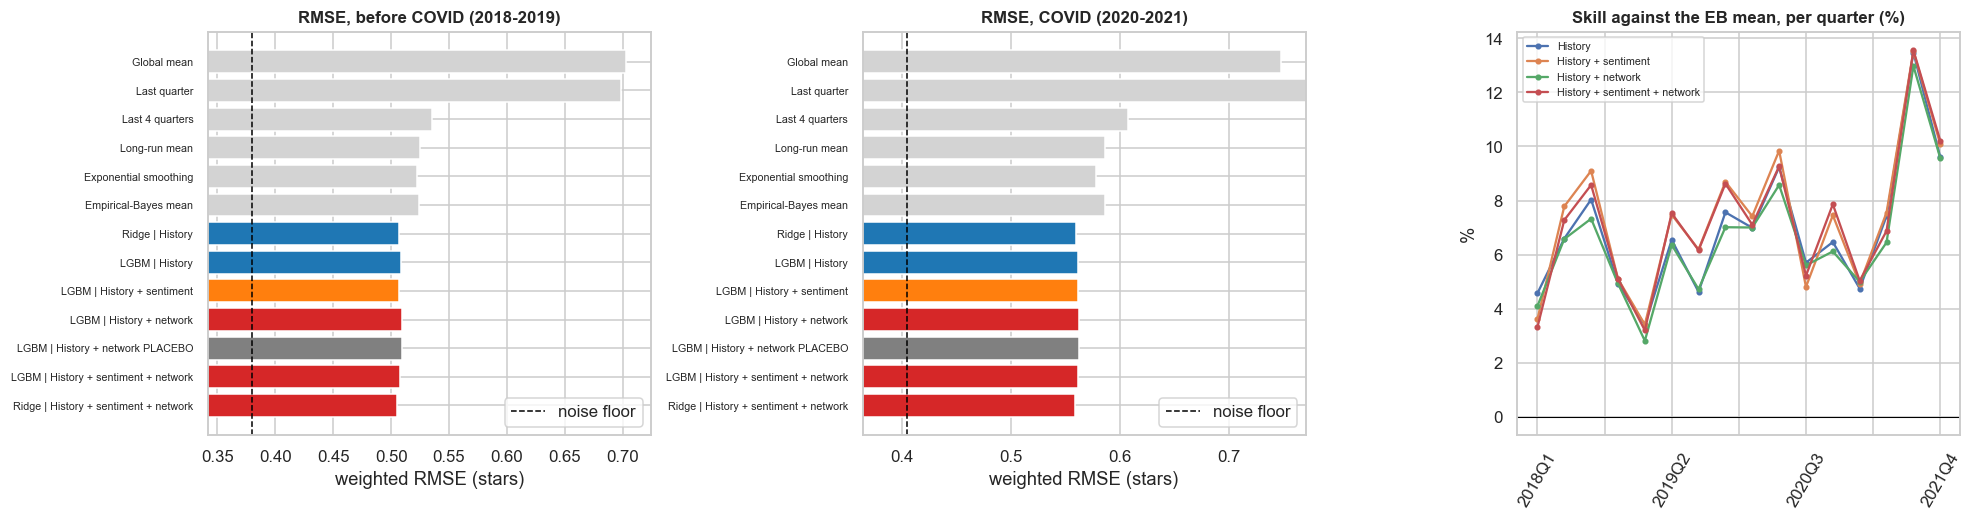

In [35]:
def boot_diff(a, b, df, n=1000, seed=SEED):
    """Bootstrap of the change in weighted MSE, resampling businesses. Negative = a is better than b."""
    ea, eb_ = (df["y"].values - a) ** 2 * df["w"].values, (df["y"].values - b) ** 2 * df["w"].values
    g = pd.DataFrame({"pb": df["pb"].values, "a": ea, "b": eb_, "w": df["w"].values}).groupby("pb").sum()
    A_, B_, W_ = g["a"].values, g["b"].values, g["w"].values
    rng_ = np.random.default_rng(seed)
    out = np.zeros(n)
    for i in range(n):
        ix_ = rng_.integers(0, len(g), len(g))
        out[i] = A_[ix_].sum() / W_[ix_].sum() - B_[ix_].sum() / W_[ix_].sum()
    return (A_.sum() - B_.sum()) / W_.sum(), np.percentile(out, 2.5), np.percentile(out, 97.5), float(2 * min((out >= 0).mean(), (out <= 0).mean()))


COMPARE = [("History", "Empirical-Bayes mean"), ("History + sentiment", "History"), ("History + network", "History"),
           ("History + friendship network only", "History"), ("History + co-review network only", "History"),
           ("History + sentiment + network", "History + sentiment"), ("History + network", "History + network PLACEBO"),
           ("History + sentiment + network", "History + sentiment + network PLACEBO"), ("History + sentiment + network", "History")]
lab = lambda n: n if n == "Empirical-Bayes mean" else f"LGBM | {n}"
rows = []
for period, mask in (("before COVID", WF1["target_t"] <= LAST_PRE_T), ("COVID", WF1["target_t"] > LAST_PRE_T)):
    d = WF1[mask]
    for a, b in COMPARE:
        pa = d[lab(a)].values
        pb_ = d["base"].values if b == "Empirical-Bayes mean" else d[lab(b)].values
        m_, lo, hi, p_ = boot_diff(pa, pb_, d)
        rows.append({"period": period, "comparison": f"{a}  vs  {b}", "MSE change x 1000": 1000 * m_, "CI low": 1000 * lo, "CI high": 1000 * hi, "p": p_,
                     "% of MSE": 100 * m_ / wmse(d["y"], pb_, d["w"])})
RESULTS["panel_ablation_tests"] = pd.DataFrame(rows).set_index(["period", "comparison"])
print("Negative = the first model has the lower error:")
display(RESULTS["panel_ablation_tests"].round(3))

t = RESULTS["panel_h1"].reset_index()
order = ["Global mean", "Last quarter", "Last 4 quarters", "Long-run mean", "Exponential smoothing", "Empirical-Bayes mean", "Ridge | History", "LGBM | History", "LGBM | History + sentiment",
         "LGBM | History + network", "LGBM | History + network PLACEBO", "LGBM | History + sentiment + network", "Ridge | History + sentiment + network"]
fig, ax = plt.subplots(1, 3, figsize=(18, 4.8))
for a_, per in zip(ax[:2], t["period"].unique()):
    x = t[t["period"] == per].set_index("model").reindex(order)
    colors = ["lightgrey" if "|" not in n else ("grey" if "PLACEBO" in n else ("tab:red" if "network" in n else ("tab:orange" if "sentiment" in n else "tab:blue"))) for n in x.index]
    a_.barh(x.index[::-1], x["RMSE"][::-1], color=colors[::-1])
    a_.axvline(x["noise floor RMSE"].iloc[0], color="black", ls="--", lw=1, label="noise floor")
    a_.set_xlim(x["noise floor RMSE"].iloc[0] * .9, x["RMSE"].drop(["Last quarter"]).max() * 1.03); a_.legend()
    a_.set(title=f"RMSE, {per}", xlabel="weighted RMSE (stars)")
    a_.tick_params(axis="y", labelsize=7)
qs = WF1.assign(period=[str(PQ[t_]) for t_ in WF1["target_t"]]).groupby("period")
sk = qs.apply(lambda g: pd.Series({n: 100 * (1 - wmse(g["y"], g[f"LGBM | {n}"], g["w"]) / wmse(g["y"], g["base"], g["w"])) for n in ("History", "History + sentiment", "History + network", "History + sentiment + network")}))
sk.plot(ax=ax[2], marker="o", ms=3); ax[2].axhline(0, color="black", lw=.7); ax[2].legend(fontsize=7); ax[2].tick_params(axis="x", rotation=60)
ax[2].set(title="Skill against the EB mean, per quarter (%)", xlabel="", ylabel="%")
savefig("panel_results")

**Reading the results.**

* **Forecasting works, modestly.** History-based global models cut MSE by about 6 % before COVID and 8 % during COVID against the EB mean. Even so, RMSE (about 0.51 and 0.56) stays well above the noise floor (0.38 and 0.40). The models remove about 12-17 % of the error that could in principle be removed.
* **Linear is enough.** Ridge is as good as LightGBM or better, so nonlinear effects are weak.
* **Sentiment helps a little.** It lowers MSE by 0.7 % before COVID (p = 0.014), and the gain does not hold in the COVID years (p = 0.55).
* **Network inputs do not help.** They slightly *increase* the error (+0.3 %) in both periods, and are not better than the scrambled placebo (p = 0.62 and 0.79). More inputs without signal just add noise.

**Are the network inputs simply broken?** A null result could also come from faulty features, so each one is checked on its own. Below is its correlation with the next-quarter surprise (stars minus the EB mean) within quarters, for the real and the scrambled graph, using only rows before the test period. A real input should be more correlated than its placebo.

The second calculation asks **how large an effect could be expected at all**. It multiplies the conformity effect from Section 5.4 by the share of reviews with a recent friend review and by the typical size of a friend's deviation.

In [36]:
chk = PANEL1[PANEL1["target_t"] < TEST_T[0]]
rows = []
for c_ in NF_COLS + NC_COLS:
    x_ = chk[["resid", c_, "pl_" + c_, "t"]].dropna()
    real = x_[c_] - x_.groupby("t")[c_].transform("mean"); plc = x_["pl_" + c_] - x_.groupby("t")["pl_" + c_].transform("mean")
    res_ = x_["resid"] - x_.groupby("t")["resid"].transform("mean")
    rows.append({"input": c_, "corr, real graph": np.corrcoef(real, res_)[0, 1] if real.std() > 0 else np.nan, "corr, placebo graph": np.corrcoef(plc, res_)[0, 1] if plc.std() > 0 else np.nan, "rows": len(x_)})
RESULTS["network_feature_check"] = pd.DataFrame(rows).set_index("input")
display(RESULTS["network_feature_check"].round(3))

recent = RESULTS["conformity_by_lag"].loc["1-30 days", "friend"]
share_recent = float(((P["lag"] >= 1) & (P["lag"] <= 30)).sum() / (R["prior_n"] >= 5).sum())
sd_dev = float(P.loc[P["lag"].between(1, 30), "x_f"].std())
exp_shift = recent * share_recent * sd_dev
nf_sd = np.sqrt(noise_floor(TEST1))
print(f"Conformity 1-30 days: {recent:.2f} | share of reviews with such a friend review: {share_recent:.2%} | SD of a friend's deviation: {sd_dev:.2f} stars")
print(f"Typical shift of a business's quarterly mean from this channel: about {exp_shift:.4f} stars, against noise of {nf_sd:.2f} stars")

,"corr, real graph","corr, placebo graph",rows
input,,,
net_ld_4q,-0.026,0.000,13596
net_conn_4q,-0.024,0.001,13596
net_exposed_4q,-0.024,0.010,13596
net_pr_stars_gap,-0.031,-0.004,13448
net_top_pr_share,-0.021,-0.017,13596
net_exposed_dev_4q,0.072,0.044,1536
net_friend_mood,-0.012,0.019,10381
net_audience_generosity,0.016,0.016,12924
net_comm_mood,0.024,0.005,13429


Conformity 1-30 days: 0.37 | share of reviews with such a friend review: 1.30% | SD of a friend's deviation: 1.00 stars
Typical shift of a business's quarterly mean from this channel: about 0.0049 stars, against noise of 0.39 stars


**Reading the check.** The features are not broken: several differ clearly from their placebo (for example the `net_ld_4q` correlation of -0.026 against 0.000), but all correlations are tiny. The calculation shows why. Conformity is strong for one person (0.37), but only about 1.3 % of reviews follow a friend's review within 30 days, so the channel shifts a business's quarterly mean by about **0.005 stars, against sampling noise of about 0.39**. A real individual effect can be invisible at the business level. This explains the null result, and it is a finding in itself.

### 8.2 Which inputs matter?

SHAP values show how much each input moves the forecast, from the model trained on all data up to the end of 2019 (fitted on rows before COVID). LightGBM calculates them natively. They describe what the model uses: this is not causality.

,share of SHAP %
Sentiment,57.4
History,37.6
Friendship network,3.4
Co-review network,1.6


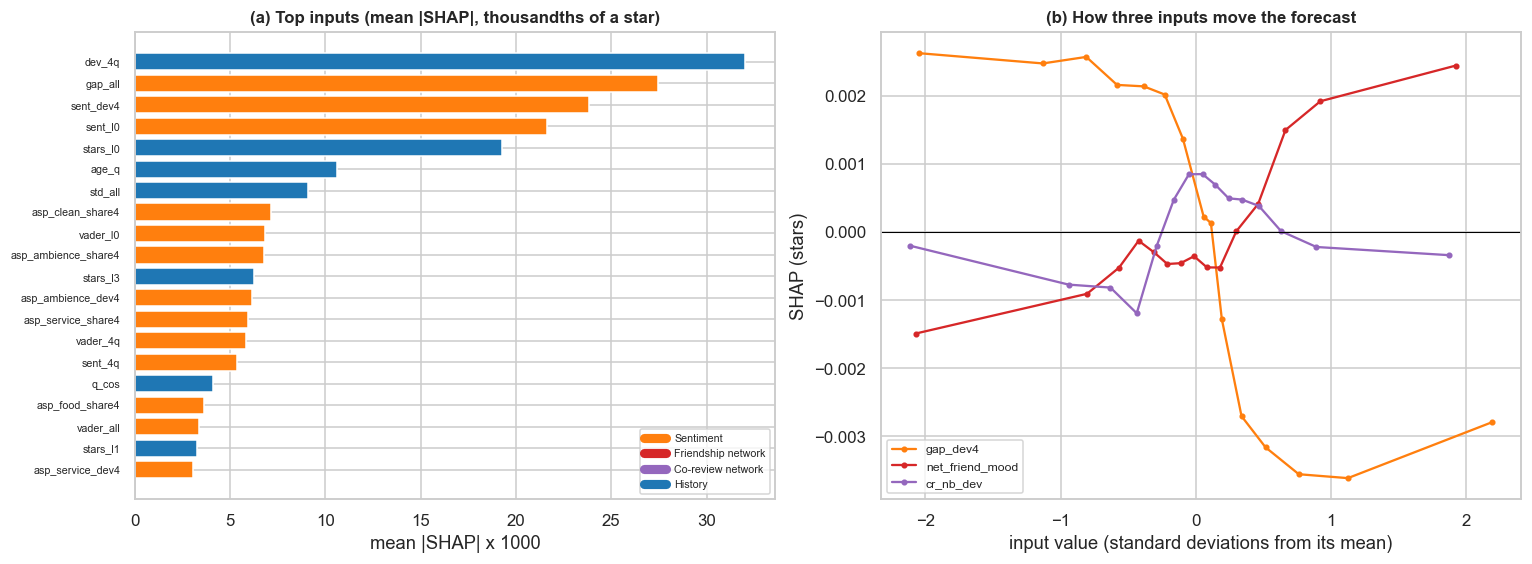

In [37]:
tr = PANEL1[PANEL1["target_t"] <= LAST_PRE_T]
ml = lgb.LGBMRegressor(objective="regression", verbosity=-1, random_state=SEED, n_jobs=LGB_THREADS, subsample=.8, subsample_freq=1, colsample_bytree=.6, **LGB_PARAMS)
ml.fit(tr[ALL_COLS], tr["resid"], sample_weight=tr["w"])
sample = tr.sample(min(8000, len(tr)), random_state=SEED)
sv = ml.booster_.predict(sample[ALL_COLS], pred_contrib=True)[:, :-1]
imp = pd.Series(np.abs(sv).mean(0), index=ALL_COLS).sort_values(ascending=False)
grp_of = lambda c: "Sentiment" if c in S_COLS else ("Friendship network" if c in NF_COLS else ("Co-review network" if c in NC_COLS else "History"))
grp = imp.groupby(imp.index.map(grp_of)).sum()
RESULTS["shap_groups"] = (100 * grp / grp.sum()).round(1).sort_values(ascending=False).to_frame("share of SHAP %")
display(RESULTS["shap_groups"])
col_map = {"Sentiment": "tab:orange", "Friendship network": "tab:red", "Co-review network": "tab:purple", "History": "tab:blue"}
fig, ax = plt.subplots(1, 2, figsize=(14, 5.2))
top = imp.head(20)[::-1]
ax[0].barh(top.index, top.values * 1000, color=[col_map[grp_of(c)] for c in top.index]); ax[0].tick_params(axis="y", labelsize=7)
ax[0].set(title="(a) Top inputs (mean |SHAP|, thousandths of a star)", xlabel="mean |SHAP| x 1000")
for g_, c_ in col_map.items():
    ax[0].plot([], [], color=c_, lw=6, label=g_)
ax[0].legend(fontsize=7, loc="lower right")
for name, col in (("gap_dev4", "tab:orange"), ("net_friend_mood", "tab:red"), ("cr_nb_dev", "tab:purple")):
    k = ALL_COLS.index(name)
    x_ = sample[name].values; ok = np.isfinite(x_)
    bins = pd.qcut(x_[ok], 15, duplicates="drop")
    z = pd.DataFrame({"x": x_[ok], "s": sv[ok, k]}).groupby(bins).mean()
    ax[1].plot((z["x"] - z["x"].mean()) / x_[ok].std(), z["s"], "-o", ms=3, color=col, label=name)
ax[1].axhline(0, color="black", lw=.7); ax[1].legend(fontsize=8)
ax[1].set(title="(b) How three inputs move the forecast", xlabel="input value (standard deviations from its mean)", ylabel="SHAP (stars)")
savefig("panel_shap")

**Reading the SHAP values.** Sentiment inputs take 57 % of the total SHAP, history 38 % and the two network groups 5 %. This looks at odds with the small gain from sentiment in 8.1, but the two questions differ: SHAP shows what a model *uses*, while 8.1 shows what it would *lose*. Sentiment and history are correlated, so the model can largely substitute one for the other.

### 8.3 Does the sentiment-star gap warn of declines?

**Hypothesis.** Suppose that the text in recent reviews of a business is more negative than those reviews' stars. Do its next-quarter stars then fall below what its rating history would predict?

A regression tests this directly, keeping the input interpretable: next-quarter error of the empirical-Bayes mean on the recent gap relative to the business's normal gap, with quarter fixed effects and errors clustered by business. Controls: the recent trend in stars, and the sentiment level. A chart splits businesses into groups by gap.

Without the control for recent stars, the pattern reverses, because a low gap often just follows good recent stars: {0: 0.055, 1: 0.045, 2: -0.002, 3: -0.032, 4: -0.108}


,coef per 1 SD,se,p
gap_dev4,0.0281,0.0084,0.0008
dev_4q,0.1103,0.0082,0.0000


,next-quarter surprise,gap,n
gap_group,,,
0,-0.008,-0.138,3531.0
1,0.010,-0.038,3510.0
2,0.024,0.007,3771.0
3,0.027,0.040,3249.0
4,0.023,0.132,3526.0


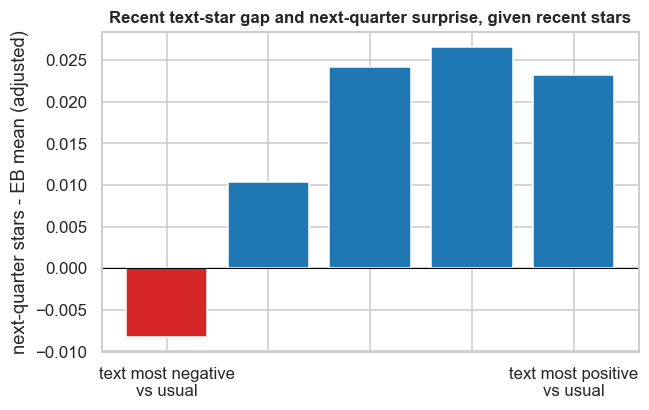

In [38]:
d = PANEL1[PANEL1["target_t"] <= LAST_PRE_T].dropna(subset=["gap_dev4", "dev_4q", "sent_dev4"]).copy()
d = d[d["log_n4"] >= np.log1p(5)]
cols = ["resid", "gap_dev4", "dev_4q"]
W = within(d, cols, ["t"])
Z = W[["gap_dev4", "dev_4q"]] / W[["gap_dev4", "dev_4q"]].std()
m1 = ols_cluster(W["resid"], Z, d["pb"].values)
# the gap moves with recent stars by construction, so groups use the part of the gap not explained by recent stars
b_gd = (W["gap_dev4"] * W["dev_4q"]).sum() / (W["dev_4q"] ** 2).sum()
b_rd = m1.params["dev_4q"] / W["dev_4q"].std()
d["gap_part"] = (W["gap_dev4"] - b_gd * W["dev_4q"]).values
d["surprise_part"] = (W["resid"] - b_rd * W["dev_4q"]).values
d["raw_group"] = d.groupby("t")["gap_dev4"].transform(lambda s: pd.qcut(s, 5, labels=False, duplicates="drop"))
d["gap_group"] = d.groupby("t")["gap_part"].transform(lambda s: pd.qcut(s, 5, labels=False, duplicates="drop"))
g = d.groupby("gap_group").apply(lambda x: pd.Series({"next-quarter surprise": np.average(x["surprise_part"], weights=x["w"]), "gap": x["gap_part"].mean(), "n": len(x)}))
g_raw = d.groupby("raw_group").apply(lambda x: np.average(x["resid"], weights=x["w"]))
print("Without the control for recent stars, the pattern reverses, because a low gap often just follows good recent stars:", g_raw.round(3).to_dict())
RESULTS["gap_regression"] = pd.DataFrame({"coef per 1 SD": m1.params, "se": m1.bse, "p": m1.pvalues}).drop("const")
display(RESULTS["gap_regression"].round(4)); display(g.round(3))
plt.figure(figsize=(6, 3.8))
plt.bar(g.index, g["next-quarter surprise"], color=["tab:red" if v < 0 else "tab:blue" for v in g["next-quarter surprise"]])
plt.axhline(0, color="black", lw=.7); plt.xticks(g.index, ["text most negative\nvs usual"] + [""] * (len(g) - 2) + ["text most positive\nvs usual"])
plt.ylabel("next-quarter stars - EB mean (adjusted)"); plt.title("Recent text-star gap and next-quarter surprise, given recent stars")
savefig("gap_warning")

**Reading the gap test.** The hypothesis holds in a modest form. Given recent stars, text more positive than usual goes with slightly higher stars next quarter, and text more negative goes with lower stars (+0.028 stars per SD, p < 0.001). Words carry information that stars do not, but the effect is small next to recent stars (0.11). Without the control, the pattern reverses, a useful warning against reading the raw chart.

### 8.4 Where does the network help most?

An average can hide differences, so the gain from network inputs is split by business type: how socially exposed the reviewers are, how many reviews the business gets, and its category.

In [39]:
te = TEST1.copy()
te["hist"], te["full"], te["netonly"] = WF1["LGBM | History"].values, WF1["LGBM | History + sentiment + network"].values, WF1["LGBM | History + network"].values
te["sent"] = WF1["LGBM | History + sentiment"].values
te = te[te["target_t"] <= LAST_PRE_T]
te["cat_name"] = biz["macro_cat"].reindex(PANEL_B[te["pb"].values]).values
rows = []
for label, key in (("share of reviewers with a friend who reviewed earlier", pd.qcut(te["net_exposed_4q"].rank(method="first"), 3, labels=["low", "middle", "high"])),
                   ("reviews in the last 4 quarters", pd.qcut(te["log_n4"].rank(method="first"), 3, labels=["low", "middle", "high"])),
                   ("category", te["cat_name"].where(te["cat_name"].isin(["Restaurants", "Nightlife & Bars", "Food (other)"]), "other"))):
    for k_, g_ in te.groupby(key, observed=True):
        e0 = wmse(g_["y"], g_["hist"], g_["w"])
        rows.append({"split by": label, "group": k_, "rows": len(g_), "RMSE (history)": np.sqrt(e0), "network gain %": 100 * (1 - wmse(g_["y"], g_["netonly"], g_["w"]) / e0), "sentiment gain %": 100 * (1 - wmse(g_["y"], g_["sent"], g_["w"]) / e0), "both gain %": 100 * (1 - wmse(g_["y"], g_["full"], g_["w"]) / e0)})
RESULTS["panel_segments"] = pd.DataFrame(rows).set_index(["split by", "group"])
display(RESULTS["panel_segments"].round(2))

rows  \
split by                                           group                    
share of reviewers with a friend who reviewed e... low               1444   
                                                   middle            1444   
                                                   high              1444   
reviews in the last 4 quarters                     low               1445   
                                                   middle            1444   
                                                   high              1445   
category                                           Food (other)       248   
                                                   Nightlife & Bars   207   
                                                   Restaurants       2747   
                                                   other             1132   

                                                                     RMSE (history)  \
split by                                           group                              
share of reviewers with a friend who reviewed e... low                         0.64   
                                                   middle                      0.46   
                                                   high                        0.46   
reviews in the last 4 quarters                     low                         0.79   
                                                   middle                      0.61   
                                                   high                        0.37   
category                                           Food (other)                0.48   
                                                   Nightlife & Bars            0.56   
                                                   Restaurants                 0.46   
                                                   other                       0.69   

                                                                     network gain %  \
split by                                           group                              
share of reviewers with a friend who reviewed e... low                        -0.45   
                                                   middle                     -0.33   
                                                   high                       -0.17   
reviews in the last 4 quarters                     low                        -0.23   
                                                   middle                     -0.28   
                                                   high                       -0.44   
category                                           Food (other)                0.67   
                                                   Nightlife & Bars           -0.25   
                                                   Restaurants                -0.33   
                                                   other                      -0.44   

                                                                     sentiment gain %  \
split by                                           group                                
share of reviewers with a friend who reviewed e... low                           0.53   
                                                   middle                        0.99   
                                                   high                          0.73   
reviews in the last 4 quarters                     low                           1.12   
                                                   middle                        0.36   
                                                   high                          0.69   
category                                           Food (other)                  2.13   
                                                   Nightlife & Bars             -0.77   
                                                   Restaurants                   0.51   
                                                   other                   

**Reading the table.** Network inputs do not help in any segment beyond small differences that could be noise, including businesses where the most reviewers have friends who reviewed earlier. "Food (other)" shows +0.7 %, among the many groups tested, so this should not be over-read.

### 8.5 Where the network does help: individual ratings and review volume

If the channel is too thin to move a business's quarterly mean, it might still appear in two other places, which are tested with the same discipline (train on the past, test on the future, placebo).

**(a) One person's next rating.** For reviews preceded by a friend's review of the same business (at least one day before), we train before 2018 and test on 2018-2019. Does knowing what the friend said reduce the error, beyond the business's mean and the user's generosity? The placebo is a matched non-friend's review of the same business.

**(b) Next-quarter review volume.** The same panel and walk-forward design, with `log(1 + reviews next quarter)` as the target. The models start from the mean of the last 4 quarters, the strongest simple baseline. If friends affect *where people go*, this is where the network should matter.

In [40]:
Pf = P[P["lag"] >= 1].copy()
Pf["date"] = R.loc[Pf["rid"].values, "date"].values
Pf["recent"] = (Pf["lag"] <= 30).astype(float)
Pf["x_f_recent"] = Pf["x_f"] * Pf["recent"]; Pf["x_n_recent"] = Pf["x_n"] * Pf["recent"]
Pf_tr, Pf_te = Pf[Pf["date"] < "2018-01-01"], Pf[(Pf["date"] >= "2018-01-01") & (Pf["date"] < REC_TEST_END)]
SPEC = {"Business mean": ["pm"], "+ user generosity": ["pm", "len_v"], "+ non-friend's rating (placebo)": ["pm", "len_v", "x_n", "x_n_recent"], "+ friend's rating": ["pm", "len_v", "x_f", "x_f_recent", "len_f"],
        "+ both": ["pm", "len_v", "x_n", "x_n_recent", "x_f", "x_f_recent", "len_f"]}
pred_ind, rows = {}, []
for name, cols_ in SPEC.items():
    fit = sm.OLS(Pf_tr["y"], sm.add_constant(Pf_tr[cols_])).fit()
    pred_ind[name] = np.clip(fit.predict(sm.add_constant(Pf_te[cols_], has_constant="add")).values, 1, 5)
    for grp, mask in (("all friends", np.ones(len(Pf_te), bool)), ("friend within 30 days", Pf_te["recent"].values == 1)):
        rows.append({"inputs": name, "reviews": grp, "RMSE": np.sqrt(np.mean((Pf_te["y"].values[mask] - pred_ind[name][mask]) ** 2)), "n": int(mask.sum())})
RESULTS["individual_forecast"] = pd.DataFrame(rows).pivot(index="inputs", columns="reviews", values="RMSE").reindex(list(SPEC))
display(RESULTS["individual_forecast"].round(4))


def boot_user(a, b, df, n=1000):
    g = pd.DataFrame({"u": df["u"].values, "d": (df["y"].values - a) ** 2 - (df["y"].values - b) ** 2}).groupby("u")["d"].agg(["sum", "size"])
    rng_ = np.random.default_rng(SEED)
    bs = [g["sum"].values[i_].sum() / g["size"].values[i_].sum() for i_ in (rng_.integers(0, len(g), len(g)) for _ in range(n))]
    return g["sum"].sum() / g["size"].sum(), np.percentile(bs, 2.5), np.percentile(bs, 97.5)


rows = []
for a_, b_ in (("+ friend's rating", "+ user generosity"), ("+ non-friend's rating (placebo)", "+ user generosity"), ("+ friend's rating", "+ non-friend's rating (placebo)")):
    m_, lo, hi = boot_user(pred_ind[a_], pred_ind[b_], Pf_te)
    rows.append({"comparison": f"{a_} vs {b_}", "MSE change": m_, "CI low": lo, "CI high": hi, "reviews": len(Pf_te)})
RESULTS["individual_forecast_tests"] = pd.DataFrame(rows).set_index("comparison")
display(RESULTS["individual_forecast_tests"].round(4))

reviews,all friends,friend within 30 days
inputs,,
Business mean,1.0297,0.9567
+ user generosity,1.0013,0.9456
+ non-friend's rating (placebo),1.0012,0.9423
+ friend's rating,0.9871,0.8641
+ both,0.9872,0.8618


,MSE change,CI low,CI high,reviews
comparison,,,,
+ friend's rating vs + user generosity,-0.0282,-0.0398,-0.0164,6992
+ non-friend's rating (placebo) vs + user generosity,-0.0001,-0.0014,0.0013,6992
+ friend's rating vs + non-friend's rating (placebo),-0.0281,-0.0395,-0.0166,6992


In [41]:
def compute_volume():
    D = prepare(1, min_target=0)
    D["yv"] = np.log1p(D["w"])
    last_year = np.full((nB, nQ), np.nan); last_year[:, 3:] = N[:, :nQ - 3]             # the same quarter as the target, one year earlier
    D["base_v"] = np.log1p(last_year[D["pb"].values, D["t"].values])
    D = D.dropna(subset=["base_v"]).reset_index(drop=True)
    D["mean4"] = np.log1p((np.exp(D["log_n4"]) - 1) / 4)                               # the strongest simple baseline
    D["y"], D["w"], D["base"], D["resid"] = D["yv"], 1.0, D["mean4"], D["yv"] - D["mean4"]
    out = pd.DataFrame({"pb": D["pb"], "target_t": D["target_t"], "y": D["y"], "w": D["w"], "base": D["base_v"], "mean4": D["mean4"]})
    for name in ("History", "History + sentiment", "History + network", "History + friendship network only", "History + co-review network only", "History + network PLACEBO"):
        out[name] = walk_forward(D, FEATURE_SETS[name], "lgb", LGB_PARAMS)
    return out


WV = cached("walk_forward_volume", compute_volume).dropna(subset=["History"]).reset_index(drop=True)
rows, tests = [], []
for period, mask in (("before COVID", WV["target_t"] <= LAST_PRE_T), ("COVID", WV["target_t"] > LAST_PRE_T)):
    d_ = WV[mask]
    for name in ("base", "mean4", "History", "History + sentiment", "History + network", "History + friendship network only", "History + co-review network only", "History + network PLACEBO"):
        rows.append({"period": period, "model": {"base": "Same quarter last year", "mean4": "Mean of the last 4 quarters"}.get(name, f"LGBM | {name}"), "MAE (log)": np.mean(np.abs(d_["y"] - d_[name])), "RMSE (log)": np.sqrt(np.mean((d_["y"] - d_[name]) ** 2))})
    for a_, b_ in (("History", "mean4"), ("History + network", "History"), ("History + friendship network only", "History"), ("History + co-review network only", "History"), ("History + network", "History + network PLACEBO"), ("History + network PLACEBO", "History")):
        m_, lo, hi, p_ = boot_diff(d_[a_].values, d_[b_].values, d_)
        tests.append({"period": period, "comparison": f"{a_}  vs  {b_}", "MSE change x 1000": 1000 * m_, "CI low": 1000 * lo, "CI high": 1000 * hi, "p": p_, "% of MSE": 100 * m_ / np.mean((d_["y"] - d_[b_]) ** 2)})
RESULTS["volume_forecast"] = pd.DataFrame(rows).set_index(["period", "model"]); RESULTS["volume_forecast_tests"] = pd.DataFrame(tests).set_index(["period", "comparison"])
display(RESULTS["volume_forecast"].round(4)); display(RESULTS["volume_forecast_tests"].round(3))

MAE (log)  RMSE (log)
period       model                                                          
before COVID Same quarter last year                       0.4964      0.7281
             Mean of the last 4 quarters                  0.4013      0.5781
             LGBM | History                               0.3754      0.5208
             LGBM | History + sentiment                   0.3751      0.5209
             LGBM | History + network                     0.3762      0.5211
             LGBM | History + friendship network only     0.3757      0.5207
             LGBM | History + co-review network only      0.3758      0.5207
             LGBM | History + network PLACEBO             0.3762      0.5214
COVID        Same quarter last year                       0.5217      0.7752
             Mean of the last 4 quarters                  0.4128      0.6057
             LGBM | History                               0.4005      0.5666
             LGBM | History + sentiment                   0.4011      0.5670
             LGBM | History + network                     0.4017      0.5673
             LGBM | History + friendship network only     0.4008      0.5663
             LGBM | History + co-review network only      0.4014      0.5668
             LGBM | History + network PLACEBO             0.4006      0.5666

MSE change x 1000  \
period       comparison                                                            
before COVID History  vs  mean4                                          -62.942   
             History + network  vs  History                                0.289   
             History + friendship network only  vs  History               -0.132   
             History + co-review network only  vs  History                -0.165   
             History + network  vs  History + network PLACEBO             -0.296   
             History + network PLACEBO  vs  History                        0.584   
COVID        History  vs  mean4                                          -45.836   
             History + network  vs  History                                0.812   
             History + friendship network only  vs  History               -0.390   
             History + co-review network only  vs  History                 0.145   
             History + network  vs  History + network PLACEBO              0.870   
             History + network PLACEBO  vs  History                       -0.058   

                                                               CI low  \
period       comparison                                                 
before COVID History  vs  mean4                               -75.012   
             History + network  vs  History                    -0.319   
             History + friendship network only  vs  History    -0.578   
             History + co-review network only  vs  History     -0.691   
             History + network  vs  History + network PLACEBO  -0.887   
             History + network PLACEBO  vs  History             0.158   
COVID        History  vs  mean4                               -55.957   
             History + network  vs  History                     0.110   
             History + friendship network only  vs  History    -0.914   
             History + co-review network only  vs  History     -0.499   
             History + network  vs  History + network PLACEBO   0.133   
             History + network PLACEBO  vs  History            -0.603   

                                                               CI high      p  \
period       comparison                                                         
before COVID History  vs  mean4                                -52.141  0.000   
             History + network  vs  History                      0.832  0.346   
             History + friendship network only  vs  History      0.268  0.532   
             History + co-review network only  vs  History       0.340  0.528   
             History + network  vs  History + network PLACEBO    0.250  0.308   
             History + network PLACEBO  vs  History              0.986  0.012   
COVID        History  vs  mean4                                -35.795  0.000   
             History + network  vs  History                      1.494  0.022   
             History + friendship network only  vs  History      0.116  0.118   
             History + co-review network only  vs  History       0.811  0.686   
             History + network  vs  History + network PLACEBO    1.600  0.014   
             History + network PLACEBO  vs  History              0.487  0.774   

                                                               % of MSE  
period       comparison                                                  
before COVID History  vs  mean4                                 -18.833  
             History + network  vs  History                       0.106  
             History + friendship network only  vs  History      -0.049  
             History + co-review network only  vs  History       -0.061  
             History + network  vs  History + network PLACEBO    -0.109  
             History + network PLACEBO  vs  History               0.215  
COVID        History  vs  mean4                                 -12.492  
             History + network  vs  History                   

**Reading the results.**

* **(a) Individual ratings: the network does help.** Adding the friend's rating lowers RMSE from 1.001 to 0.987 overall, and from 0.946 to 0.864 when the friend's review is under 30 days old. The matched non-friend adds nothing (MSE change -0.0001, CI includes 0), and the difference between them is significant. This is a true out-of-time result, but recent cases may include joint visits, and the friendship snapshot may contain ties formed after the reviews.
* **(b) Review volume: no network gain.** Global models beat the mean of the last 4 quarters by 19 % and 12 % in MSE, while network inputs add nothing (+0.1 %, p = 0.35 before COVID) and do slightly worse during COVID (+0.25 %, p = 0.02). The chosen inputs do not capture whatever friends do to visits at the business level.

**Integration, in one sentence:** friends' opinions help to predict *a person's* rating, but they are too rare and too small to improve the forecast of *a business's* average or volume.

## 9. Extensions

### 9.1 Influencer event study

**Question.** When a highly connected user reviews a business for the first time, do its later stars, sentiment and review volume change, compared with similar businesses?

**Why not a simple before/after comparison?** Influencers choose where to go, and they may choose places already on the rise. So each event is matched with up to 3 **control businesses**, in the same category and the same quarter, that have not been reviewed by this type of influencer through the following 4 quarters, chosen for the most similar level and trend in stars and the most similar level and trend in volume over the 8 previous quarters.

* **Influencer types:** *top PageRank* (top 1 % among users with friends) and *Elite at the time of the review*.
* **Events:** the first such review of a business from 2012 through 2019Q1, so that the window ends before COVID, for businesses with at least 10 earlier reviews and with reviews in at least 3 of the 4 earlier quarters.
* **Outcomes:** the stars, sentiment and log review volume of **other** reviewers (all reviews by this influencer type are excluded, for treated and controls alike), per quarter.
* **Estimate:** difference-in-differences relative to the mean of the 4 quarters before; confidence intervals from a bootstrap over events.
* **Check:** quarters before the event should show no effect. If they do, the design has failed to find comparable controls. Since an extra pre-event trend can remain even after matching, a second estimate measures the post-event change **beyond the straight line through the pre-event path**.

--- Top-PageRank user: balance before the event


,treated: stars level,controls: stars level,treated: log recent reviews,controls: log recent reviews,treated: stars trend,controls: stars trend,treated: volume trend,controls: volume trend
0,3.983,3.936,2.559,2.434,0.021,0.001,0.724,0.529


--- Elite user: balance before the event


,treated: stars level,controls: stars level,treated: log recent reviews,controls: log recent reviews,treated: stars trend,controls: stars trend,treated: volume trend,controls: volume trend
0,4.032,4.141,2.343,2.185,-0.003,-0.044,0.706,0.458


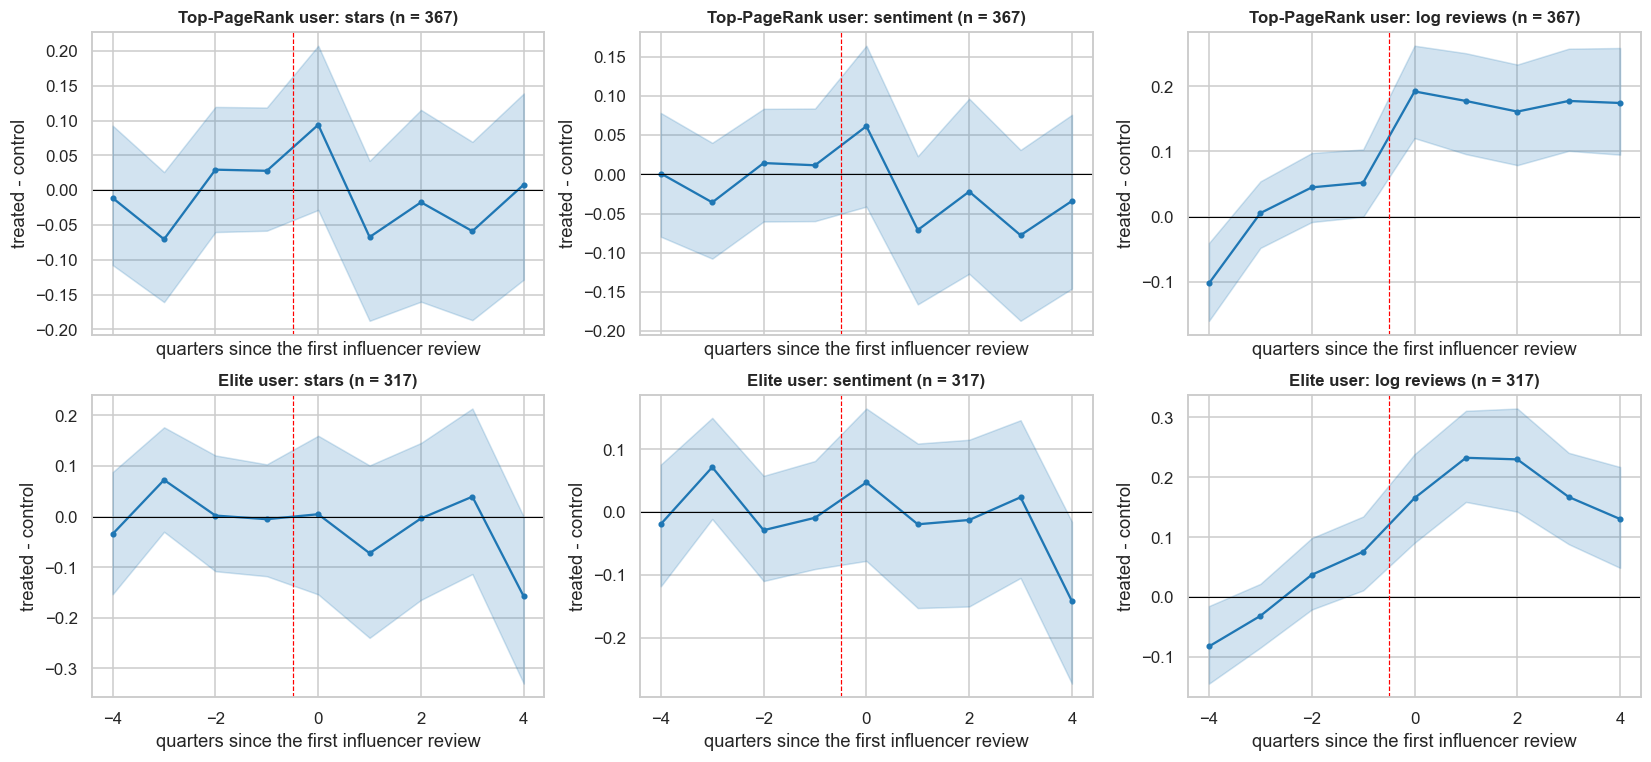

,influencer,events,post_effect,CI_low,CI_high,pre_slope_per_quarter,beyond_pre_trend,beyond_low,beyond_high,largest |pre-event difference|
outcome,,,,,,,,,,
stars,Top-PageRank user,367,-0.032,-0.129,0.047,0.022,-0.136,-0.402,0.114,0.071
sentiment,Top-PageRank user,367,-0.063,-0.134,0.011,0.008,-0.090,-0.297,0.096,0.036
log reviews,Top-PageRank user,367,0.173,0.115,0.227,0.050,-0.079,-0.231,0.076,0.102
stars,Elite user,317,-0.060,-0.170,0.049,0.002,-0.066,-0.355,0.225,0.073
sentiment,Elite user,317,-0.053,-0.141,0.033,-0.007,-0.006,-0.268,0.239,0.071
log reviews,Elite user,317,0.190,0.132,0.249,0.054,-0.081,-0.242,0.092,0.082


In [42]:
ALLQ = pd.period_range("2008Q1", "2021Q4", freq="Q")
aqi = {p: i for i, p in enumerate(ALLQ)}
Rq = R[(R["q"] >= ALLQ[0]) & (R["q"] <= ALLQ[-1])].copy()
Rq["qi"] = Rq["q"].map(aqi).astype(int)
pr_rank = NODES["pagerank"].rank(pct=True)
TOP_PR = set(pr_rank[pr_rank >= .99].index)
Rq["inf_pr"] = Rq["u"].isin(TOP_PR)
Rq["inf_elite"] = Rq["elite_now"]
nBa, nQa = len(biz), len(ALLQ)


def event_study(flag, k_before=4, k_after=4, n_controls=3, seed=SEED):
    other = Rq[~Rq[flag]]
    def grid(col=None):
        M = np.zeros((nBa, nQa))
        np.add.at(M, (other["b"].values, other["qi"].values), 1.0 if col is None else other[col].fillna(other[col].mean()).values)
        return M
    Nn, Ss, Tt = grid(), grid("stars"), grid("sent_lr")
    Nall = np.zeros((nBa, nQa)); np.add.at(Nall, (Rq["b"].values, Rq["qi"].values), 1.0)
    first = Rq[Rq[flag]].groupby("b")["qi"].min()
    first_all = pd.Series(10 ** 6, index=np.arange(nBa)); first_all.update(first)
    cum = np.cumsum(Nall, 1)
    star = safe(Ss, Nn); sent = safe(Tt, Nn); logn = np.log1p(Nn)
    cat_codes = biz["macro_cat"].astype("category").cat.codes.values
    events = []
    lo_q, hi_q = aqi[pd.Period("2012Q1", "Q")], aqi[pd.Period("2019Q1", "Q")]
    def describe(b_, q0):
        n8, s8 = Nn[b_, max(0, q0 - 8):q0], Ss[b_, max(0, q0 - 8):q0]
        n4, s4 = Nn[b_, max(0, q0 - 4):q0], Ss[b_, max(0, q0 - 4):q0]
        n_old, s_old = n8[:-4], s8[:-4]
        lvl = s8.sum() / max(n8.sum(), 1); rec = s4.sum() / max(n4.sum(), 1); old = s_old.sum() / max(n_old.sum(), 1) if n_old.sum() else rec
        return lvl, np.log1p(n4.sum()), rec - old, np.log1p(n4.sum()) - np.log1p(n_old.sum())
    # the feature matrix of every business by quarter is computed once per quarter and category
    for b_, q0 in first.items():
        if not (lo_q <= q0 <= hi_q) or q0 < 4:
            continue
        if cum[b_, q0 - 1] < 10 or (Nn[b_, q0 - 4:q0] > 0).sum() < 3:
            continue
        pool = np.flatnonzero((cat_codes == cat_codes[b_]) & (first_all.values > q0 + k_after) & (cum[:, q0 - 1] >= 10) & ((Nn[:, q0 - 4:q0] > 0).sum(1) >= 3))
        pool = pool[pool != b_]
        if len(pool) < n_controls:
            continue
        me = np.array(describe(b_, q0))
        feats = np.array([describe(c_, q0) for c_ in pool])
        sc = feats.std(0) + 1e-6
        dist = (((feats - me) / sc) ** 2).sum(1)
        ctrl = pool[np.argsort(dist)[:n_controls]]
        events.append((b_, q0, ctrl, float(np.sqrt(dist[np.argsort(dist)[:n_controls]]).mean()), me, feats[np.argsort(dist)[:n_controls]].mean(0)))
    window = np.arange(-k_before, k_after + 1)
    out = {}
    for name, M, is_rate in (("stars", star, True), ("sentiment", sent, True), ("log reviews", logn, False)):
        deltas = np.full((len(events), len(window)), np.nan)
        for e_, (b_, q0, ctrl, *_rest) in enumerate(events):
            t_ = M[b_, q0 + window].astype(float)
            c_ = np.nanmean(M[ctrl][:, q0 + window], axis=0)
            pre_t = np.nanmean(t_[:k_before]); pre_c = np.nanmean(c_[:k_before])
            deltas[e_] = (t_ - pre_t) - (c_ - pre_c)
        out[name] = deltas
    balance = pd.DataFrame({"treated": np.mean([e[4] for e in events], 0), "controls": np.mean([e[5] for e in events], 0)}, index=["stars level", "log recent reviews", "stars trend", "volume trend"])
    return out, window, balance, len(events)


def summarise_event(out, window, n_boot=1000, seed=SEED):
    rng_ = np.random.default_rng(seed)
    rows = []
    for name, dd in out.items():
        n = dd.shape[0]
        boots = np.array([np.nanmean(dd[rng_.integers(0, n, n)], axis=0) for _ in range(n_boot)])
        post_i = window >= 1; pre_i = window < 0
        pm = np.nanmean(dd[:, post_i], axis=1)
        boot_post = np.array([np.nanmean(pm[rng_.integers(0, n, n)]) for _ in range(n_boot)])

        def beyond_trend(x):
            """Post-event mean above the straight line through the mean pre-event path."""
            path = np.nanmean(x, axis=0)
            slope, icpt = np.polyfit(window[pre_i], path[pre_i], 1)
            return np.mean(path[post_i] - (icpt + slope * window[post_i])), slope
        bt, slope = beyond_trend(dd)
        boot_bt = np.array([beyond_trend(dd[rng_.integers(0, n, n)])[0] for _ in range(n_boot)])
        for k_, v_, lo, hi in zip(window, np.nanmean(dd, axis=0), np.percentile(boots, 2.5, axis=0), np.percentile(boots, 97.5, axis=0)):
            rows.append({"outcome": name, "k": k_, "att": v_, "lo": lo, "hi": hi, "post_mean": np.nanmean(pm), "post_lo": np.percentile(boot_post, 2.5), "post_hi": np.percentile(boot_post, 97.5),
                         "pre_slope": slope, "beyond_trend": bt, "beyond_lo": np.percentile(boot_bt, 2.5), "beyond_hi": np.percentile(boot_bt, 97.5)})
    return pd.DataFrame(rows)


fig, ax = plt.subplots(2, 3, figsize=(15, 7), sharex=True)
tbls = []
for r_i, (flag, label) in enumerate((("inf_pr", "Top-PageRank user"), ("inf_elite", "Elite user"))):
    def _run():
        o_, w_, bal_, n_ = event_study(flag)
        s_ = summarise_event(o_, w_)
        s_["events"] = n_
        for k_, row in bal_.iterrows():
            s_[f"treated: {k_}"] = row["treated"]; s_[f"controls: {k_}"] = row["controls"]
        return s_
    es = cached(f"event_{flag}", _run)
    for a_, (name, g_) in zip(ax[r_i], es.groupby("outcome", sort=False)):
        a_.fill_between(g_["k"], g_["lo"], g_["hi"], alpha=.2, color="tab:blue"); a_.plot(g_["k"], g_["att"], "-o", ms=3, color="tab:blue")
        a_.axhline(0, color="black", lw=.7); a_.axvline(-.5, color="red", ls="--", lw=.8)
        a_.set(title=f"{label}: {name} (n = {int(g_['events'].iloc[0]):,})", xlabel="quarters since the first influencer review", ylabel="treated - control")
    x_ = es.groupby("outcome", sort=False).agg(events=("events", "first"), post_effect=("post_mean", "first"), CI_low=("post_lo", "first"), CI_high=("post_hi", "first"),
                                               pre_slope_per_quarter=("pre_slope", "first"), beyond_pre_trend=("beyond_trend", "first"), beyond_low=("beyond_lo", "first"), beyond_high=("beyond_hi", "first"))
    pre_t_ = es[es["k"] < 0].groupby("outcome", sort=False)["att"].agg(lambda s: s.abs().max())
    x_["largest |pre-event difference|"] = pre_t_
    x_.insert(0, "influencer", label)
    tbls.append(x_)
    print(f"--- {label}: balance before the event")
    display(es.filter(like=":").iloc[[0]].T.round(3).T)
savefig("event_study")
RESULTS["event_study"] = pd.concat(tbls)
display(RESULTS["event_study"].round(3))

**Reading the event study.**

* **Stars and sentiment: no detectable effect** for either type of influencer (for example, top PageRank: -0.03 stars, CI -0.13 to +0.05). Pre-event differences are small, so this null is credible. Positive effects above about 0.05 stars can be ruled out.
* **Volume: the simple result misleads.** After the event, the log review count rises by about 0.17-0.19 relative to the controls (CI excludes 0). But **the difference was already growing before the event** (0.05 per quarter), even with matching on the volume trend. Measured beyond that trend, the estimate is -0.08 with a CI that includes 0. The most likely reading is reverse causation: places with growing attention attract their first influencer, not the other way round. **We therefore find no evidence that influencers lift volume.**
* **Balance.** Matching improved comparability but did not make it perfect (treated volume trend about 0.71, controls about 0.5), which reinforces this caution.

### 9.2 COVID recovery and the network

**Question.** Did well-connected businesses and communities recover faster, and did what people complain about change differently between communities?

**Business level.** The network position of each business is measured **before COVID**, using only 2018-2019 reviews, so it cannot be a result of the recovery. Outcomes: the log ratio of reviews in 2021 to 2019, and the change in mean stars. Regressions control for category, city, prior volume and prior stars.

**Community level (only a handful of units, so descriptive).** The 2021 review volume relative to 2019, against how connected the community was before COVID.

**Aspect sentiment.** Within-business change in sentiment for each aspect, comparing the two years before March 2020 with the time after. Fixed effects by business exclude changes in which businesses are reviewed. A Cochran Q test checks whether communities differ more than chance would explain.

effect per 1 SD  \
outcome                   network measure (pre-COVID)                            
reviews 2021 / 2019 (log) mean log friends of reviewers                 -0.131   
                          share of reviewers with friends               -0.108   
                          share of reviewers with 20+ friends           -0.114   
                          share of Elite reviewers                       0.032   
                          co-review centrality (2019)                   -0.103   
stars 2021 - pre-COVID    mean log friends of reviewers                 -0.036   
                          share of reviewers with friends               -0.043   
                          share of reviewers with 20+ friends           -0.021   
                          share of Elite reviewers                      -0.004   
                          co-review centrality (2019)                   -0.037   

                                                                  se      p  \
outcome                   network measure (pre-COVID)                         
reviews 2021 / 2019 (log) mean log friends of reviewers        0.048  0.007   
                          share of reviewers with friends      0.045  0.017   
                          share of reviewers with 20+ friends  0.048  0.019   
                          share of Elite reviewers             0.052  0.530   
                          co-review centrality (2019)          0.076  0.171   
stars 2021 - pre-COVID    mean log friends of reviewers        0.026  0.155   
                          share of reviewers with friends      0.027  0.105   
                          share of reviewers with 20+ friends  0.026  0.426   
                          share of Elite reviewers             0.027  0.890   
                          co-review centrality (2019)          0.043  0.386   

                                                               businesses  \
outcome                   network measure (pre-COVID)                       
reviews 2021 / 2019 (log) mean log friends of reviewers               876   
                          share of reviewers with friends             876   
                          share of reviewers with 20+ friends         876   
                          share of Elite reviewers                    876   
                          co-review centrality (2019)                 876   
stars 2021 - pre-COVID    mean log friends of reviewers               775   
                          share of reviewers with friends             775   
                          share of reviewers with 20+ friends         775   
                          share of Elite reviewers                    775   
                          co-review centrality (2019)                 775   

                                                               p_holm  
outcome                   network measure (pre-COVID)                  
reviews 2021 / 2019 (log) mean log friends of reviewers         0.067  
                          share of reviewers with friends       0.153  
                          share of reviewers with 20+ friends   0.153  
                          share of Elite reviewers              1.000  
                          co-review centrality (2019)           0.929  
stars 2021 - pre-COVID    mean log friends of reviewers         0.929  
                          share of reviewers with friends       0.736  
                          share of reviewers with 20+ friends   1.000  
                          share of Elite reviewers              1.000  
                          co-review centrality (2019)           1.000

,volume 2021 / 2019,stars 2021 - 2019,reviews 2019,mean log degree (2018-2019 reviewers),"local share (2018-19, more than 2 reviews)"
community,,,,,
C0,0.637,-0.003,5993,2.490,0.202
C4,0.803,0.140,4712,2.293,0.298
C1,0.913,0.111,1894,2.588,0.183
C2,0.985,0.154,1635,1.929,0.179
C5,0.712,0.108,2238,2.572,0.150
C3,0.822,-0.072,1278,1.412,0.078


Spearman, connectivity against recovery across 6 communities: rho = -0.26, p = 0.623 (descriptive only)


,food,service,price,ambience,wait,clean
All,-0.015,-0.012,-0.017,-0.021,-0.025,-0.025
C0,-0.007,-0.016,-0.033,-0.022,-0.036,-0.027
C1,-0.001,0.004,0.006,-0.029,-0.015,-0.080
C2,0.005,-0.005,-0.011,-0.028,-0.034,0.009
C3,-0.029,-0.010,-0.100,-0.048,0.001,0.084
C4,-0.005,0.010,0.008,-0.008,-0.042,-0.022
C5,-0.017,-0.033,0.037,-0.019,-0.025,0.056


,Cochran Q,p,p_holm
food,4.576,0.470,1.000
service,5.748,0.332,1.000
price,14.862,0.011,0.066
ambience,2.355,0.798,1.000
wait,3.656,0.600,1.000
clean,4.438,0.488,1.000


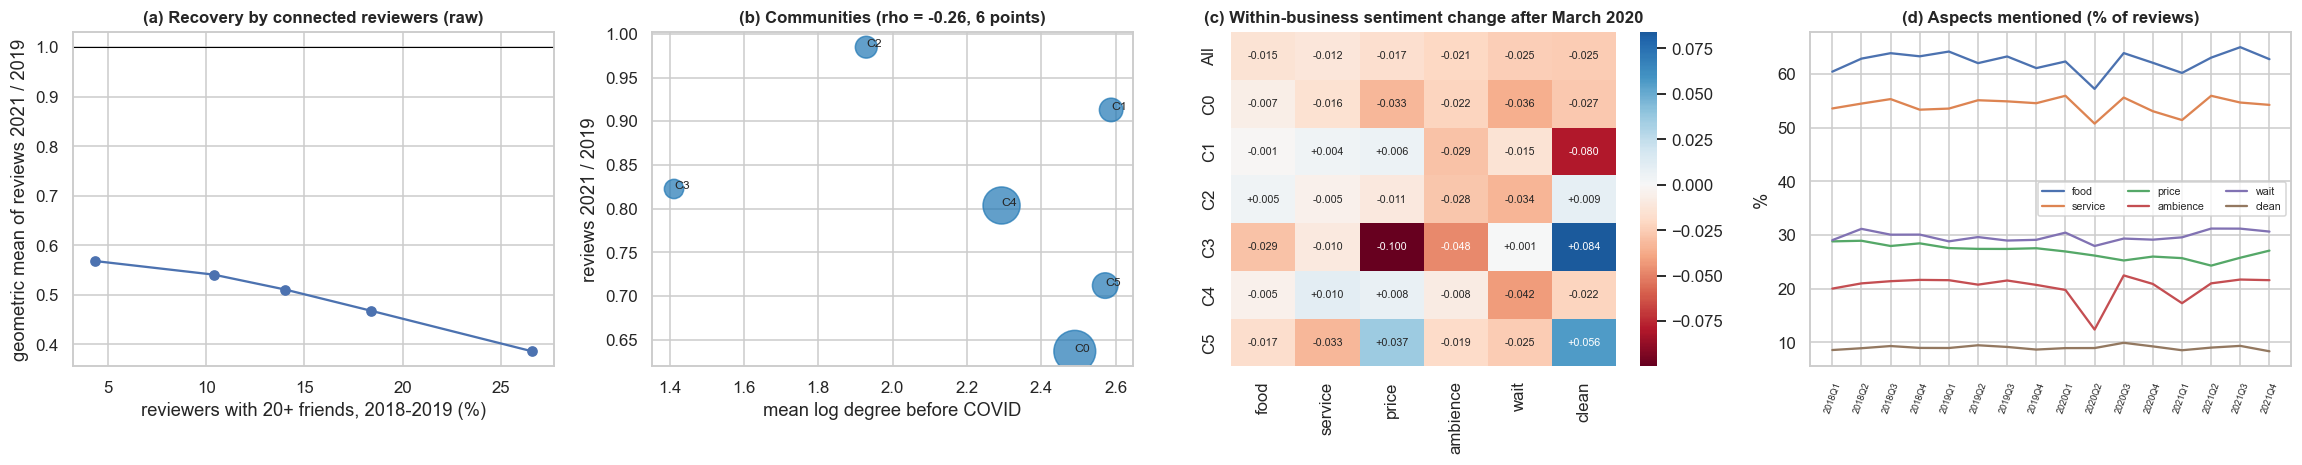

In [43]:
pre_win = R[(R["date"] >= "2018-01-01") & (R["date"] < "2020-01-01")].copy()
pre_win["logdeg"] = np.log1p(pre_win["deg"]); pre_win["conn"] = (pre_win["deg"] > 0).astype(float); pre_win["hub"] = (pre_win["deg"] >= 20).astype(float)
b19 = pre_win.groupby("b").agg(n_pre=("stars", "size"), stars_pre=("stars", "mean"), logdeg=("logdeg", "mean"), conn=("conn", "mean"), hub=("hub", "mean"), elite=("elite_now", "mean"))
post21 = R[R["year"] == 2021].groupby("b").agg(n_21=("stars", "size"), stars_21=("stars", "mean"))
n19 = R[R["year"] == 2019].groupby("b").size().rename("n_19")
Bq = b19.join(post21).join(n19)
Bq = Bq[Bq["n_pre"] >= 20].copy()
Bq[["n_21", "n_19"]] = Bq[["n_21", "n_19"]].fillna(0)
Bq["log_recovery"] = np.log((Bq["n_21"] + .5) / (Bq["n_19"] + .5))
Bq["d_stars"] = Bq["stars_21"] - Bq["stars_pre"]
Bq["coreview_centrality"] = np.log(BIZ_PR[2019][Bq.index] * len(biz) + 1e-3)
Bq["cat"] = biz["macro_cat"].reindex(Bq.index).values; Bq["city"] = biz["city"].reindex(Bq.index).values
Bq["log_n_pre"] = np.log(Bq["n_pre"])
measures = {"mean log friends of reviewers": "logdeg", "share of reviewers with friends": "conn", "share of reviewers with 20+ friends": "hub", "share of Elite reviewers": "elite", "co-review centrality (2019)": "coreview_centrality"}
import statsmodels.formula.api as smf
rows = []
for outcome, dd in (("log_recovery", Bq), ("d_stars", Bq.dropna(subset=["d_stars"]))):
    for lbl, col in measures.items():
        dd2 = dd.assign(z=(dd[col] - dd[col].mean()) / dd[col].std())
        m_ = smf.ols(f"{outcome} ~ z + log_n_pre + stars_pre + C(cat) + C(city)", data=dd2).fit(cov_type="HC1")
        rows.append({"outcome": {"log_recovery": "reviews 2021 / 2019 (log)", "d_stars": "stars 2021 - pre-COVID"}[outcome], "network measure (pre-COVID)": lbl, "effect per 1 SD": m_.params["z"], "se": m_.bse["z"], "p": m_.pvalues["z"], "businesses": int(m_.nobs)})
cr = pd.DataFrame(rows)
cr["p_holm"] = multipletests(cr["p"], method="holm")[1]
RESULTS["covid_business"] = cr.set_index(["outcome", "network measure (pre-COVID)"])
display(RESULTS["covid_business"].round(3))

# ---- communities: volume recovery against connectivity -----------------------------------------------------------------
rows = []
for c in top_comm:
    g_ = R[R["community"] == c]
    rows.append({"community": f"C{c}", "volume 2021 / 2019": (g_["year"] == 2021).sum() / (g_["year"] == 2019).sum(), "stars 2021 - 2019": g_[g_["year"] == 2021]["stars"].mean() - g_[g_["year"] == 2019]["stars"].mean(),
                 "reviews 2019": int((g_["year"] == 2019).sum()), "mean log degree (2018-2019 reviewers)": np.log1p(g_[g_["year"].isin([2018, 2019])]["deg"]).mean(), "local share (2018-19, more than 2 reviews)": (g_[g_["year"].isin([2018, 2019])].groupby("u").size() > 2).mean()})
comm_cov = pd.DataFrame(rows).set_index("community")
RESULTS["covid_community"] = comm_cov
display(comm_cov.round(3))
rho, p_rho = stats.spearmanr(comm_cov["mean log degree (2018-2019 reviewers)"], comm_cov["volume 2021 / 2019"])
print(f"Spearman, connectivity against recovery across {len(comm_cov)} communities: rho = {rho:.2f}, p = {p_rho:.3f} (descriptive only)")

# ---- aspect shifts ------------------------------------------------------------------------------------------------------
win2 = R[(R["date"] >= "2018-03-01") & (R["date"] <= LAST_FULL_MONTH) & R["is_en"]].copy()
win2["post"] = (win2["date"] >= COVID_START).astype(float)
groups = {"All": win2, **{f"C{c}": win2[win2["community"] == c] for c in top_comm}}
est, se_ = {}, {}
for name, d_ in groups.items():
    for a_ in ASP_COLS:
        x_ = d_.dropna(subset=[a_])
        x_ = x_[x_.groupby("b")["post"].transform("nunique") == 2]
        W_ = within(x_, [a_, "post"], ["b"])
        m_ = ols_cluster(W_[a_], W_[["post"]], x_["b"].values)
        est[(name, a_[4:])] = m_.params["post"]; se_[(name, a_[4:])] = m_.bse["post"]
est = pd.Series(est).unstack()[ASPECTS]; se_ = pd.Series(se_).unstack()[ASPECTS]
het = {}
for a_ in ASPECTS:
    b_ = est.drop("All")[a_]; w_ = 1 / se_.drop("All")[a_] ** 2
    Q_ = (w_ * (b_ - (w_ * b_).sum() / w_.sum()) ** 2).sum()
    het[a_] = {"Cochran Q": Q_, "p": stats.chi2.sf(Q_, len(b_) - 1)}
het = pd.DataFrame(het).T
het["p_holm"] = multipletests(het["p"], method="holm")[1]
RESULTS["covid_aspect_shift"] = est; RESULTS["covid_aspect_heterogeneity"] = het
display(est.round(3)); display(het.round(3))
ment_a = R[(R["date"] >= "2018-01-01") & (R["date"] <= LAST_FULL_MONTH)].assign(**{a: lambda x, a=a: x[f"asp_{a}"].notna() for a in ASPECTS}).groupby("q")[ASPECTS].mean() * 100

fig, ax = plt.subplots(1, 4, figsize=(21, 4.3))
pl = Bq.assign(z=pd.qcut(Bq["hub"].rank(method="first"), 5, labels=False)).groupby("z").agg(x=("hub", "mean"), y=("log_recovery", "mean"))
ax[0].plot(pl["x"] * 100, np.exp(pl["y"]), "-o"); ax[0].axhline(1, color="black", lw=.7)
ax[0].set(title="(a) Recovery by connected reviewers (raw)", xlabel="reviewers with 20+ friends, 2018-2019 (%)", ylabel="geometric mean of reviews 2021 / 2019")
ax[1].scatter(comm_cov["mean log degree (2018-2019 reviewers)"], comm_cov["volume 2021 / 2019"], s=comm_cov["reviews 2019"] / 8, color="tab:blue", alpha=.7)
for n_, r_ in comm_cov.iterrows():
    ax[1].annotate(n_, (r_["mean log degree (2018-2019 reviewers)"], r_["volume 2021 / 2019"]), fontsize=8)
ax[1].set(title=f"(b) Communities (rho = {rho:.2f}, {len(comm_cov)} points)", xlabel="mean log degree before COVID", ylabel="reviews 2021 / 2019")
sns.heatmap(est, annot=True, fmt="+.3f", cmap="RdBu", center=0, annot_kws={"size": 7}, ax=ax[2]); ax[2].set_title("(c) Within-business sentiment change after March 2020")
for a_ in ASPECTS:
    ax[3].plot([str(p) for p in ment_a.index], ment_a[a_], label=a_)
ax[3].tick_params(axis="x", rotation=70, labelsize=6); ax[3].legend(fontsize=7, ncol=3); ax[3].set(title="(d) Aspects mentioned (% of reviews)", ylabel="%")
savefig("covid_network")

**Reading the COVID results.**

* **Well-connected businesses did not recover faster.** If anything the opposite holds: 1 SD more connected reviewers goes with about 12 % lower 2021 volume relative to 2019 (p = 0.007), which does not survive the Holm correction (0.067). Panel (a) shows the same pattern in the raw data. A plausible explanation is that highly connected reviewers were more often frequent Yelp users or visitors, who decreased their activity, but the data cannot confirm it. Nothing shows up for stars.
* **Communities** (6 points) show no clear relation either (rho = -0.26, p = 0.62).
* **Aspect sentiment** fell slightly within businesses for all aspects (-0.01 to -0.03). Communities do not differ reliably: no Cochran Q test survives the correction, with price nearest (0.066). Some large cells (such as C3 on price) come from small samples.
* **Mentions.** Panel (d) shows ambience mentions falling sharply in spring 2020 (dining rooms closed) and returning. This is a clean signal that the aspect measure reacts to real events.

### 9.3 Why did a rating change? Change points and aspects

For each business with at least 200 reviews, we look for the single moment when its mean stars shifted the most: the split of its review sequence that maximises a t-like statistic, with at least 30 reviews on each side. Scanning for the best split finds something even in pure noise, so significance comes from **permutation tests** (500 shuffles of the same reviews) with a **false discovery rate** correction across businesses.

For each detected break, the change in the aspects tells a story: does a drop go together with worse service, food or wait? A cross-business regression shows which aspect changes best explain changes in stars.

Businesses tested: 397 | with a significant break (FDR 5 %): 121 (30%) | falls: 68 | rises: 53 | median size 0.69 stars
R2 of the change in stars on aspect changes: 0.84


,stars per 1 SD of aspect change,se,p
food,0.128,0.063,0.043
service,0.471,0.052,0.000
price,0.146,0.032,0.000
ambience,0.009,0.035,0.787
wait,0.032,0.044,0.461
clean,0.018,0.041,0.657


,business,category,break,stars before,stars after,largest drop,drop in sentiment
0,Foxtail Kitchen & Bar,Restaurants,2021-05,4.34,2.71,clean,-0.78
1,Bagel Cafe,Restaurants,2021-06,3.96,2.62,service,-0.38
2,Best Western Plus Pepper Tree Inn,Hotels & Travel,2019-12,3.61,2.30,clean,-0.53
3,Hana Kitchen,Restaurants,2016-10,4.18,2.92,service,-0.58
4,The Habit Burger Grill,Restaurants,2018-09,4.00,2.77,service,-0.46


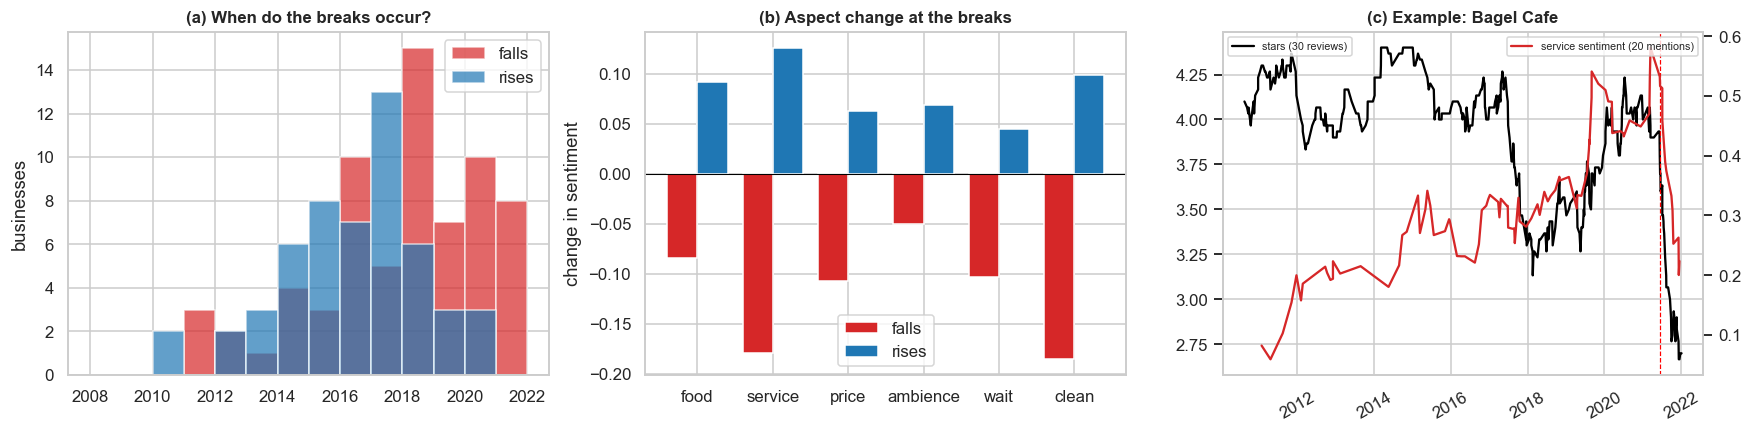

In [44]:
def cusum_stat(x, min_seg=30):
    n = len(x)
    c = np.cumsum(x)
    k = np.arange(min_seg, n - min_seg + 1)
    left = c[k - 1] / k
    right = (c[-1] - c[k - 1]) / (n - k)
    return np.abs(left - right) * np.sqrt(k * (n - k) / n), k


def detect_break(x, n_perm=500, seed=0):
    rng_ = np.random.default_rng(seed)
    t_, k_ = cusum_stat(x)
    obs = t_.max(); pos = int(k_[t_.argmax()])
    perm = np.array([cusum_stat(rng_.permutation(x))[0].max() for _ in range(n_perm)])
    return pos, obs / x.std(), float((1 + (perm >= obs).sum()) / (n_perm + 1))


def compute_breaks():
    big = R["b"].value_counts()
    big = big[big >= 200].index.values
    d = R[R["b"].isin(big) & (R["date"] <= LAST_FULL_MONTH)].sort_values(["b", "date"])
    groups_ = [(b_, g["stars"].values.astype(float)) for b_, g in d.groupby("b")]
    res_ = Parallel(n_jobs=N_JOBS)(delayed(detect_break)(x, 500, i) for i, (b_, x) in enumerate(groups_))
    rows = []
    for (b_, x), (pos, st, p_) in zip(groups_, res_):
        g = d[d["b"] == b_]
        bef, aft = g.iloc[:pos], g.iloc[pos:]
        row = {"b": b_, "n": len(x), "pos": pos, "stat": st, "p": p_, "date": g["date"].iloc[pos], "stars_before": bef["stars"].mean(), "stars_after": aft["stars"].mean(), "d_sent": aft["sent_lr"].mean() - bef["sent_lr"].mean()}
        for a_ in ASP_COLS:
            row[f"d_{a_}"] = aft[a_].mean() - bef[a_].mean()
        rows.append(row)
    return pd.DataFrame(rows)


BR = cached("change_points", compute_breaks)
BR["q_fdr"] = multipletests(BR["p"], method="fdr_bh")[1]
BR["d_stars"] = BR["stars_after"] - BR["stars_before"]
sig = BR[BR["q_fdr"] < .05].copy()
print(f"Businesses tested: {len(BR)} | with a significant break (FDR 5 %): {len(sig)} ({len(sig) / len(BR):.0%}) | falls: {(sig['d_stars'] < 0).sum()} | rises: {(sig['d_stars'] > 0).sum()} | median size {sig['d_stars'].abs().median():.2f} stars")
sig[[f"d_{a}" for a in ASP_COLS]] = sig[[f"d_{a}" for a in ASP_COLS]].fillna(0)
Xc = sig[[f"d_{a}" for a in ASP_COLS]]; Xs = Xc / Xc.std()
m_br = sm.OLS(sig["d_stars"], sm.add_constant(Xs)).fit(cov_type="HC1")
RESULTS["break_aspects"] = pd.DataFrame({"stars per 1 SD of aspect change": m_br.params, "se": m_br.bse, "p": m_br.pvalues}).drop("const").rename(index=lambda s: s[6:])
print(f"R2 of the change in stars on aspect changes: {m_br.rsquared:.2f}")
display(RESULTS["break_aspects"].round(3))

names = biz.set_index("b")
cases = sig.sort_values("d_stars").head(5)
example = cases[[r_[[f"d_{a}" for a in ASP_COLS]].astype(float).idxmin() == "d_asp_service" for _, r_ in cases.iterrows()]].iloc[0]
rows = []
for _, r_ in cases.iterrows():
    a_ch = r_[[f"d_{a}" for a in ASP_COLS]].astype(float)
    rows.append({"business": names.loc[int(r_["b"]), "name"], "category": names.loc[int(r_["b"]), "macro_cat"], "break": f"{r_['date']:%Y-%m}", "stars before": r_["stars_before"], "stars after": r_["stars_after"],
                 "largest drop": a_ch.idxmin()[6:], "drop in sentiment": a_ch.min()})
RESULTS["break_cases"] = pd.DataFrame(rows)
display(RESULTS["break_cases"].round(2))

fig, ax = plt.subplots(1, 3, figsize=(16, 4))
bins = pd.date_range("2008-01-01", "2022-01-01", freq="YS")
ax[0].hist(sig.loc[sig["d_stars"] < 0, "date"], bins=bins, alpha=.7, label="falls", color="tab:red"); ax[0].hist(sig.loc[sig["d_stars"] > 0, "date"], bins=bins, alpha=.7, label="rises", color="tab:blue")
ax[0].legend(); ax[0].set(title="(a) When do the breaks occur?", ylabel="businesses")
falls = sig[sig["d_stars"] < 0][[f"d_{a}" for a in ASP_COLS]].mean(); rises = sig[sig["d_stars"] > 0][[f"d_{a}" for a in ASP_COLS]].mean()
x_ = np.arange(len(ASPECTS))
ax[1].bar(x_ - .2, falls.values, .4, color="tab:red", label="falls"); ax[1].bar(x_ + .2, rises.values, .4, color="tab:blue", label="rises")
ax[1].set_xticks(x_); ax[1].set_xticklabels(ASPECTS); ax[1].axhline(0, color="black", lw=.7); ax[1].legend(); ax[1].set(title="(b) Aspect change at the breaks", ylabel="change in sentiment")
worst = int(example["b"]); gw = R[R["b"] == worst].set_index("date").sort_index()
ax[2].plot(gw["stars"].rolling(30).mean(), label="stars (30 reviews)", color="black"); ax3 = ax[2].twinx(); ax3.grid(False)
aw = "asp_service"
ax3.plot(gw[aw].dropna().rolling(20, min_periods=8).mean(), color="tab:red", label="service sentiment (20 mentions)"); ax[2].axvline(example["date"], color="red", ls="--", lw=.8)
ax[2].legend(loc="upper left", fontsize=7); ax3.legend(loc="upper right", fontsize=7); ax[2].set(title=f"(c) Example: {names.loc[worst, 'name']}"); ax[2].tick_params(axis="x", rotation=30)
savefig("change_points")

**Reading the change points.** About 30 % of the businesses tested show a significant shift (121 of 397), slightly more falls than rises, with a median size of 0.69 stars. Changes in **service** sentiment explain star changes best (0.47 per SD, against 0.15 for price and 0.13 for food), in line with Section 4.5. The high R² (0.84) partly comes from text and stars being written together, so this describes the breaks and does not explain their cause. Falls in 2020-2021 stand out in panel (a). The test assumes a single break, and a slow drift can also be flagged as one. The businesses listed show a rating shift in the data, which says nothing about why it happened.

### 9.4 Do reviews trigger reviews? A self-exciting model

In a self-exciting (Hawkes-type) process, each event temporarily raises the rate of later events. Here the discrete version is a Poisson regression for each business's weekly review count, with a separate effect for **who** wrote last week's reviews:

`log E[reviews this week] = log(business baseline) + month effects + a1 × hubs last week + a2 × connected users last week + a3 × unconnected users last week + (the same for 2-4 weeks ago)`

The baseline is the business's mean weekly count between 5 and 52 weeks before, so slow trends do not count as excitation. Both a real trigger and a shared demand shock (a local event, a holiday) raise the counts, so the **level** of excitation does not prove influence. The informative part is the **contrast**: if network ties transmit reviews, the effect should be larger after a review by a well-connected user than after one from an unconnected user. Businesses: at least 100 reviews before 2018. Weeks: 2013-2019.

Business-weeks: 163,981; businesses: 499


,rate ratio per extra review,CI low,CI high,p
last week: 20+ friends,1.0353,1.0213,1.0495,0.0000
last week: 1-19 friends,1.0211,1.0123,1.0300,0.0000
last week: no friends,1.0166,1.0033,1.0301,0.0140
2-4 weeks ago: 20+ friends,1.0223,1.0116,1.0330,0.0000
2-4 weeks ago: 1-19 friends,1.0084,1.0022,1.0145,0.0075
2-4 weeks ago: no friends,0.9965,0.9928,1.0001,0.0555


,difference in log rate,p
last week: 20+ friends vs no friends,0.0182,0.0860
last week: 1-19 friends vs no friends,0.0044,0.4863
2-4 weeks ago: 20+ friends vs no friends,0.0256,0.0000


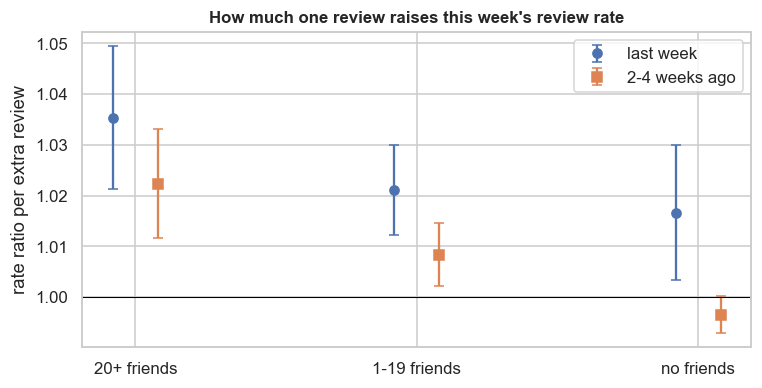

In [45]:
def compute_hawkes():
    big = early[early >= 100].index.values
    d = R[R["b"].isin(big) & (R["date"] >= "2012-01-01") & (R["date"] < "2020-01-01")].copy()
    d["wk"] = ((d["date"] - pd.Timestamp("2012-01-02")).dt.days // 7).astype(int)
    d = d[d["wk"] >= 0]
    d["pb2"] = pd.Series(np.arange(len(big)), index=big).reindex(d["b"].values).values
    nw = d["wk"].max() + 1
    def wgrid(mask):
        M = np.zeros((len(big), nw)); np.add.at(M, (d["pb2"].values[mask], d["wk"].values[mask]), 1.0)
        return M
    hub = wgrid((d["deg"] >= 20).values); low = wgrid(((d["deg"] > 0) & (d["deg"] < 20)).values); iso = wgrid((d["deg"] == 0).values)
    tot = hub + low + iso
    def lagged(M, a, b):
        c = np.cumsum(np.c_[np.zeros(len(M)), M], 1)
        out = np.full(M.shape, np.nan)
        out[:, b:] = c[:, b - a + 1:nw - a + 1] - c[:, :nw - b]
        return out
    base = lagged(tot, 5, 52) / 48
    frame = {"y": tot.ravel(), "base": base.ravel()}
    for name, M in (("hub", hub), ("low", low), ("iso", iso)):
        frame[f"{name}_1"] = lagged(M, 1, 1).ravel(); frame[f"{name}_24"] = lagged(M, 2, 4).ravel()
    pb_, wk_ = np.meshgrid(np.arange(len(big)), np.arange(nw), indexing="ij")
    frame["pb"] = pb_.ravel(); frame["wk"] = wk_.ravel()
    D = pd.DataFrame(frame).dropna()
    D = D[D["base"] > 0]
    return D


HK = cached("hawkes_panel", compute_hawkes)
HK["month"] = ((pd.Timestamp("2012-01-02") + pd.to_timedelta(HK["wk"] * 7, unit="D")).dt.month).astype(int)
Xh = HK[["hub_1", "low_1", "iso_1", "hub_24", "low_24", "iso_24"]].astype(float)
Xh = pd.concat([Xh, pd.get_dummies(HK["month"], prefix="m", drop_first=True).astype(float)], axis=1)
Xh = sm.add_constant(Xh)
mh = sm.GLM(HK["y"].values, Xh, family=sm.families.Poisson(), offset=np.log(HK["base"].values)).fit(cov_type="cluster", cov_kwds={"groups": HK["pb"].values})
tb = pd.DataFrame({"rate ratio per extra review": np.exp(mh.params), "CI low": np.exp(mh.params - 1.96 * mh.bse), "CI high": np.exp(mh.params + 1.96 * mh.bse), "p": mh.pvalues}).loc[["hub_1", "low_1", "iso_1", "hub_24", "low_24", "iso_24"]]
tb.index = ["last week: 20+ friends", "last week: 1-19 friends", "last week: no friends", "2-4 weeks ago: 20+ friends", "2-4 weeks ago: 1-19 friends", "2-4 weeks ago: no friends"]
RESULTS["self_excitation"] = tb
print(f"Business-weeks: {len(HK):,}; businesses: {HK['pb'].nunique()}")
display(tb.round(4))
t1 = mh.t_test("hub_1 - iso_1 = 0"); t2 = mh.t_test("low_1 - iso_1 = 0"); t3 = mh.t_test("hub_24 - iso_24 = 0")
RESULTS["self_excitation_contrasts"] = pd.DataFrame({"difference in log rate": [float(t1.effect[0]), float(t2.effect[0]), float(t3.effect[0])], "p": [float(t1.pvalue), float(t2.pvalue), float(t3.pvalue)]},
                                                    index=["last week: 20+ friends vs no friends", "last week: 1-19 friends vs no friends", "2-4 weeks ago: 20+ friends vs no friends"])
display(RESULTS["self_excitation_contrasts"].round(4))
plt.figure(figsize=(7, 3.6))
plt.errorbar(np.arange(3) - .08, tb["rate ratio per extra review"].iloc[:3], [tb.iloc[:3, 0] - tb["CI low"].iloc[:3], tb["CI high"].iloc[:3] - tb.iloc[:3, 0]], fmt="o", capsize=3, label="last week")
plt.errorbar(np.arange(3) + .08, tb["rate ratio per extra review"].iloc[3:], [tb.iloc[3:, 0] - tb["CI low"].iloc[3:], tb["CI high"].iloc[3:] - tb.iloc[3:, 0]], fmt="s", capsize=3, label="2-4 weeks ago")
plt.xticks(range(3), ["20+ friends", "1-19 friends", "no friends"]); plt.axhline(1, color="black", lw=.7); plt.legend(); plt.ylabel("rate ratio per extra review")
plt.title("How much one review raises this week's review rate")
savefig("self_excitation")

**Reading the model.** All types of review raise next week's rate, as expected from shared demand. The informative part is the contrast. One more review last week by a user with 20+ friends goes with about 3.5 % more reviews this week, against 1.7 % for an unconnected user (difference p = 0.09). At 2-4 weeks the contrast is clearer: +2.2 % against about 0 % (p < 0.001). This suggests **a longer-lasting echo after reviews from well-connected users**, in line with the visit test in 5.4. Still, connected users may simply be earlier in choosing places that are about to become popular. The effect per review is small, which agrees with the lack of gain in the volume forecast of 8.5.

## 10. Conclusions

### Answer to the main question

**Star ratings can be forecast modestly, and text adds a little. The social network adds nothing to a business-level forecast, even though friends' ratings clearly help to predict one person's rating.**

| Question | Result | How strong is the evidence? |
|---|---|---|
| Can a business's next-quarter stars be forecast? | Yes, modestly: about 6-9 % lower MSE than a strong baseline; much of the remaining error is sampling noise | Strong (walk-forward, 16 quarters) |
| Does sentiment help? | A little: 0.7 % lower MSE before COVID; no reliable gain during COVID | Moderate |
| Does the network help the business-level forecast? | No: not better than a scrambled network, at any tested horizon of the main comparison | Strong null, with an explanation: the channel shifts a quarterly mean by about 0.005 stars |
| Do friends' ratings predict one person's rating? | Yes: RMSE 0.946 -> 0.864 for friends' reviews under 30 days old; placebo has no effect | Strong for prediction; cause unknown (influence, joint visits, shared tastes) |
| Do people go where friends went? | Odds ratio 4.5 within 30 days, fading with time | Strong association, matched on activity and city |
| Do first reviews by influencers change a business? | Stars and sentiment no; the volume rise was already under way before the event | Credible null for stars; volume likely reverse causation |
| Did connected businesses recover faster from COVID? | No; if anything slower, not significant after correction | Moderate |
| What explains ratings and their sharp changes? | Service, above all, in every category | Descriptive, consistent in two analyses |
| Does the text warn of later changes? | Modestly: +0.028 stars per SD of the sentiment-star gap, given recent stars | Moderate (p < 0.001, small effect) |
| What is the best recommender? | Hybrid without network: NDCG@10 0.042 against 0.034 for popularity, about a third of the catalogue covered against 1 %; friends lower NDCG slightly and do not fix cold start | Moderate: beats popularity reliably; lead over Implicit ALS is borderline |

### What this means in practice

* **For a business:** the content of reviews is more useful than the network of reviewers, and service sentiment is the first thing to watch. Sentiment that is falling behind stars is a small warning sign.
* **For a platform:** a friend's recent rating is a useful signal when predicting what one person will think, but friendship data does not improve a recommender here. Popularity and visit patterns do most of the work.
* **For the analysis of social influence:** an effect can be strong for individuals and invisible in aggregates, if few people are exposed. Testing only one level would give a misleading answer in either direction.

### Limitations

* **Friendship is an undated snapshot** from the end of the data, so some ties may have formed after the reviews studied. This can overstate the network's value. The null at business level is therefore conservative, while the individual-level gain may be somewhat optimistic.
* **Influence is not identified.** Observational data cannot fully separate influence from homophily and joint visits. Placebos, matching and timing narrow down the options without settling the question.
* **Yelp's sample.** The data are a part of Yelp, and "California" is really the Santa Barbara area, with many visitors. Results may not transfer elsewhere. Friends outside the area are missing, so exposure is undercounted.
* **Ratings are self-selected** and may be filtered by Yelp, so stars do not measure the quality of a business directly.
* **Text methods.** The transformers ran on samples without fine-tuning, for lack of a GPU. VADER aspect scores are weak for wait and price (Section 4.4).
* **Many tests.** Corrections were applied within each main family of tests, but not over the whole notebook. Isolated p-values near 0.05 should be read as weak evidence.

### Next steps

Fine-tune a transformer on Yelp with a GPU and rerun aspect sentiment on all sentences. Look for quasi-random exposure (for example, a friend's review appearing near the top of a page) for a more causal test. Use the dated co-review graph for a recommender free from look-ahead through friendship.

In [46]:
out_dir = Path("modelling_results_final"); out_dir.mkdir(exist_ok=True)
saved = []
for name, table in RESULTS.items():
    pd.DataFrame(table).to_csv(out_dir / f"{name}.csv")
    saved.append(name)
print(f"Saved {len(saved)} result tables to {out_dir}/ and {len(list(FIG.glob('*.png')))} figures to {FIG}/")
print(", ".join(saved))

Saved 44 result tables to modelling_results_final/ and 16 figures to figures_acd/
text_preprocessing, sentiment_benchmark, nmf_topics, absa_check, aspect_drivers, assortativity, community_profile, centrality_spearman, conformity_by_lag, conformity_fof, case_control_visits, mood_contagion, yearly_coreview_network, rec_rating, rec_ranking, rec_tests, rec_by_history, rec_cold_start, ts_stationarity, ts_community_backtest, ts_overall_backtest, ts_community_dm, granger, panel_baselines, panel_h1, panel_horizons, panel_ablation_tests, network_feature_check, shap_groups, gap_regression, panel_segments, individual_forecast, individual_forecast_tests, volume_forecast, volume_forecast_tests, event_study, covid_business, covid_community, covid_aspect_shift, covid_aspect_heterogeneity, break_aspects, break_cases, self_excitation, self_excitation_contrasts
